In [9]:
import sys
import os
import clr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import warnings
import unittest
import json
import requests
import traceback
import math
import seaborn as sns

warnings.filterwarnings('ignore')
sys.path.append(r'C:\Program Files (x86)\PIPC\AF\PublicAssemblies\4.0')
clr.AddReference('OSIsoft.AFSDK')
clr.AddReference('System.Net')

from OSIsoft import AF
from OSIsoft.AF import *
from OSIsoft.AF.PI import *
from OSIsoft.AF.Asset import *
from OSIsoft.AF.Data import *
from OSIsoft.AF.Time import *
from OSIsoft.AF.UnitsOfMeasure import *
from System.Net import *
from IPython.display import display, clear_output

from threading import Thread
from itertools import product
from datetime import datetime, timedelta

In [10]:
!pip install pythonnet

# PIDSK Extraction Functions

In [11]:
def connect_to_server(serverName,username,password):
    global piServer
    
    try:
        credential = NetworkCredential(username,password)
        piServers = PIServers()
        piServer = piServers[serverName]
        piServer.Connect(credential)
        print("Connection Successful")
        
    except Exception as e:
        print("An error occurred:")
        print(str(e.args))

In [12]:
connect_to_server('pimaceo','pidemo','')

Connection Successful


In [13]:
def get_interpolated_values(start_date, end_date, frequency, tag):

    PItag = PIPoint.FindPIPoint(piServer, tag)
    date_range = AFTimeRange(start_date,end_date)
    span = AFTimeSpan.Parse(frequency)
    data = PItag.InterpolatedValues(date_range, span, "", False)

    return data

In [14]:
def get_recorded_values(start_date, end_date, tag):
    PItag = PIPoint.FindPIPoint(piServer, tag)
    date_range = AFTimeRange(start_date,end_date)
    boundaryType = AF.Data.AFBoundaryType.Inside
    data = PItag.RecordedValues(date_range, boundaryType, "", False, 50000)

    return data

In [15]:
def PI_to_dataframe(data, dataframe,tag,n):

    values = []

    if n == 0:
        time = []
        for value in data:
            # print(value.IsGood == True)
            if value.IsGood == True:
                time.append(str(value.Timestamp))
                values.append(value.Value)
            else:
                time.append(str(value.Timestamp))
                values.append(np.nan)

        dataframe['Time'] = time
        dataframe[tag] = values

    else:
        for value in data:
            if value.IsGood == True:
                values.append(value.Value)
            else:
                values.append(np.nan)

        dataframe[tag] = values

    return dataframe

In [16]:
def hour_rounder(t):
    return (t.replace(second=0, microsecond=0, minute=0, hour=t.hour) + timedelta(hours=t.minute//30))

# MOLINO CEMENTO 6

Datos cargados para FC_610053.TPC: 429120 filas
Datos cargados para JI_62023.TPC: 429120 filas
Datos cargados para JI_62233.TPC: 429120 filas
Datos cargados para JI_62113.TPC: 429120 filas
Datos cargados para FC_61143.TPC: 429120 filas

Filas en operative_data: 429120
                   Time  FC_610053.TPC  JI_62023.TPC  JI_62233.TPC  \
0  1/1/2025 12:00:00 AM       0.098970      0.000547     11.066314   
1  1/1/2025 12:02:00 AM       0.083977      0.000534     11.063821   
2  1/1/2025 12:04:00 AM       0.098489      0.000521     11.061327   
3  1/1/2025 12:06:00 AM       0.099920      0.000509     11.058833   
4  1/1/2025 12:08:00 AM       0.100000      0.000496     11.056340   

   JI_62113.TPC  FC_61143.TPC  
0      5.630761           0.0  
1      5.630260           0.0  
2      5.629760           0.0  
3      5.629260           0.0  
4      5.628759           0.0  

Valores nulos:
Time                 0
FC_610053.TPC     5143
JI_62023.TPC     12710
JI_62233.TPC      1471
JI_62113.T

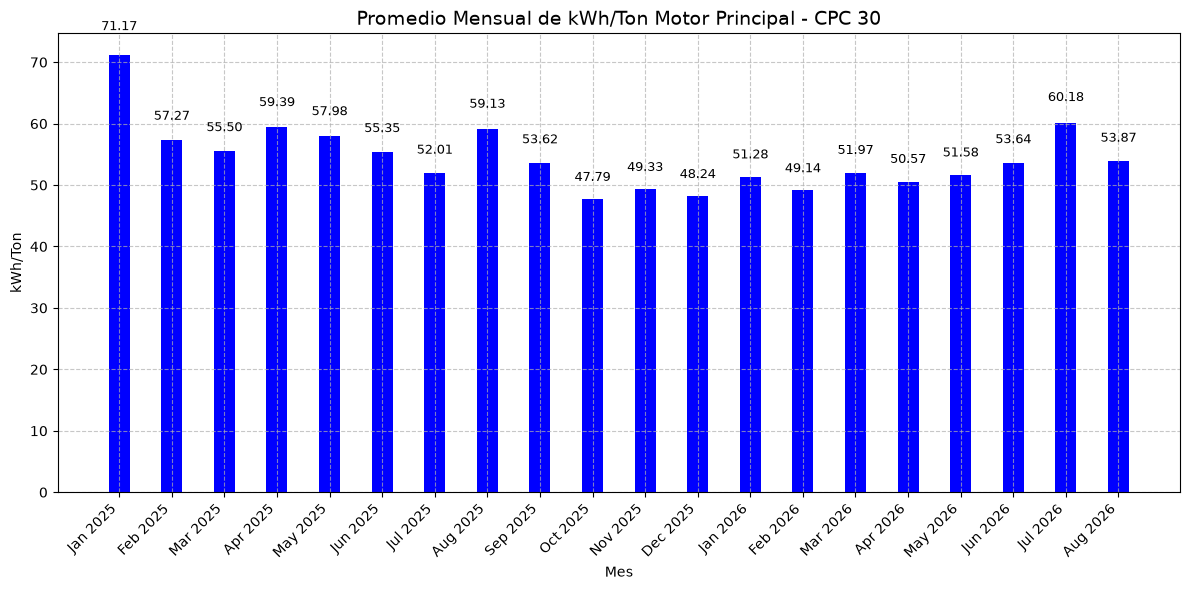

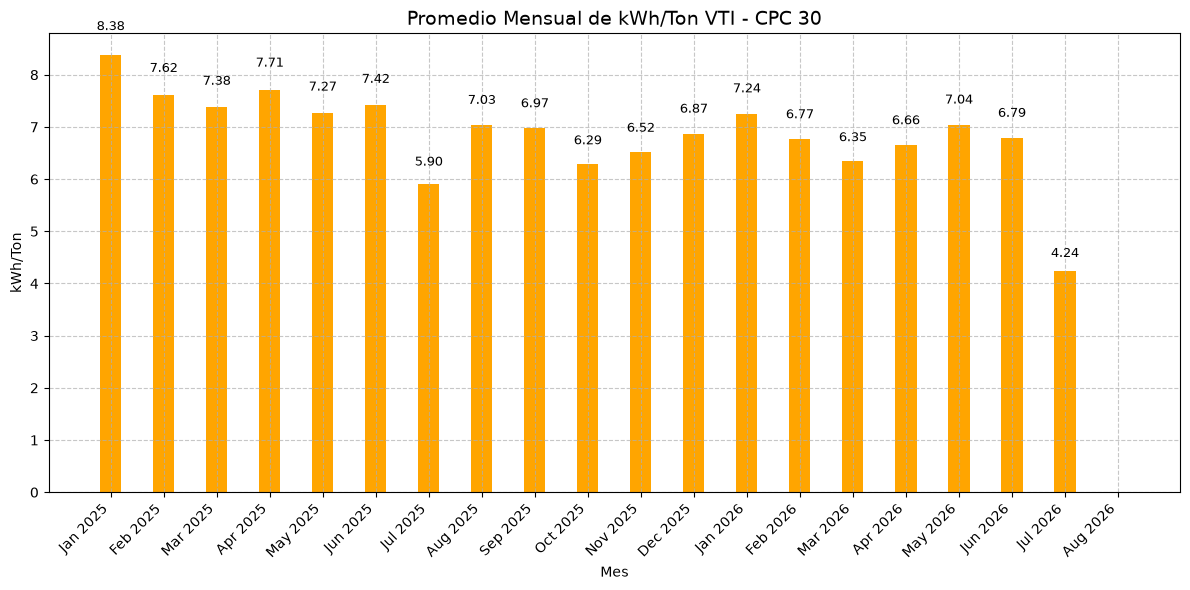

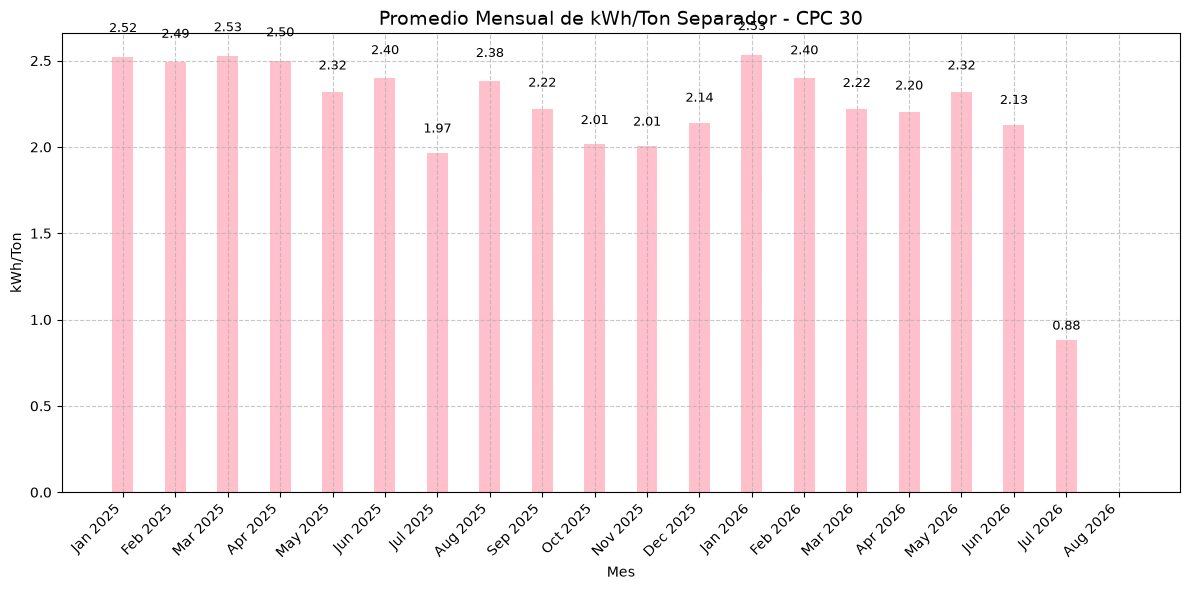

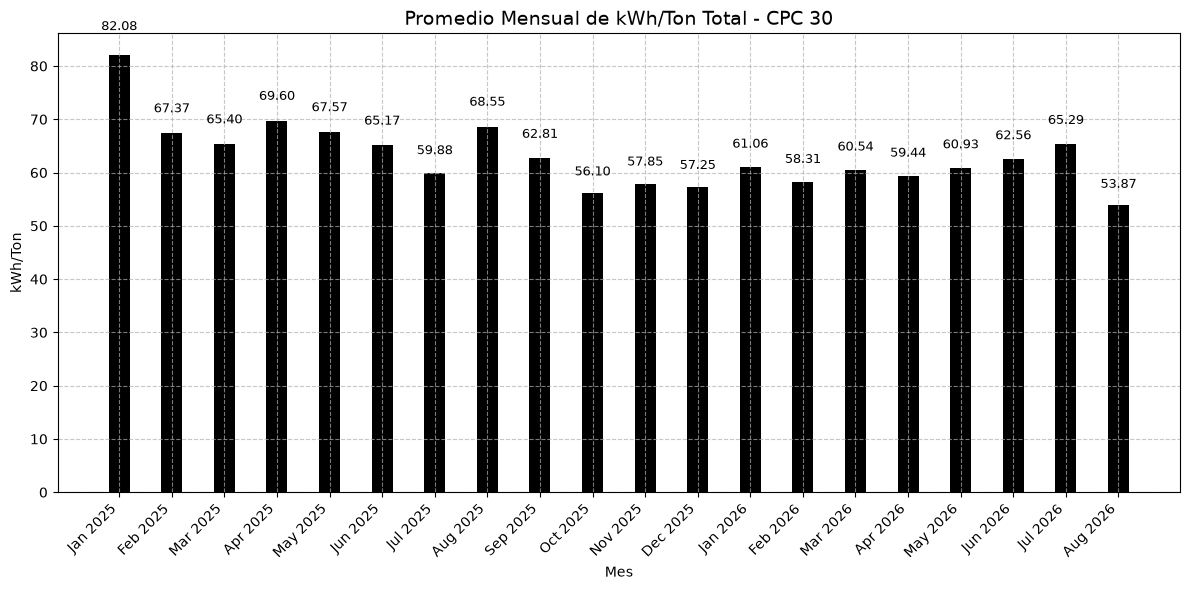

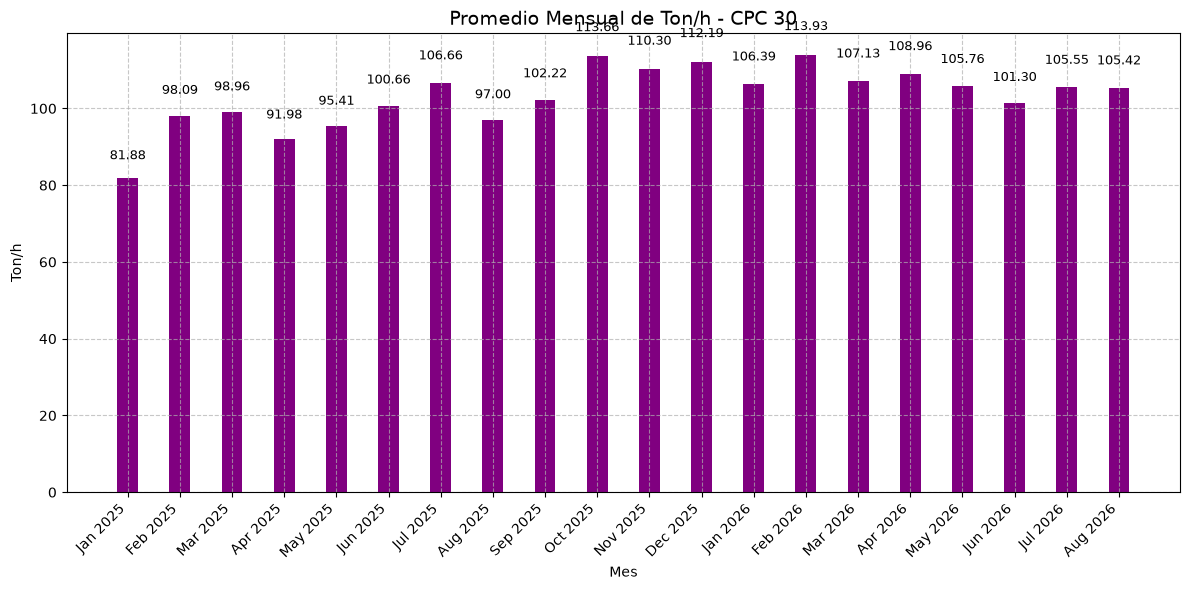

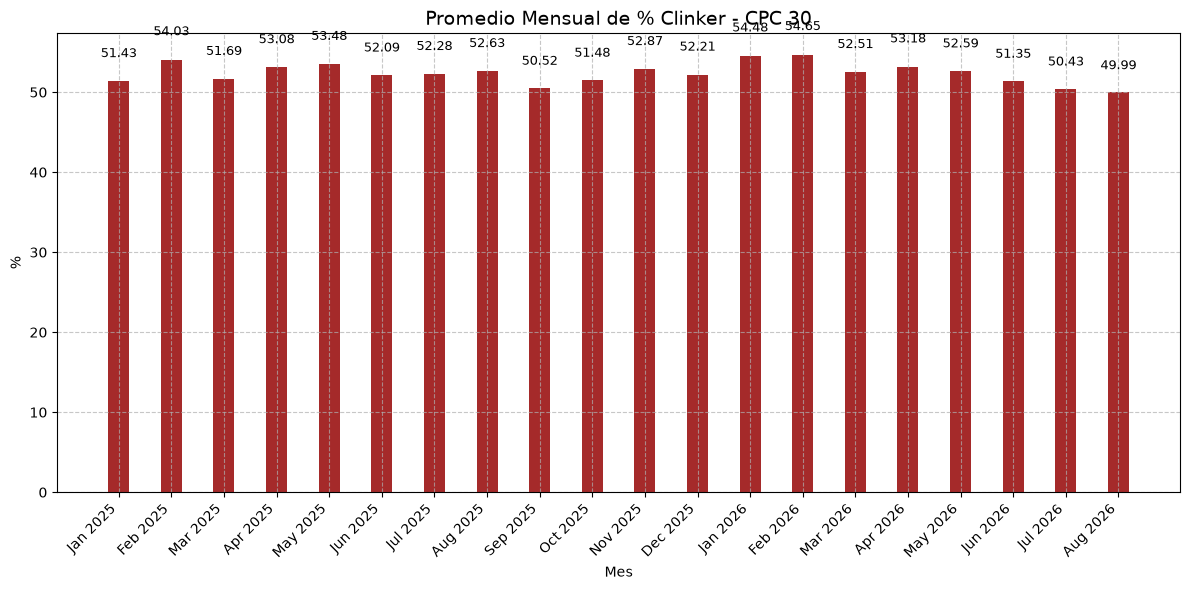


=== Promedios por períodos - CPC 30 ===

Contenido de promedios_periodos:
                         Ene-Dic 2025  Ene-Dic 2026  Diferencia (2026 - 2025)
kWh_Ton_Motor_Principal         55.56         52.78                     -2.79
kWh_Ton_VTI                      7.11          5.64                     -1.48
kWh_Ton_Separador                2.29          1.83                     -0.46
kWh_Ton_Total                   64.97         60.25                     -4.72
Ton_h_Promedio                 100.75        106.81                      6.05
%_Clinker_Promedio              52.31         52.40                      0.08

Promedio de kWh_Ton_Motor_Principal por período (CPC 30):
                         Ene-Dic 2025  Ene-Dic 2026  Diferencia (2026 - 2025)
kWh_Ton_Motor_Principal         55.56         52.78                     -2.79

Promedio de kWh_Ton_VTI por período (CPC 30):
             Ene-Dic 2025  Ene-Dic 2026  Diferencia (2026 - 2025)
kWh_Ton_VTI          7.11          5.64            

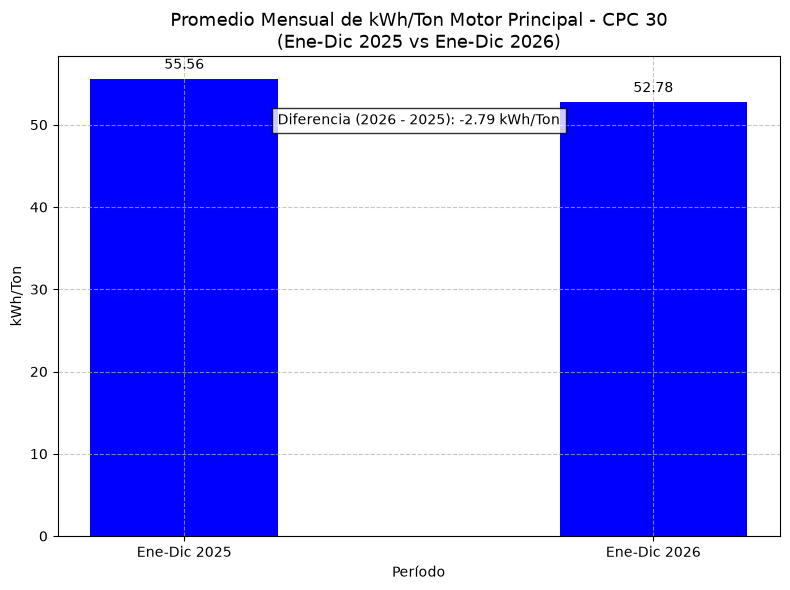

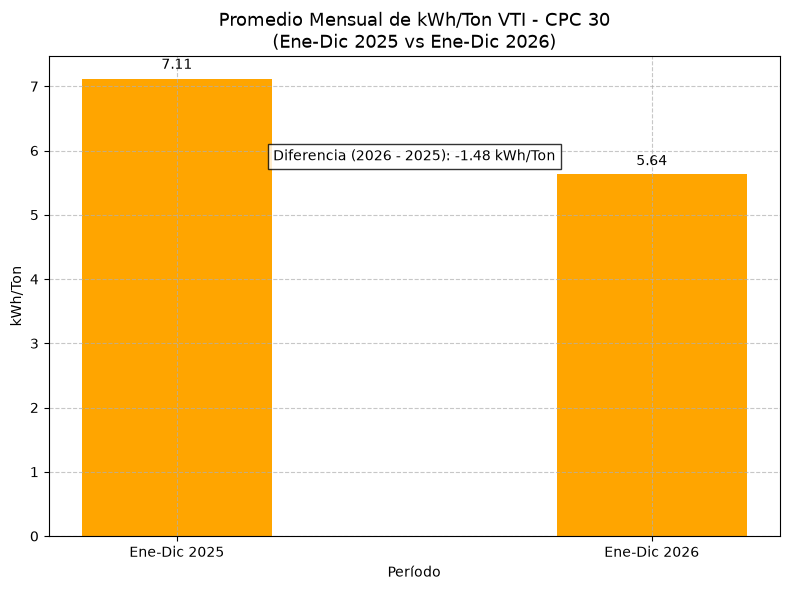

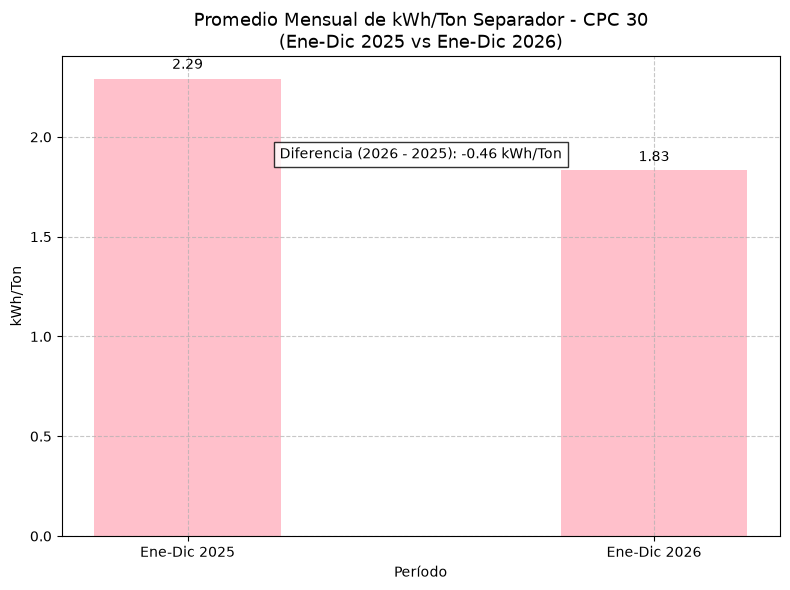

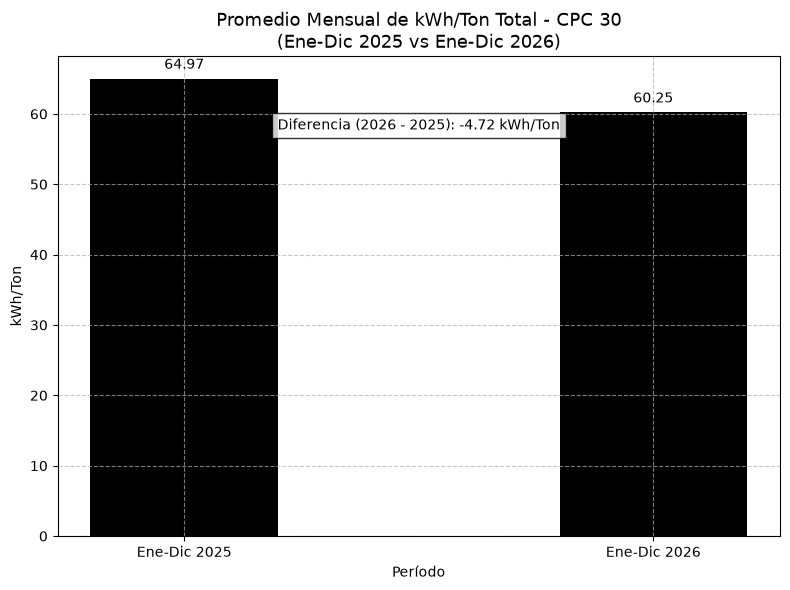

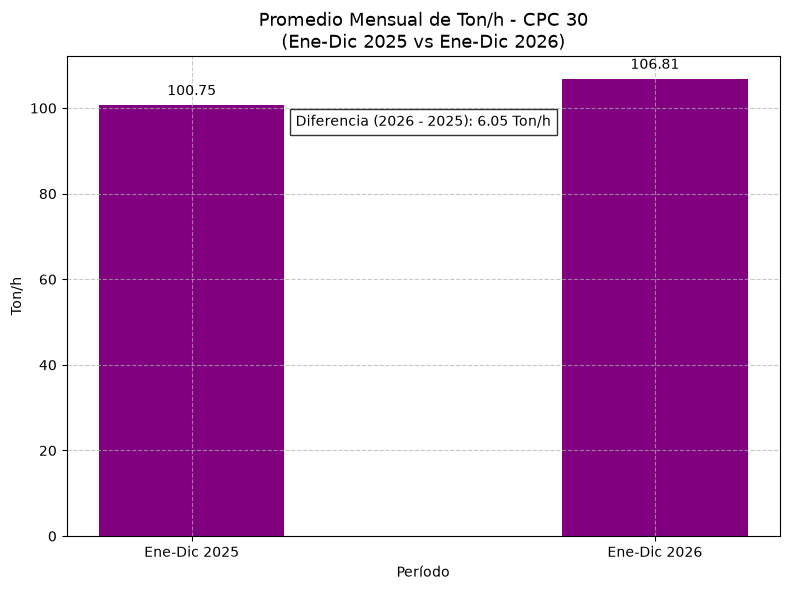

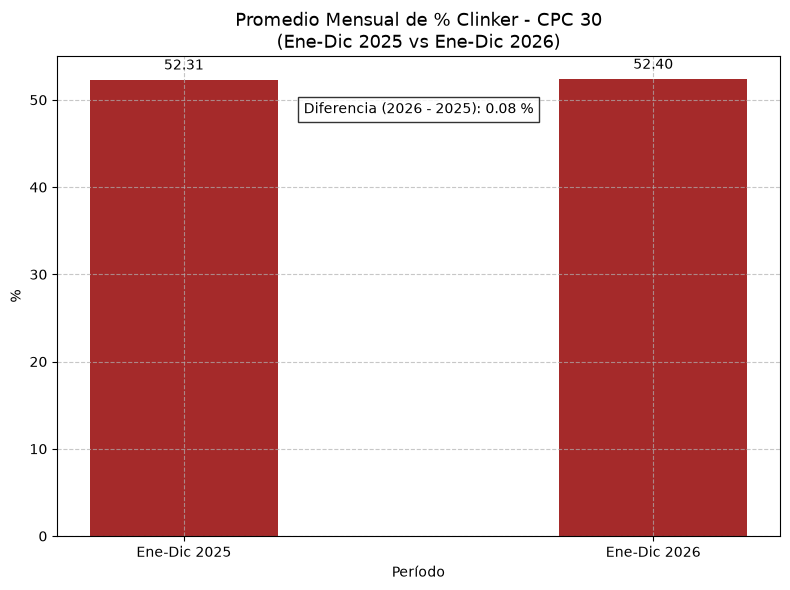


Generando gráfica horizontal comparativa para CPC 30...

Contribuciones promedio:
kWh_Ton_Motor_Principal: 54.17 kWh/Ton
kWh_Ton_VTI: 6.38 kWh/Ton
kWh_Ton_Separador: 2.06 kWh/Ton


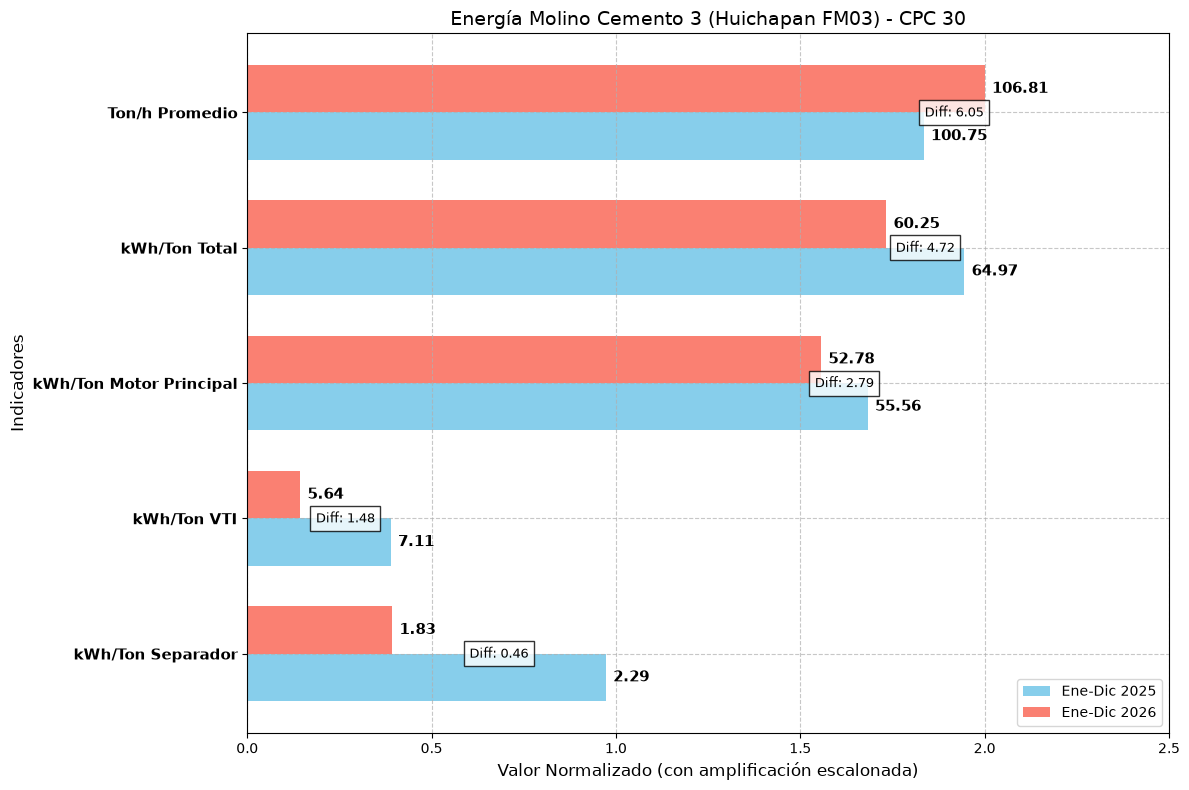


ANALIZANDO: CPC 40

Conteo de datos por mes:
Mes
2025-01     5774
2025-02     8938
2025-03     5993
2025-04    10461
2025-05     8437
2025-06    11350
2025-07     6094
2025-08       75
2025-09     1726
2025-10     7377
2025-11    11151
2025-12    10968
2026-01     6451
2026-02      705
2026-03     3900
2026-04     8883
2026-05     8898
2026-06    13751
2026-07     3512
2026-08     7836
dtype: int64

Promedios mensuales de kWh/Ton para Motor_Principal (CPC 40):
Jan 2025: 63.43
Feb 2025: 58.11
Mar 2025: 57.31
Apr 2025: 62.75
May 2025: 59.61
Jun 2025: 57.82
Jul 2025: 56.40
Aug 2025: 59.24
Sep 2025: 54.75
Oct 2025: 53.60
Nov 2025: 52.34
Dec 2025: 54.61
Jan 2026: 53.70
Feb 2026: 55.02
Mar 2026: 55.67
Apr 2026: 53.95
May 2026: 54.67
Jun 2026: 59.87
Jul 2026: 60.00
Aug 2026: 61.62

Promedios mensuales de kWh/Ton para VTI (CPC 40):
Jan 2025: 8.58
Feb 2025: 8.12
Mar 2025: 8.07
Apr 2025: 8.86
May 2025: 8.10
Jun 2025: 7.98
Jul 2025: 7.64
Aug 2025: 6.55
Sep 2025: 7.47
Oct 2025: 7.41
Nov 2025: 7.0

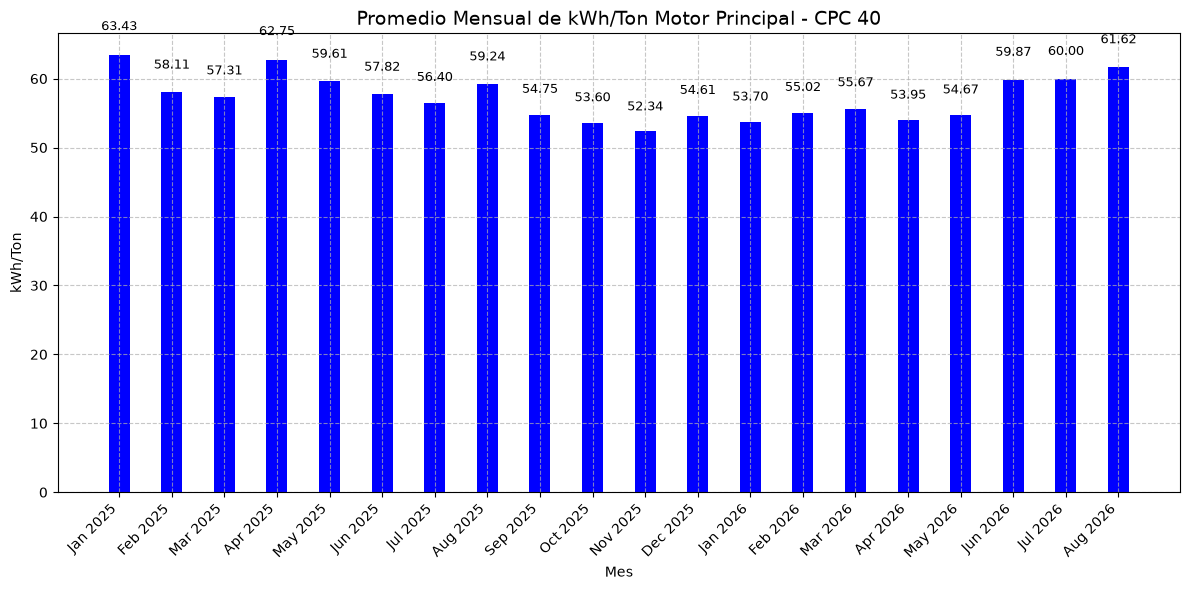

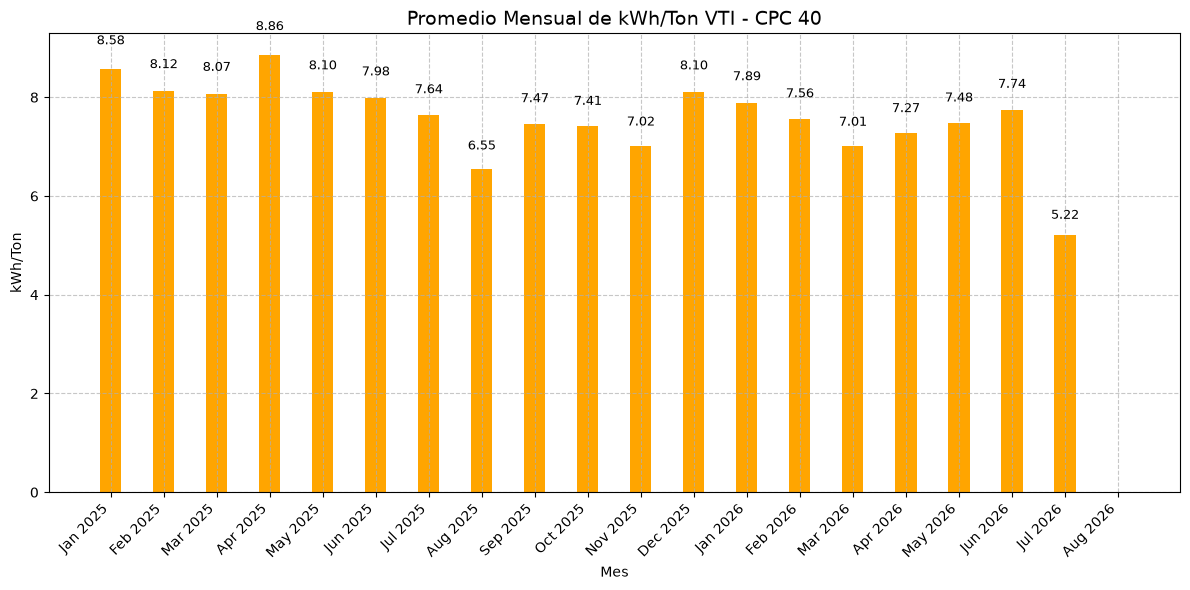

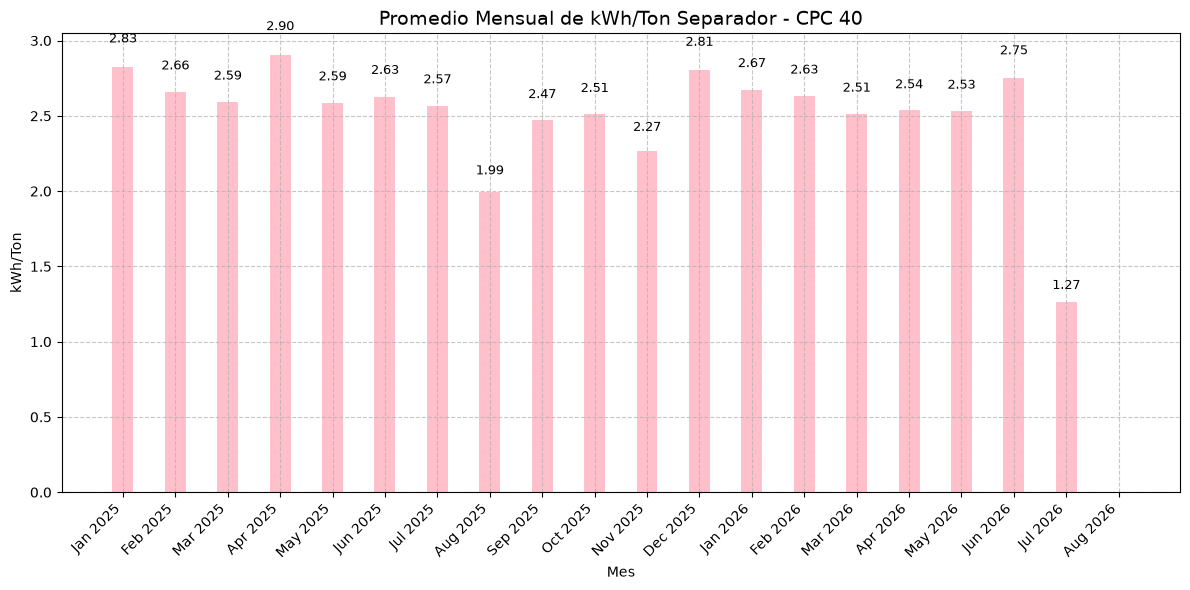

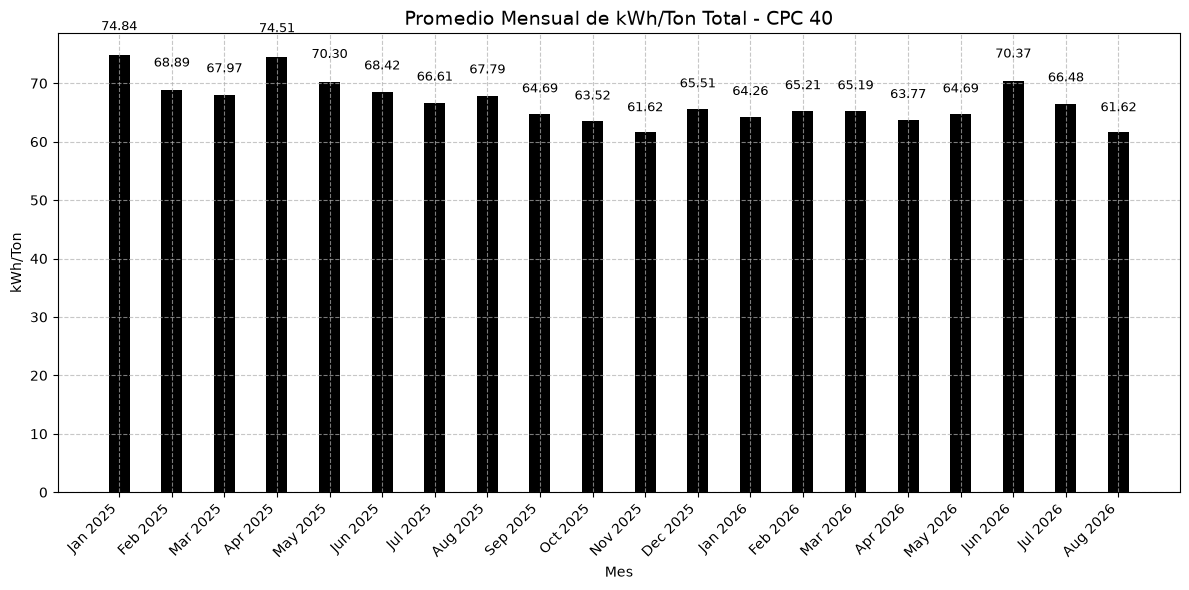

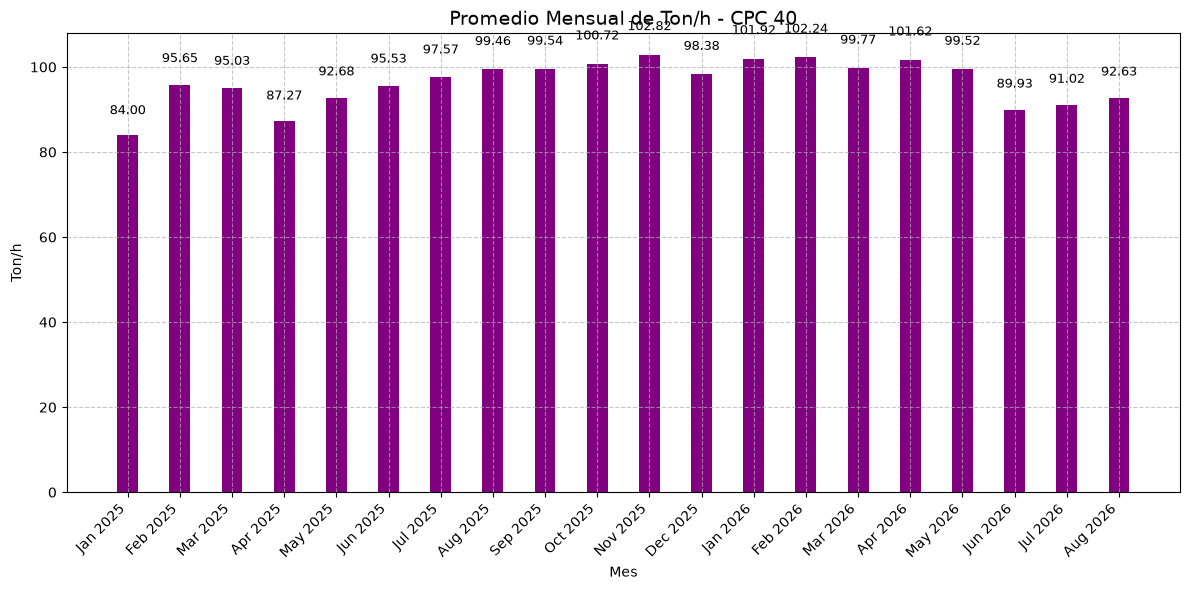

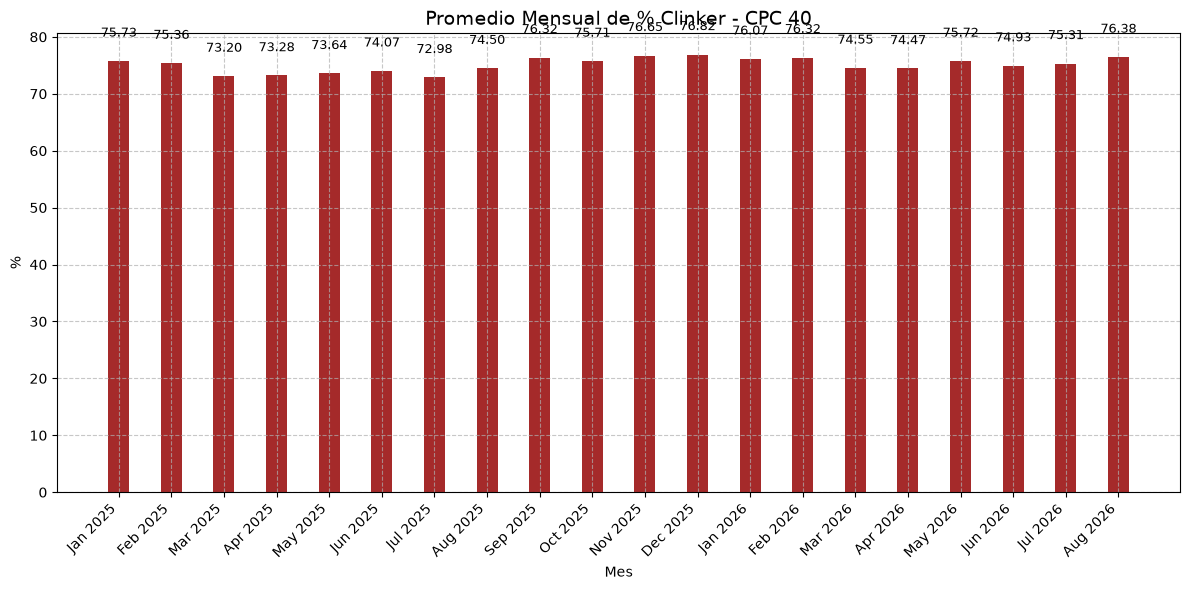


=== Promedios por períodos - CPC 40 ===

Contenido de promedios_periodos:
                         Ene-Dic 2025  Ene-Dic 2026  Diferencia (2026 - 2025)
kWh_Ton_Motor_Principal         57.50         56.81                     -0.68
kWh_Ton_VTI                      7.82          6.27                     -1.55
kWh_Ton_Separador                2.57          2.11                     -0.45
kWh_Ton_Total                   67.89         65.20                     -2.69
Ton_h_Promedio                  95.72         97.33                      1.61
%_Clinker_Promedio              74.85         75.47                      0.61

Promedio de kWh_Ton_Motor_Principal por período (CPC 40):
                         Ene-Dic 2025  Ene-Dic 2026  Diferencia (2026 - 2025)
kWh_Ton_Motor_Principal          57.5         56.81                     -0.68

Promedio de kWh_Ton_VTI por período (CPC 40):
             Ene-Dic 2025  Ene-Dic 2026  Diferencia (2026 - 2025)
kWh_Ton_VTI          7.82          6.27            

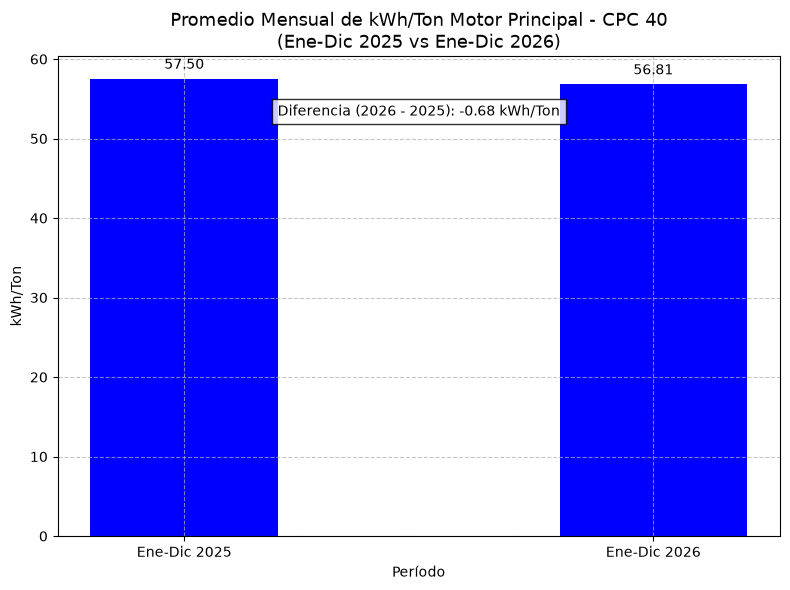

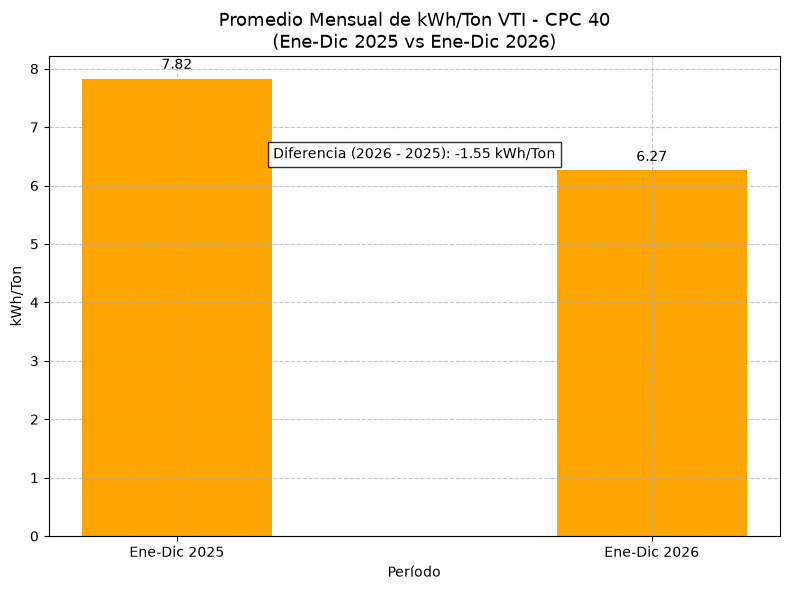

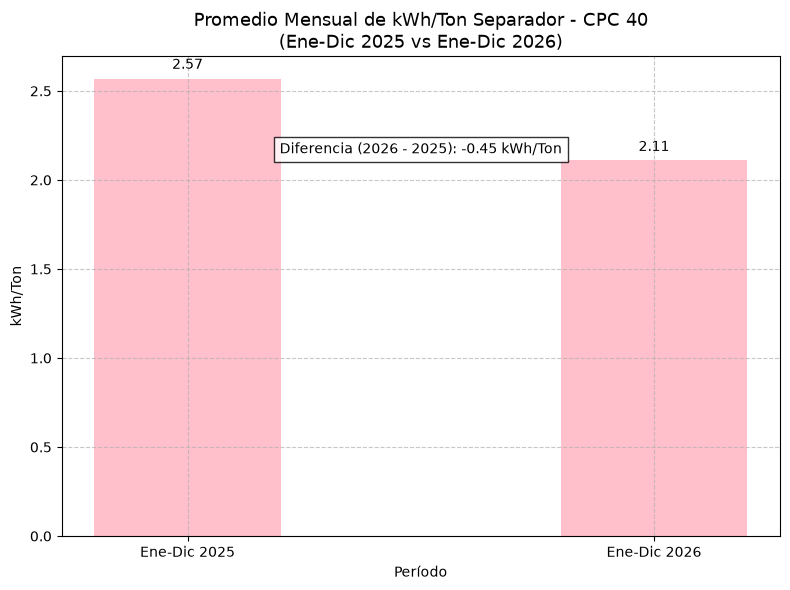

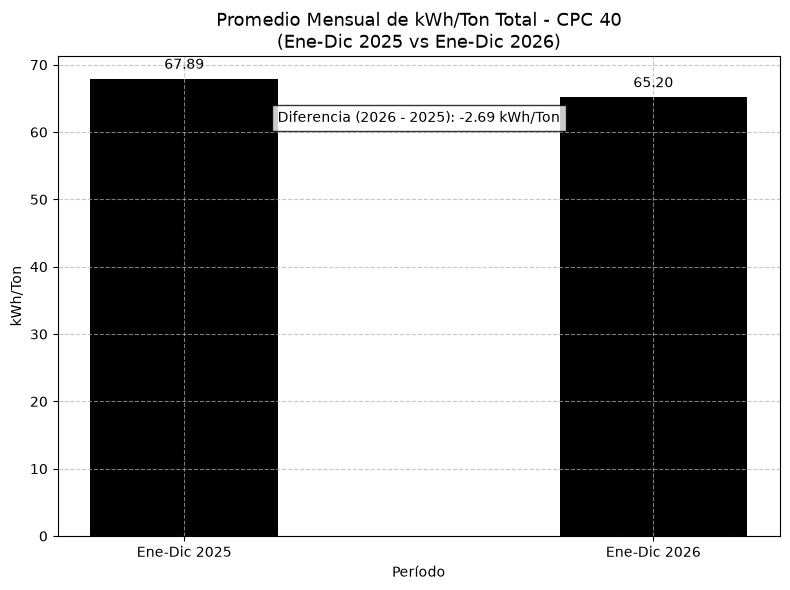

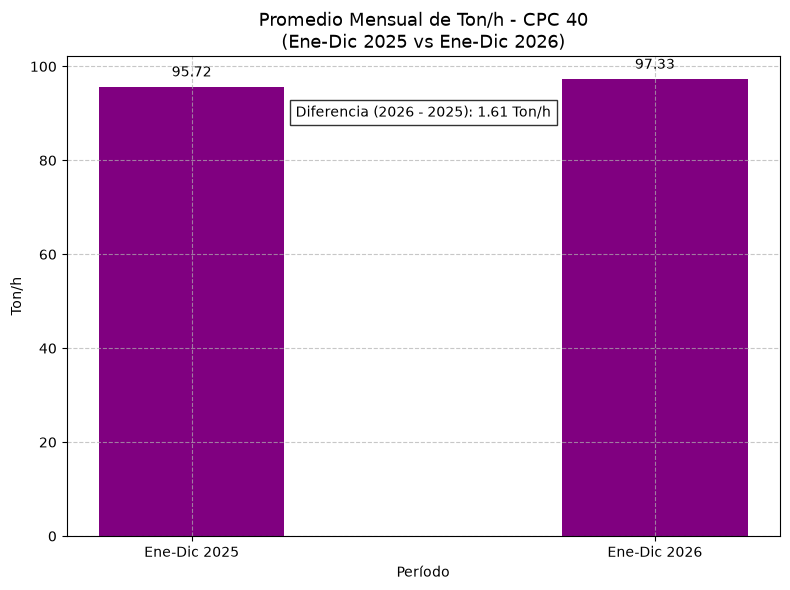

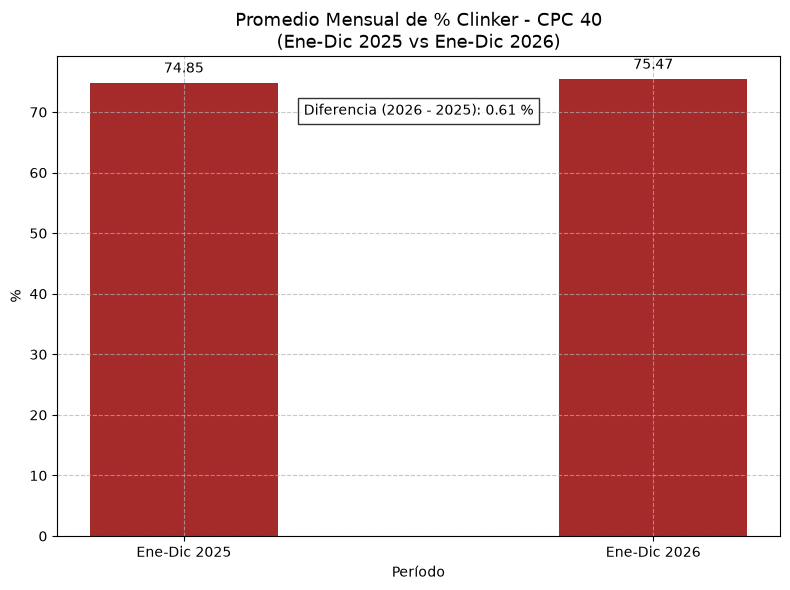


Generando gráfica horizontal comparativa para CPC 40...

Contribuciones promedio:
kWh_Ton_Motor_Principal: 57.16 kWh/Ton
kWh_Ton_VTI: 7.05 kWh/Ton
kWh_Ton_Separador: 2.34 kWh/Ton


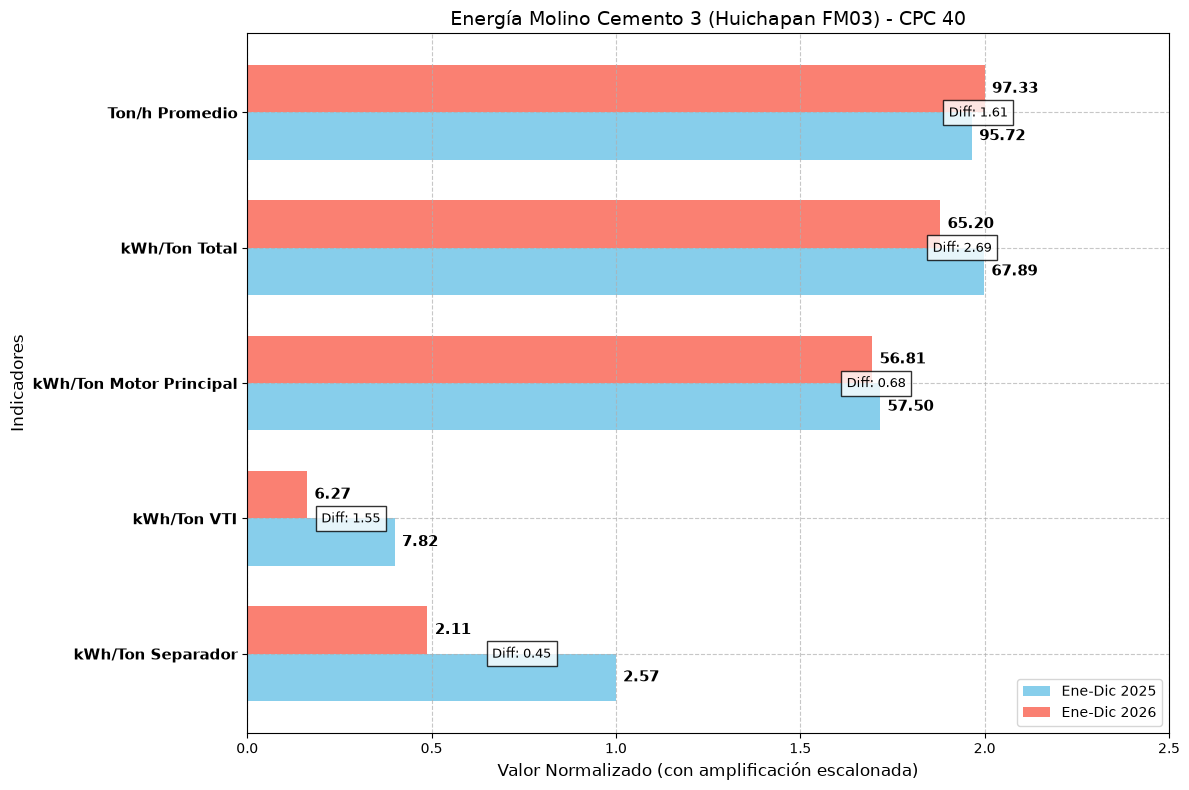


ANALIZANDO: Mortero

Conteo de datos por mes:
Mes
2025-02     387
2025-03       1
2025-04       1
2025-06       1
2025-07       2
2025-09    3046
2025-10    1997
2025-11       1
2025-12    1560
2026-01       7
2026-02       1
2026-03     688
2026-04    1223
2026-05     680
2026-06     979
dtype: int64

Promedios mensuales de kWh/Ton para Motor_Principal (Mortero):
Jan 2025: NaN
Feb 2025: 66.53
Mar 2025: 79.08
Apr 2025: 77.23
May 2025: NaN
Jun 2025: 72.44
Jul 2025: 71.40
Aug 2025: NaN
Sep 2025: 53.73
Oct 2025: 53.90
Nov 2025: 59.04
Dec 2025: 56.53
Jan 2026: 72.66
Feb 2026: 79.18
Mar 2026: 56.52
Apr 2026: 54.75
May 2026: 50.44
Jun 2026: 58.78
Jul 2026: NaN
Aug 2026: NaN

Promedios mensuales de kWh/Ton para VTI (Mortero):
Jan 2025: NaN
Feb 2025: 6.83
Mar 2025: 10.40
Apr 2025: 9.77
May 2025: NaN
Jun 2025: 10.28
Jul 2025: 7.50
Aug 2025: NaN
Sep 2025: 5.16
Oct 2025: 5.32
Nov 2025: 8.12
Dec 2025: 5.80
Jan 2026: 10.15
Feb 2026: 10.53
Mar 2026: 5.18
Apr 2026: 4.72
May 2026: 3.85
Jun 2026: 5.55

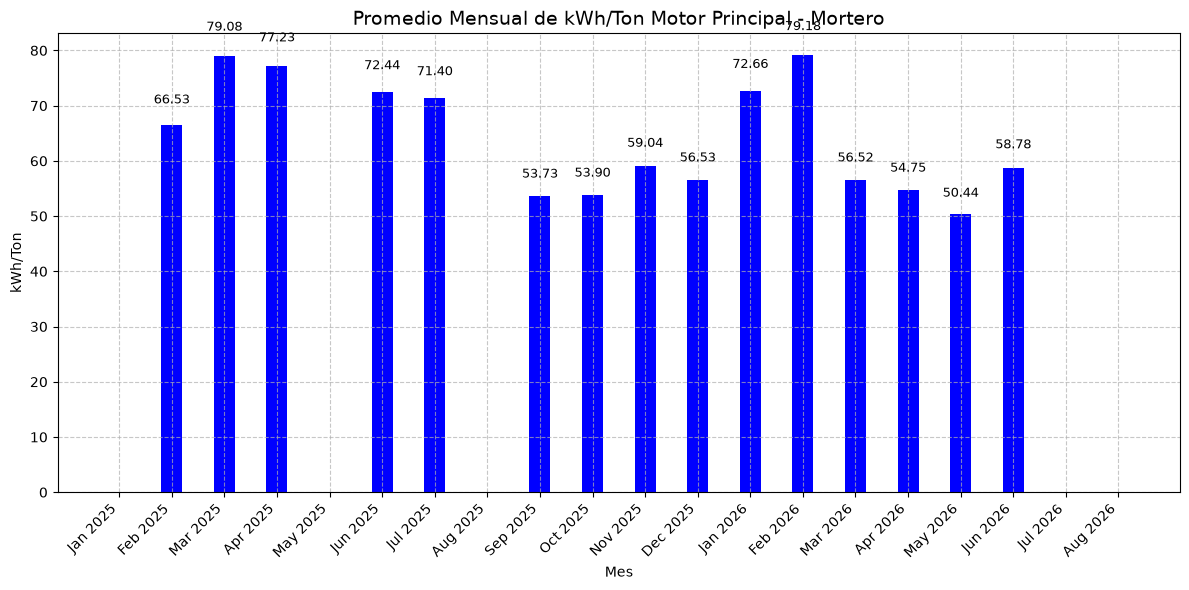

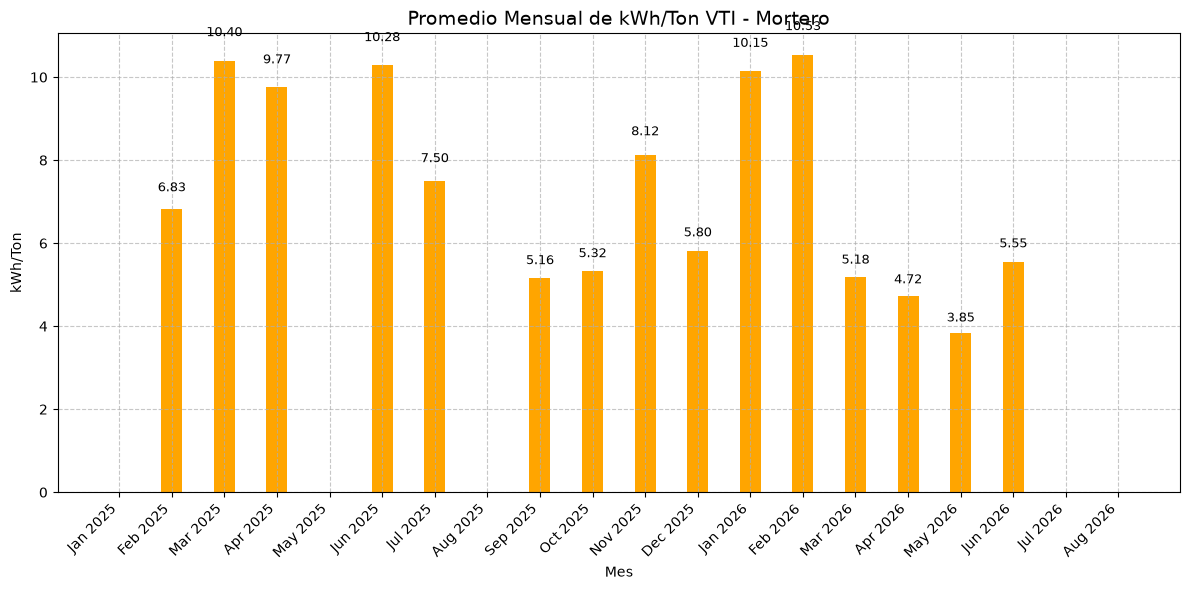

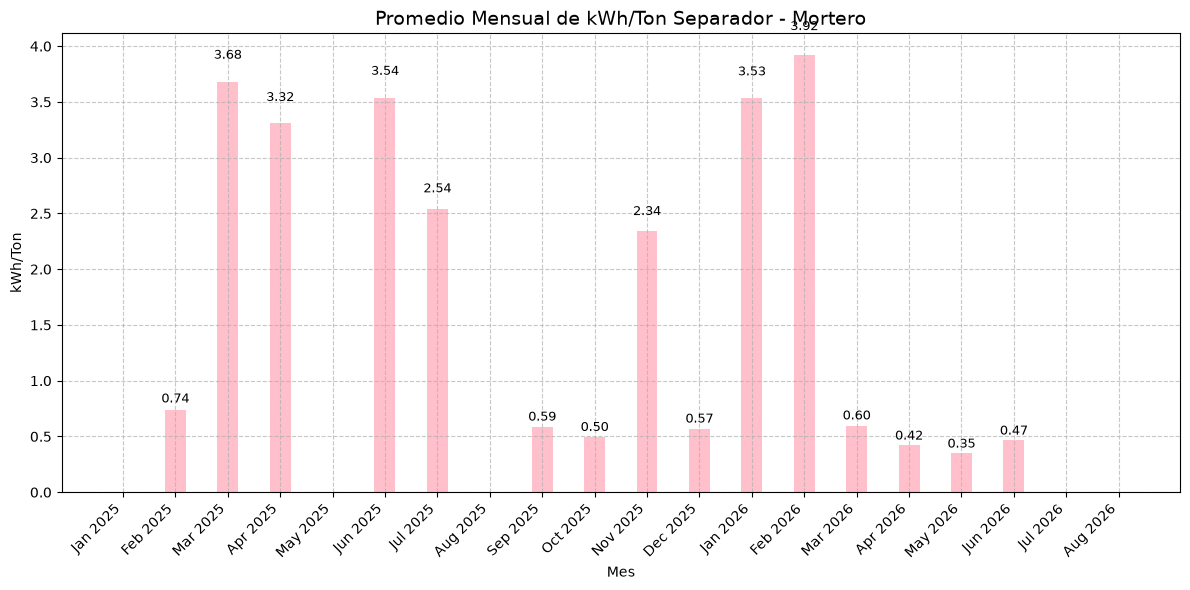

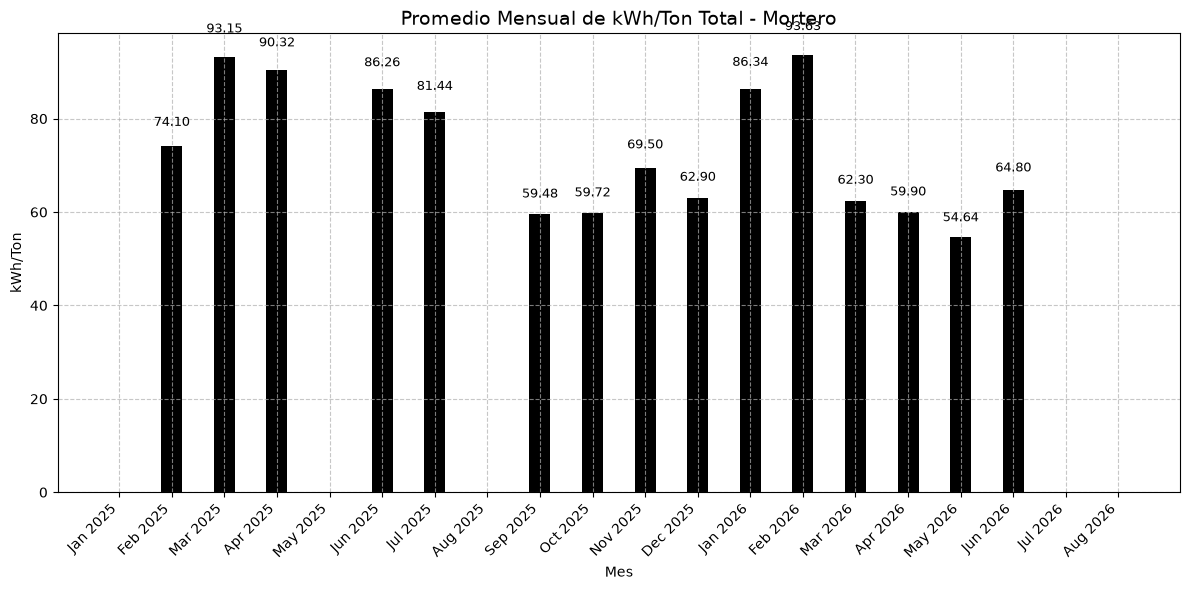

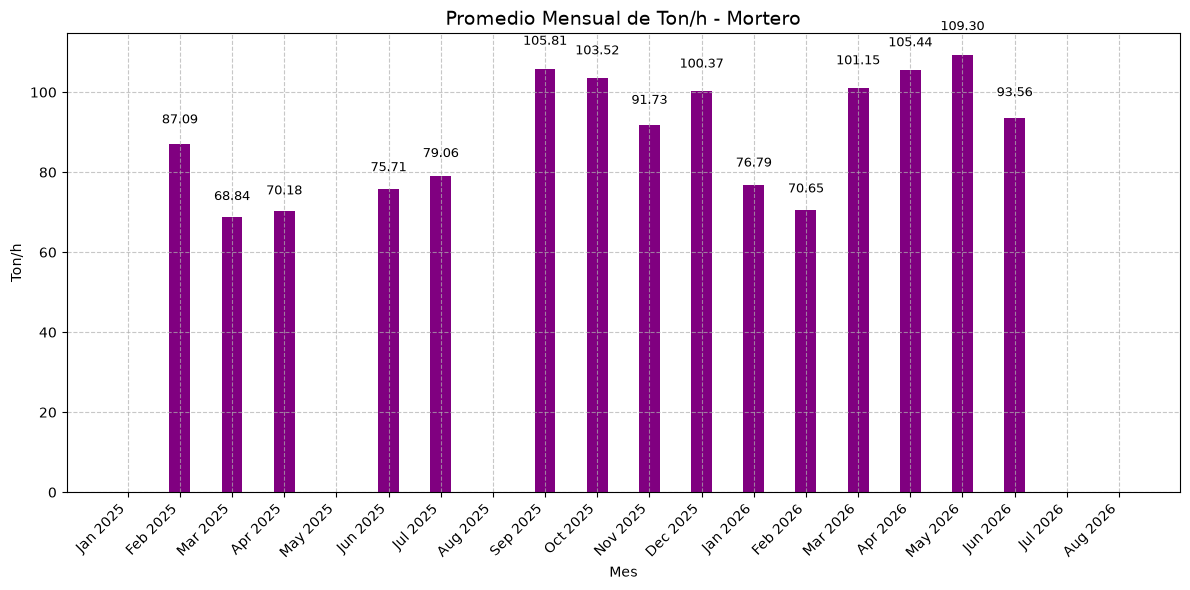

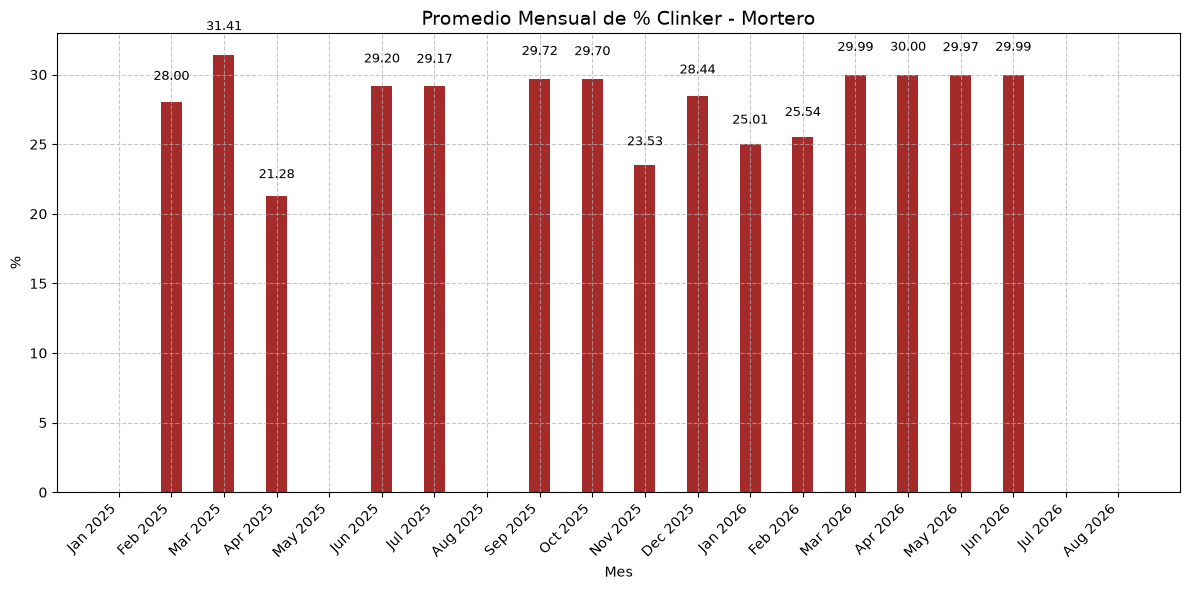


=== Promedios por períodos - Mortero ===

Contenido de promedios_periodos:
                         Ene-Dic 2025  Ene-Dic 2026  Diferencia (2026 - 2025)
kWh_Ton_Motor_Principal         65.54         62.06                     -3.48
kWh_Ton_VTI                      7.69          6.66                     -1.02
kWh_Ton_Separador                1.98          1.55                     -0.43
kWh_Ton_Total                   75.21         70.27                     -4.94
Ton_h_Promedio                  86.92         92.82                      5.89
%_Clinker_Promedio              27.83         28.42                      0.59

Promedio de kWh_Ton_Motor_Principal por período (Mortero):
                         Ene-Dic 2025  Ene-Dic 2026  Diferencia (2026 - 2025)
kWh_Ton_Motor_Principal         65.54         62.06                     -3.48

Promedio de kWh_Ton_VTI por período (Mortero):
             Ene-Dic 2025  Ene-Dic 2026  Diferencia (2026 - 2025)
kWh_Ton_VTI          7.69          6.66         

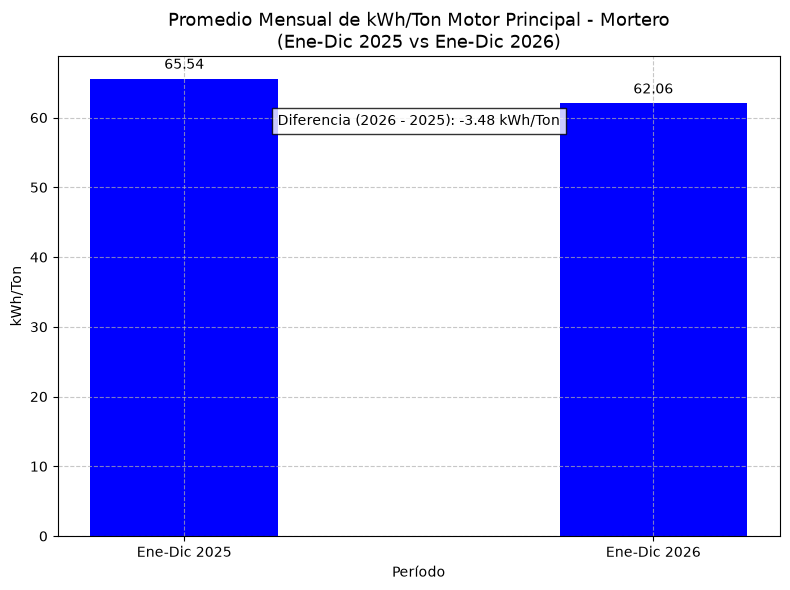

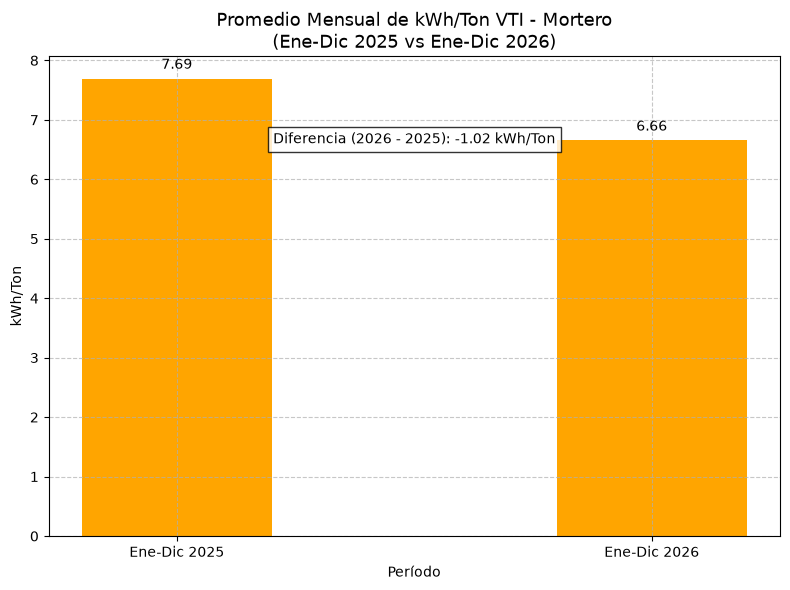

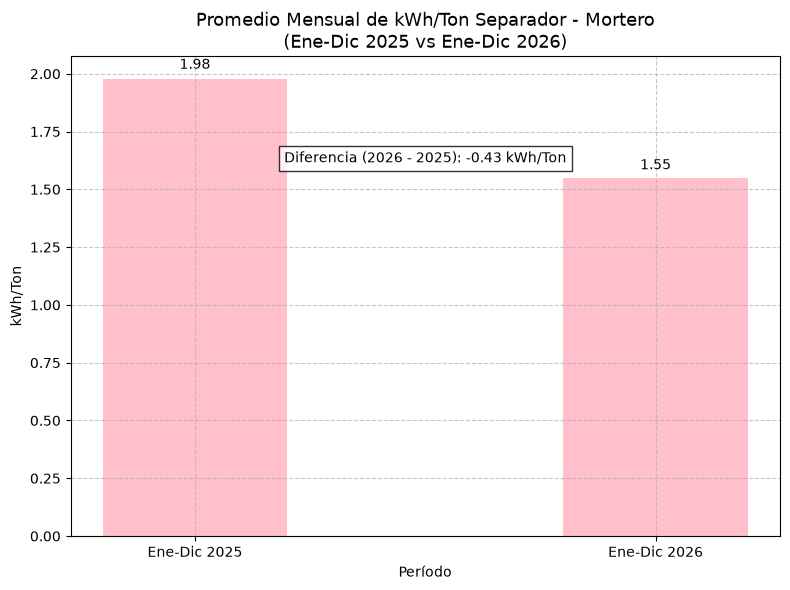

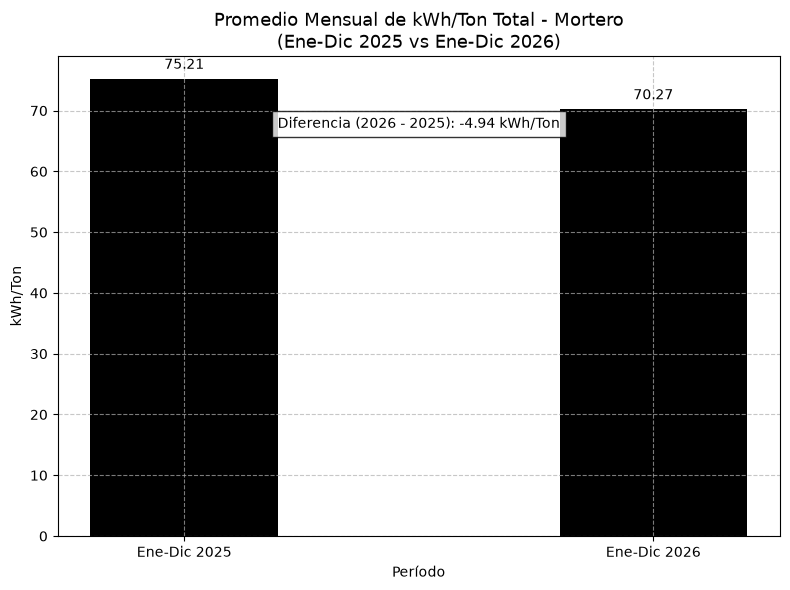

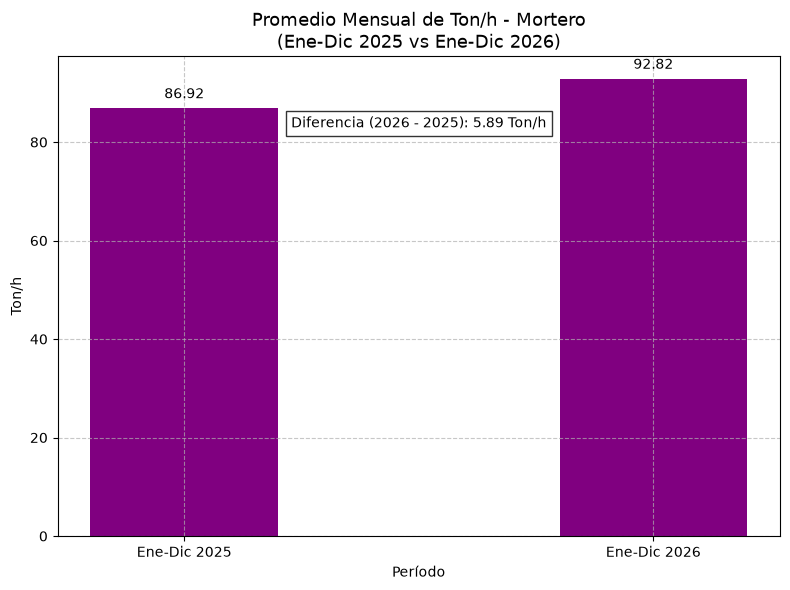

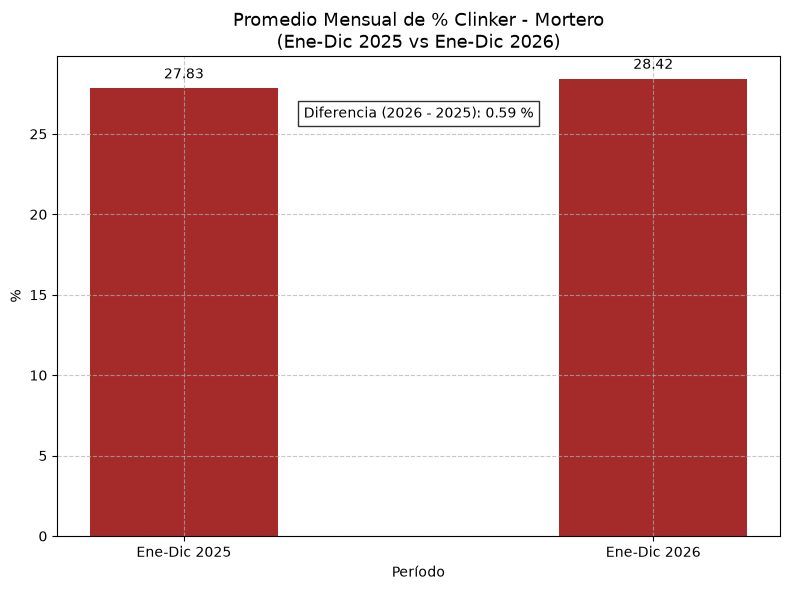


Generando gráfica horizontal comparativa para Mortero...

Contribuciones promedio:
kWh_Ton_Motor_Principal: 63.80 kWh/Ton
kWh_Ton_VTI: 7.18 kWh/Ton
kWh_Ton_Separador: 1.76 kWh/Ton


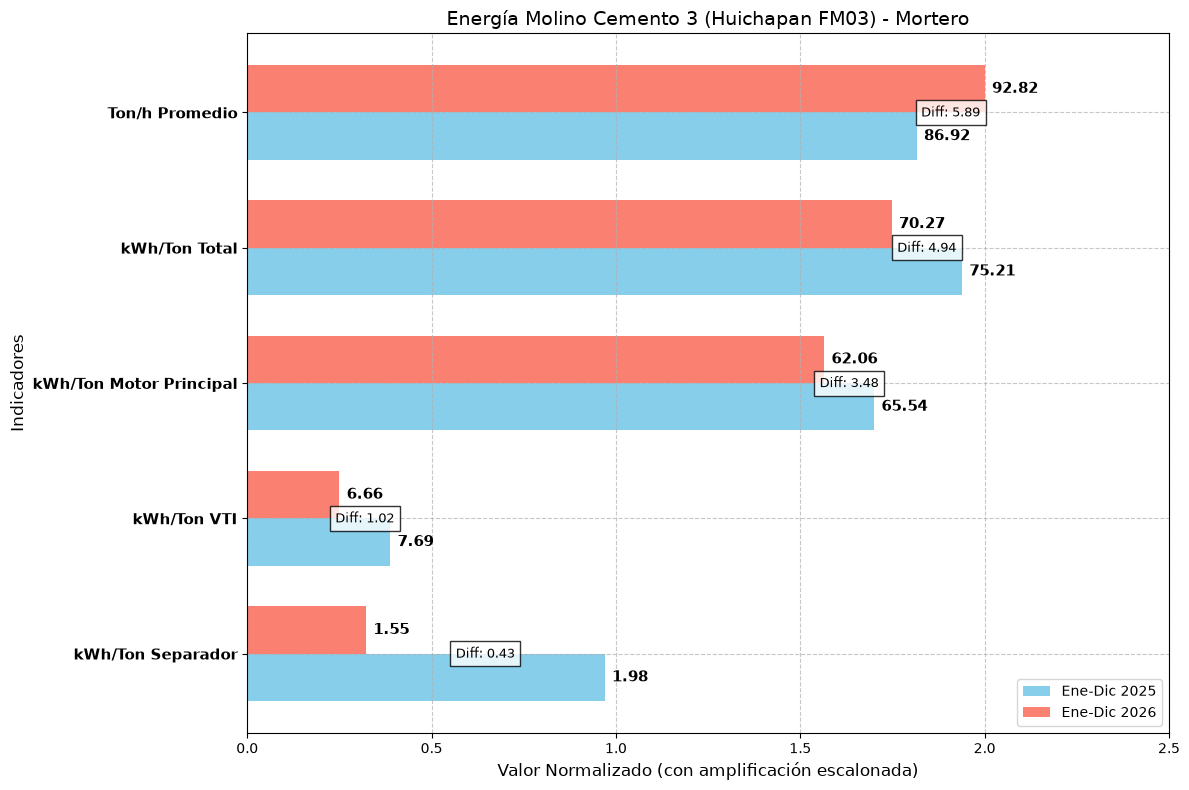

Guardado: Huichapan_FM03_CPC30_promedios_mensuales.xlsx
Guardado: Huichapan_FM03_CPC30_promedios_periodos.xlsx
Guardado: Huichapan_FM03_CPC40_promedios_mensuales.xlsx
Guardado: Huichapan_FM03_CPC40_promedios_periodos.xlsx
Guardado: Huichapan_FM03_Mortero_promedios_mensuales.xlsx
Guardado: Huichapan_FM03_Mortero_promedios_periodos.xlsx

¡Proceso terminado!


In [19]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import os

# ============================================================
# Paso 1: Definir los tags operativos
# ============================================================
list_tags = {
    'Tags': [
            'FC_610053.TPC',    # Alimentación
            'JI_62023.TPC',  # kW Motor Principal
            'JI_62233.TPC',  # kW VTI
            'JI_62113.TPC',  # kW Separador
            'FC_61143.TPC',   #Clinker

        
        
    ]
}

tags = pd.DataFrame(list_tags)
tags = tags.Tags
frequency_op = '2m'

# ============================================================
# Paso 2: Extraer datos del PI System
# ============================================================
operative_data = pd.DataFrame(columns=['Time'])

for n, tag in enumerate(tags):
    try:
        data = get_interpolated_values('2025-01-01 00:00:00', '2026-08-19 23:59:59', frequency_op, tag)
        print(f"Datos cargados para {tag}: {len(data)} filas")
        operative_data = PI_to_dataframe(data, operative_data, tag, n)
        if operative_data.empty or operative_data[tag].isna().all():
            print(f"Advertencia: No se cargaron datos válidos para {tag}")
    except Exception as e:
        print(f"Error al cargar datos para {tag}: {e}")
        operative_data[tag] = np.nan

if operative_data is None or operative_data.empty or operative_data[tags].isna().all().all():
    print("Error: No se cargaron datos operativos.")
    exit()

print("\nFilas en operative_data:", len(operative_data))
print(operative_data.head())
print("\nValores nulos:")
print(operative_data.isna().sum())

# ============================================================
# Paso 3: Convertir a kW (todos ya vienen en kW)
# ============================================================
operative_data['kW_Motor_Principal'] = operative_data['JI_62023.TPC']  # Ya está en kW
operative_data['kW_VTI'] = operative_data['JI_62233.TPC'] 
operative_data['kW_Separador'] =operative_data['JI_62113.TPC'] 

print("\nEstadísticas de tags operativos en kW:")
print(operative_data[['kW_Motor_Principal', 'kW_VTI', 'kW_Separador']].describe())

# ============================================================
# Paso 4: Procesar Time y calcular % Clinker
# ============================================================
operative_data['Time'] = pd.to_datetime(operative_data['Time'], format='%m/%d/%Y %I:%M:%S %p', errors='coerce')
operative_data = operative_data.set_index('Time')

# % de Clinker
operative_data['%_Clinker'] = (operative_data['FC_61143.TPC'] / operative_data['FC_610053.TPC']) * 100

# ============================================================
# Paso 5: Calcular kWh/Ton por equipo
# ============================================================

equipos = ['Motor_Principal', 'VTI', 'Separador']
tags_kw = ['kW_Motor_Principal', 'kW_VTI', 'kW_Separador']
tag_tonh = 'FC_610053.TPC'


for eq, tag_kw in zip(equipos, tags_kw):
    operative_data[f'kWh_Ton_{eq}'] = operative_data[tag_kw] / operative_data[tag_tonh]

# ============================================================
# Filtro operativo + limpieza de valores absurdos
# ============================================================
filtro_base = (
    (operative_data['kW_Motor_Principal'] > 3000) &
    (operative_data['kW_VTI'] > -1) &
    (operative_data['kW_Separador'] > -1) &
    (operative_data['FC_610053.TPC'] > 50)
)

operative_data = operative_data[filtro_base].copy()

# Eliminar valores absurdos de kWh/Ton
filtro_kwh = (
    (operative_data['kWh_Ton_Motor_Principal'] < 80) &
    (operative_data['kWh_Ton_VTI'] < 20) &
    (operative_data['kWh_Ton_Separador'] < 20)
)

operative_data = operative_data[filtro_kwh].copy()

print(f"\nFilas después del filtro operativo + limpieza: {len(operative_data)}")
print("\nMáximos de kWh/Ton después de limpiar:")
print(operative_data[[f'kWh_Ton_{eq}' for eq in equipos]].max())

# ============================================================
# Separar por tipo de producto (3 productos)
# ============================================================
data_cpc30 = operative_data[
    (operative_data['%_Clinker'] >= 44) & 
    (operative_data['%_Clinker'] <= 61)
].copy()

data_cpc40 = operative_data[
    (operative_data['%_Clinker'] >= 67) & 
    (operative_data['%_Clinker'] <= 80)
].copy()

data_mortero = operative_data[
    (operative_data['%_Clinker'] >= 20) & 
    (operative_data['%_Clinker'] <= 32)
].copy()

print(f"\nFilas CPC 30 (54-64%): {len(data_cpc30)}")
print(f"Filas CPC 40 (73-83%): {len(data_cpc40)}")
print(f"Filas Mortero (30-38%): {len(data_mortero)}")


# ============================================================
# FUNCIÓN PRINCIPAL DE ANÁLISIS POR PRODUCTO
# ============================================================
def analizar_producto(df, nombre_producto):
    print(f"\n{'='*90}")
    print(f"ANALIZANDO: {nombre_producto}")
    print(f"{'='*90}")
    
    if df.empty:
        print(f"No hay datos para {nombre_producto}")
        return None, None
    
    df = df.copy()
    df['Mes'] = df.index.strftime('%Y-%m')
    
    print("\nConteo de datos por mes:")
    print(df.groupby('Mes').size())
    
    meses = pd.date_range(start="2025-01-01", end="2026-08-19", freq="MS").strftime("%Y-%m").tolist()
    meses_nombres = pd.date_range(start="2025-01-01", end="2026-08-19", freq="MS").strftime("%b %Y").tolist()
    
    # Promedios mensuales
    promedios_mensuales = pd.DataFrame(index=meses)
    
    for eq in equipos:
        promedios_mensuales[f'kWh_Ton_{eq}'] = df.groupby('Mes')[f'kWh_Ton_{eq}'].mean()
    
    promedios_mensuales['Ton_h_Promedio'] = df.groupby('Mes')[tag_tonh].mean()
    promedios_mensuales['%_Clinker_Promedio'] = df.groupby('Mes')['%_Clinker'].mean()
    promedios_mensuales['kWh_Ton_Total'] = promedios_mensuales[[f'kWh_Ton_{eq}' for eq in equipos]].sum(axis=1)
    
    for mes in meses:
        if mes not in df['Mes'].values:
            promedios_mensuales.loc[mes, :] = np.nan
    
    # Imprimir resultados
    for eq in equipos:
        print(f"\nPromedios mensuales de kWh/Ton para {eq} ({nombre_producto}):")
        for mes, prom in zip(meses_nombres, promedios_mensuales[f'kWh_Ton_{eq}']):
            print(f"{mes}: {prom:.2f}" if not np.isnan(prom) else f"{mes}: NaN")
    
    print(f"\nkWh/Ton Total ({nombre_producto}):")
    for mes, total in zip(meses_nombres, promedios_mensuales['kWh_Ton_Total']):
        print(f"{mes}: {total:.2f}" if not np.isnan(total) else f"{mes}: NaN")
    
    print(f"\nTon/h Promedio ({nombre_producto}):")
    for mes, total in zip(meses_nombres, promedios_mensuales['Ton_h_Promedio']):
        print(f"{mes}: {total:.2f}" if not np.isnan(total) else f"{mes}: NaN")
    
    print(f"\n% Clinker Promedio ({nombre_producto}):")
    for mes, total in zip(meses_nombres, promedios_mensuales['%_Clinker_Promedio']):
        print(f"{mes}: {total:.1f}%" if not np.isnan(total) else f"{mes}: NaN")
    
    # Gráficas mensuales
    metricas = [
        ('kWh_Ton_Motor_Principal', 'Promedio Mensual de kWh/Ton Motor Principal', 'kWh/Ton', 'blue'),
        ('kWh_Ton_VTI',             'Promedio Mensual de kWh/Ton VTI',             'kWh/Ton', 'orange'),
        ('kWh_Ton_Separador',       'Promedio Mensual de kWh/Ton Separador',       'kWh/Ton', 'pink'),
        ('kWh_Ton_Total',           'Promedio Mensual de kWh/Ton Total',           'kWh/Ton', 'black'),
        ('Ton_h_Promedio',          'Promedio Mensual de Ton/h',                   'Ton/h',   'purple'),
        ('%_Clinker_Promedio',      'Promedio Mensual de % Clinker',               '%',       'brown'),
    ]
    
    for col, title, ylabel, color in metricas:
        plt.figure(figsize=(12, 6))
        x = np.arange(len(meses_nombres))
        values = promedios_mensuales[col].fillna(0)
        
        bars = plt.bar(x, values, color=color, width=0.4)
        
        for bar in bars:
            height = bar.get_height()
            if np.isfinite(height) and height > 0:
                plt.text(bar.get_x() + bar.get_width()/2, height + 0.05*height,
                         f'{height:.2f}', ha='center', va='bottom', fontsize=9)
        
        plt.title(f"{title} - {nombre_producto}", fontsize=14)
        plt.xlabel('Mes')
        plt.ylabel(ylabel)
        plt.xticks(x, meses_nombres, rotation=45, ha='right')
        plt.grid(True, linestyle='--', alpha=0.7)
        plt.tight_layout()
        plt.show()
    
    # =======================================================
    # PASO 9: Promedios por períodos
    # =======================================================
    print(f"\n=== Promedios por períodos - {nombre_producto} ===")
    
    periodo_2025 = [f'2025-{str(m).zfill(2)}' for m in range(1, 13)]
    periodo_2026 = [f'2026-{str(m).zfill(2)}' for m in range(1, 13)]
    
    promedios_periodos = pd.DataFrame(index=[col for col, _, _, _ in metricas])
    
    promedios_periodos['Ene-Dic 2025'] = promedios_mensuales.loc[
        promedios_mensuales.index.intersection(periodo_2025), 
        [col for col, _, _, _ in metricas]
    ].mean()
    
    promedios_periodos['Ene-Dic 2026'] = promedios_mensuales.loc[
        promedios_mensuales.index.intersection(periodo_2026), 
        [col for col, _, _, _ in metricas]
    ].mean()
    
    promedios_periodos['Diferencia (2026 - 2025)'] = (
        promedios_periodos['Ene-Dic 2026'] - promedios_periodos['Ene-Dic 2025']
    )
    
    print("\nContenido de promedios_periodos:")
    print(promedios_periodos.round(2))
    
    for col in promedios_periodos.index:
        print(f"\nPromedio de {col} por período ({nombre_producto}):")
        print(promedios_periodos.loc[[col], ['Ene-Dic 2025', 'Ene-Dic 2026', 'Diferencia (2026 - 2025)']].round(2))
    
    # Gráficas de barras por período
    for col, title, ylabel, color in metricas:
        plt.figure(figsize=(8, 6))
        x = np.array([0, 1])
        values = promedios_periodos.loc[col, ['Ene-Dic 2025', 'Ene-Dic 2026']].fillna(0).values
        
        bars = plt.bar(x, values, color=color, width=0.4)
        
        for bar in bars:
            height = bar.get_height()
            if height != 0:
                plt.text(bar.get_x() + bar.get_width()/2, height + 0.015*height,
                         f'{height:.2f}', ha='center', va='bottom', fontsize=10)
        
        diferencia = promedios_periodos.loc[col, 'Diferencia (2026 - 2025)']
        if not pd.isna(diferencia):
            y_pos = (values[0] + values[1]) / 2 - max(values) * 0.05
            plt.text(0.5, y_pos, f'Diferencia (2026 - 2025): {diferencia:.2f} {ylabel}',
                     ha='center', va='top', fontsize=10,
                     bbox=dict(facecolor='white', alpha=0.8, edgecolor='black'))
        
        plt.title(f'{title} - {nombre_producto}\n(Ene-Dic 2025 vs Ene-Dic 2026)', fontsize=13)
        plt.xlabel('Período')
        plt.ylabel(ylabel)
        plt.xticks(x, ['Ene-Dic 2025', 'Ene-Dic 2026'])
        plt.grid(True, linestyle='--', alpha=0.7)
        plt.tight_layout()
        plt.show()
    
    # =======================================================
    # PASO 10: Gráfica horizontal comparativa
    # =======================================================
    print(f"\nGenerando gráfica horizontal comparativa para {nombre_producto}...")
    
    kw_tags = [
        ('kWh_Ton_Motor_Principal', 'kWh/Ton Motor Principal', 'kWh/Ton', 'blue'),
        ('kWh_Ton_VTI',             'kWh/Ton VTI',             'kWh/Ton', 'orange'),
        ('kWh_Ton_Separador',       'kWh/Ton Separador',       'kWh/Ton', 'pink'),

    ]
    
    contribuciones = {}
    for tag, label, unit, color in kw_tags:
        avg_2025 = promedios_periodos.loc[tag, 'Ene-Dic 2025']
        avg_2026 = promedios_periodos.loc[tag, 'Ene-Dic 2026']
        avg_value = np.nanmean([avg_2025, avg_2026])
        contribuciones[tag] = avg_value
    
    print("\nContribuciones promedio:")
    for tag, contrib in contribuciones.items():
        print(f"{tag}: {contrib:.2f} kWh/Ton")
    
    sorted_kw_tags = sorted(contribuciones.items(), key=lambda x: x[1], reverse=True)
    sorted_tags = [x[0] for x in sorted_kw_tags]
    
    sorted_kw_tags_full = []
    for tag in sorted_tags:
        for kw_tag in kw_tags:
            if kw_tag[0] == tag:
                sorted_kw_tags_full.append(kw_tag)
                break
    
    sorted_indicadores = [
        ('Ton_h_Promedio', 'Ton/h Promedio', 'Ton/h', 'purple'),
        ('kWh_Ton_Total',  'kWh/Ton Total',  'kWh/Ton', 'black')
    ] + sorted_kw_tags_full
    
    normalized_data = promedios_periodos.loc[[ind[0] for ind in sorted_indicadores], 
                                             ['Ene-Dic 2025', 'Ene-Dic 2026']].copy()
    normalized_data_np = normalized_data.fillna(0).to_numpy()
    
    scaled_data = normalized_data_np.copy()
    for i in range(2):
        max_val = max(normalized_data_np[i, 0], normalized_data_np[i, 1])
        if max_val > 0:
            scaled_data[i, :] = normalized_data_np[i, :] / max_val
    
    min_scale = 0.2
    separator_amplification = 2.5
    
    for i in range(2, len(sorted_indicadores)):
        tag = sorted_indicadores[i][0]
        avg_contrib = contribuciones.get(tag, 0)
        total_avg = np.nanmean([
            promedios_periodos.loc['kWh_Ton_Total', 'Ene-Dic 2025'],
            promedios_periodos.loc['kWh_Ton_Total', 'Ene-Dic 2026']
        ])
        if total_avg > 0:
            proportion = avg_contrib / total_avg
            proportion = max(proportion, min_scale)
            if "Separador" in tag:
                proportion *= separator_amplification
            scaled_data[i, :] = (normalized_data_np[i, :] / 
                                 max(normalized_data_np[i, 0], normalized_data_np[i, 1])) * proportion
        else:
            scaled_data[i, :] = 0
    
    large_diff_threshold = 0.10
    medium_diff_threshold = 0.02
    large_amplification = 2
    medium_amplification = 1.5
    small_amplification = 1.05
    
    adjusted_data = scaled_data.copy()
    for i in range(normalized_data_np.shape[0]):
        val_2025 = normalized_data_np[i, 0]
        val_2026 = normalized_data_np[i, 1]
        if val_2025 == 0 or val_2026 == 0:
            continue
        rel_diff = abs((val_2026 - val_2025) / val_2025) if val_2025 != 0 else 0
        
        if rel_diff >= large_diff_threshold:
            dynamic_amplification = large_amplification + (rel_diff * 5)
            adjusted_data[i, 0] = scaled_data[i, 0]
            adjusted_data[i, 1] = scaled_data[i, 1] + (scaled_data[i, 1] - scaled_data[i, 0]) * (dynamic_amplification - 1)
        elif rel_diff >= medium_diff_threshold:
            adjusted_data[i, 0] = scaled_data[i, 0]
            adjusted_data[i, 1] = scaled_data[i, 1] + (scaled_data[i, 1] - scaled_data[i, 0]) * (medium_amplification - 1)
        else:
            adjusted_data[i, 0] = scaled_data[i, 0]
            adjusted_data[i, 1] = scaled_data[i, 1] + (scaled_data[i, 1] - scaled_data[i, 0]) * (small_amplification - 1)
    
    normalized_data = pd.DataFrame(adjusted_data, index=normalized_data.index, columns=normalized_data.columns)
    
    global_max = normalized_data.max().max()
    if global_max > 0:
        normalized_data = normalized_data / (global_max * 0.5)
    normalized_data = normalized_data.fillna(0)
    
    display_order = sorted_indicadores[::-1]
    display_labels = [label for _, label, _, _ in display_order]
    display_indices = [sorted_indicadores.index(ind) for ind in display_order]
    
    normalized_data_display = normalized_data.iloc[display_indices]
    
    # Gráfica horizontal
    plt.figure(figsize=(12, 8))
    n_indicadores = len(sorted_indicadores)
    y = np.arange(n_indicadores)
    height = 0.35
    
    bars1 = plt.barh(y - height/2, normalized_data_display['Ene-Dic 2025'], height, 
                     label='Ene-Dic 2025', color='skyblue')
    bars2 = plt.barh(y + height/2, normalized_data_display['Ene-Dic 2026'], height, 
                     label='Ene-Dic 2026', color='salmon')
    
    for bars, period in [(bars1, 'Ene-Dic 2025'), (bars2, 'Ene-Dic 2026')]:
        for i, bar in enumerate(bars):
            width = bar.get_width()
            if width > 0:
                real_value = promedios_periodos.loc[display_order[i][0], period]
                if not pd.isna(real_value):
                    plt.text(width + 0.02, bar.get_y() + bar.get_height()/2,
                             f'{real_value:.2f}', ha='left', va='center', 
                             fontsize=11, fontweight='bold')
    
    for i, (col, _, _, _) in enumerate(display_order):
        val_2025 = promedios_periodos.loc[col, 'Ene-Dic 2025']
        val_2026 = promedios_periodos.loc[col, 'Ene-Dic 2026']
        abs_diff = abs(val_2026 - val_2025) if not (pd.isna(val_2025) or pd.isna(val_2026)) else 0
        if abs_diff > 0:
            y_pos = y[i]
            x_pos = (normalized_data_display.loc[col, 'Ene-Dic 2025'] + 
                     normalized_data_display.loc[col, 'Ene-Dic 2026']) / 2
            plt.text(x_pos, y_pos, f'Diff: {abs_diff:.2f}', ha='center', va='center', 
                     fontsize=9, bbox=dict(facecolor='white', alpha=0.8, edgecolor='black'))
    
    plt.title(f'Energía Molino Cemento 3 (Huichapan FM03) - {nombre_producto}', fontsize=14)
    plt.xlabel('Valor Normalizado (con amplificación escalonada)', fontsize=12)
    plt.ylabel('Indicadores', fontsize=12)
    plt.yticks(y, display_labels, fontsize=11, fontweight='bold')
    plt.xlim(0, 2.5)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    
    return promedios_mensuales, promedios_periodos


# ============================================================
# Ejecutar el análisis para cada producto (3 productos)
# ============================================================
prom_mensuales_cpc30,   prom_periodos_cpc30   = analizar_producto(data_cpc30,   "CPC 30")
prom_mensuales_cpc40,   prom_periodos_cpc40   = analizar_producto(data_cpc40,   "CPC 40")
prom_mensuales_mortero, prom_periodos_mortero = analizar_producto(data_mortero, "Mortero")


# ============================================================
# Guardar Excel
# ============================================================
nombre_base = 'Huichapan_FM03'

tablas = {
    'CPC30_promedios_mensuales':   prom_mensuales_cpc30,
    'CPC30_promedios_periodos':    prom_periodos_cpc30,
    'CPC40_promedios_mensuales':   prom_mensuales_cpc40,
    'CPC40_promedios_periodos':    prom_periodos_cpc40,
    'Mortero_promedios_mensuales': prom_mensuales_mortero,
    'Mortero_promedios_periodos':  prom_periodos_mortero,
}

for nombre, df in tablas.items():
    if df is not None and isinstance(df, pd.DataFrame):
        archivo = f"{nombre_base}_{nombre}.xlsx"
        df.to_excel(archivo, index=True)
        print(f"Guardado: {archivo}")

print("\n¡Proceso terminado!")

Datos cargados para MX-TEP-S01-611007-MX1-60003-03-HOR-M00-QM: 1316 filas, Tipo de data: <class 'OSIsoft.AF.Asset.AFValues'>

Estadísticas para MX-TEP-S01-611007-MX1-60003-03-HOR-M00-QM:
count    1316.000000
mean       98.281550
std         0.345044
min        95.510002
25%        98.110001
50%        98.269997
75%        98.510002
max        99.699997
Name: MX-TEP-S01-611007-MX1-60003-03-HOR-M00-QM, dtype: float64
Valores nulos para MX-TEP-S01-611007-MX1-60003-03-HOR-M00-QM: 0

Conteo de datos por mes para MX-TEP-S01-611007-MX1-60003-03-HOR-M00-QM:
Mes
2025-01      2
2025-02     92
2025-03    176
2025-04     65
2025-05     61
2025-06     20
2025-07     30
2025-09     43
2025-10    114
2025-11     79
2025-12     63
2026-01    113
2026-02     88
2026-03    156
2026-04     71
2026-05    104
2026-06     39
dtype: int64
Datos cargados para MX-TEP-S01-614010-MX1-60003-03-HOR-M00-QM: 2207 filas, Tipo de data: <class 'OSIsoft.AF.Asset.AFValues'>

Estadísticas para MX-TEP-S01-614010-MX1-60003-

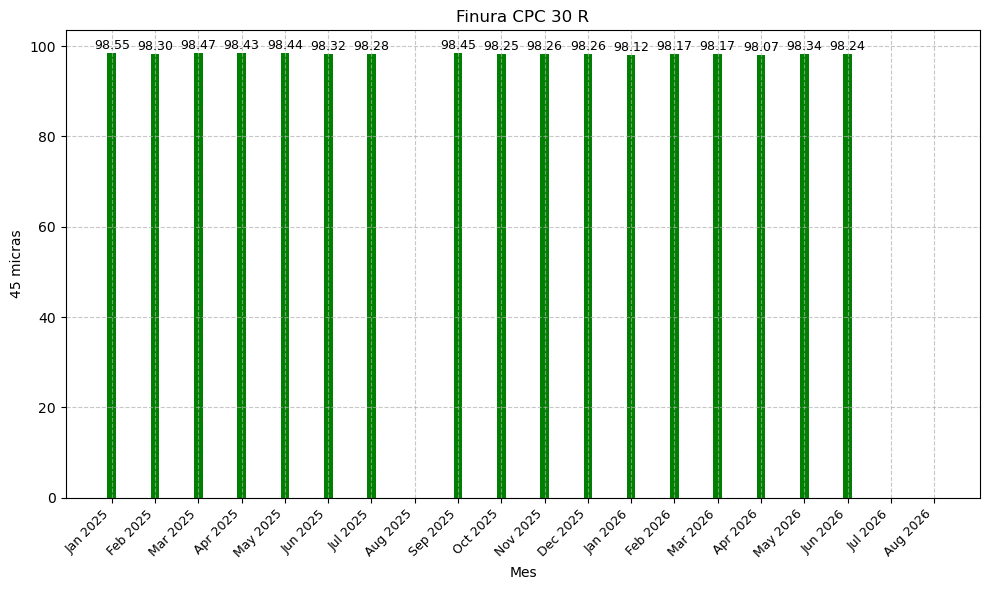

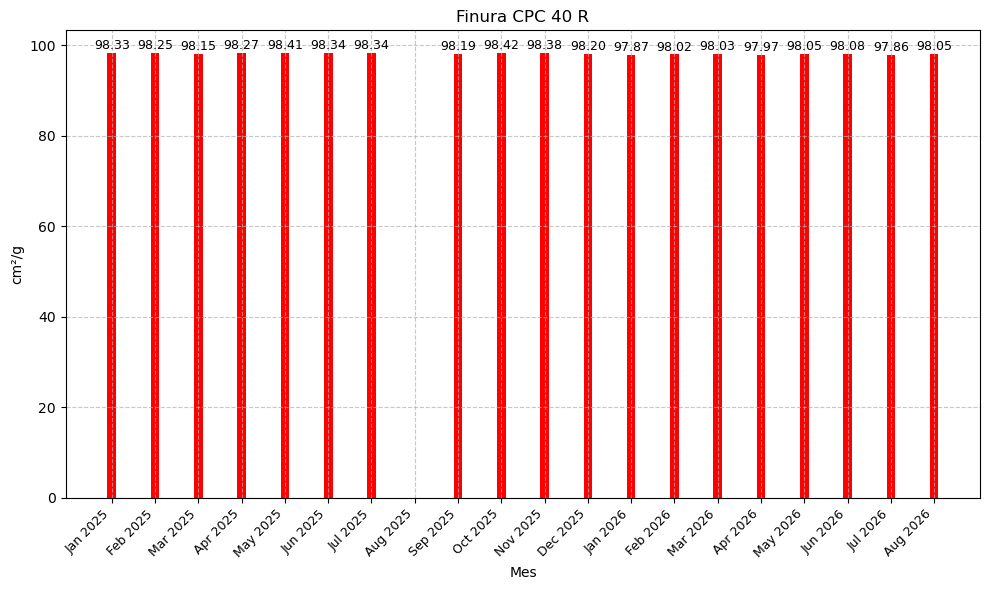

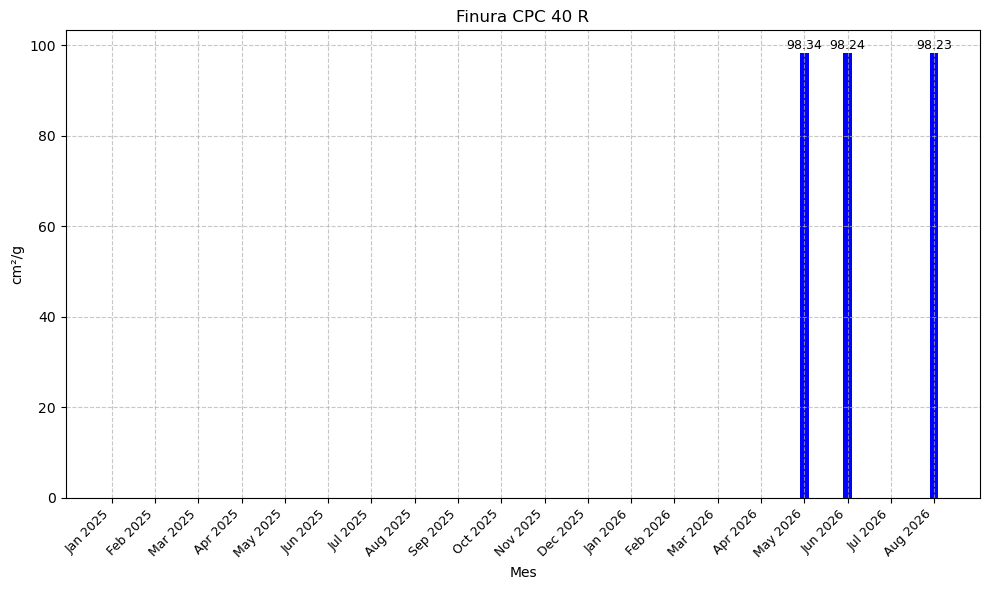

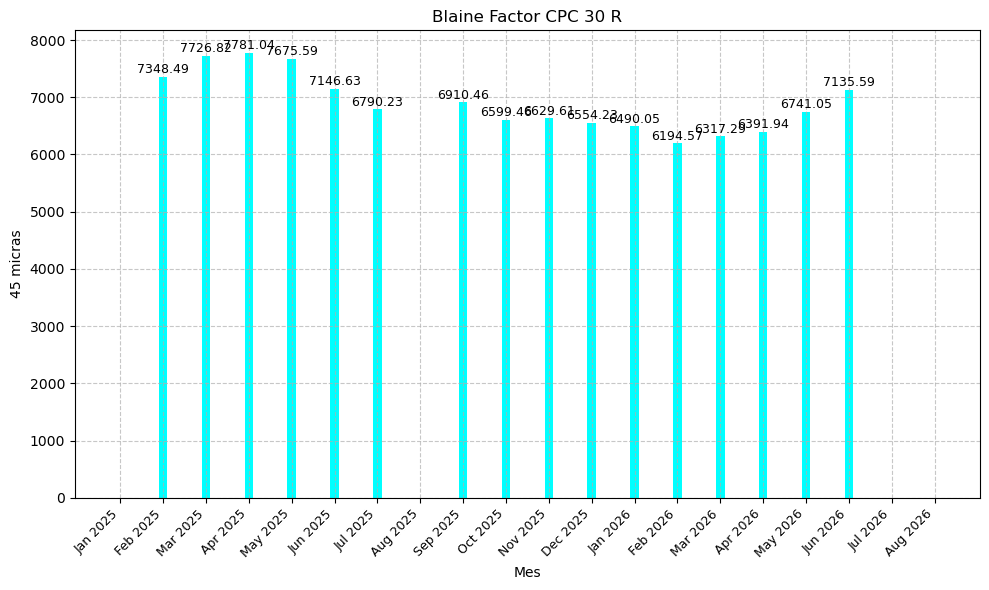

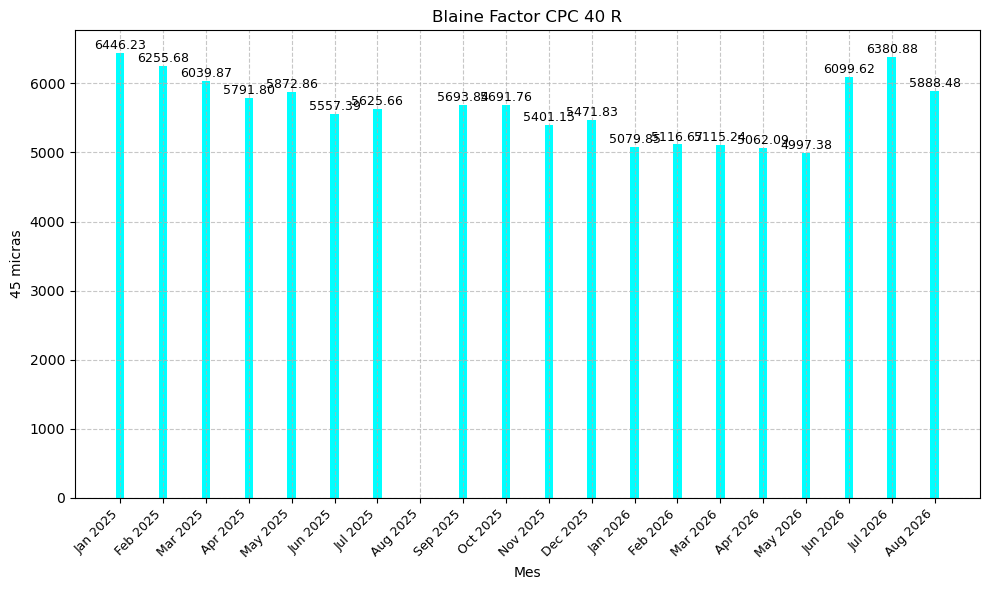

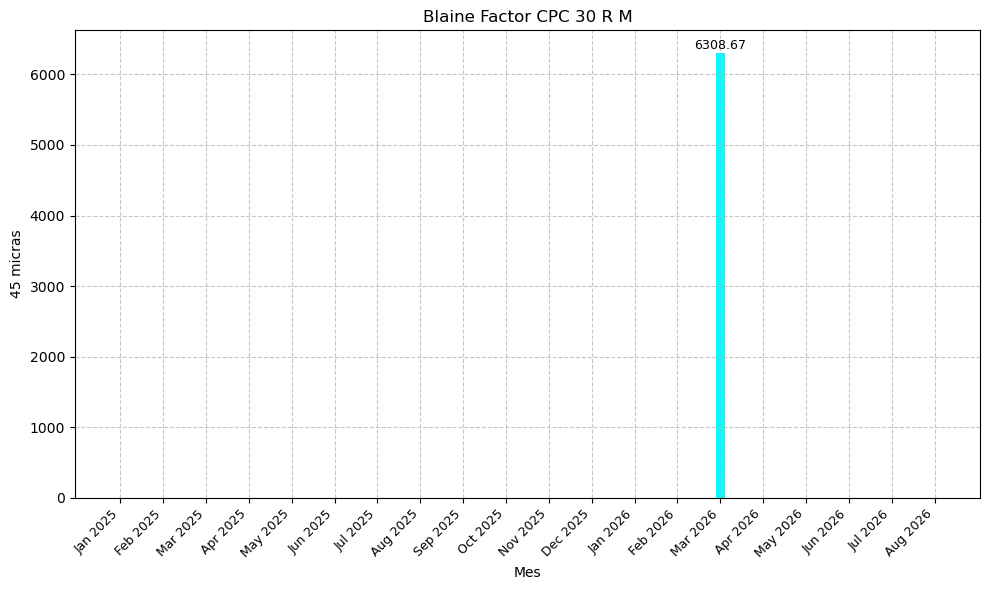

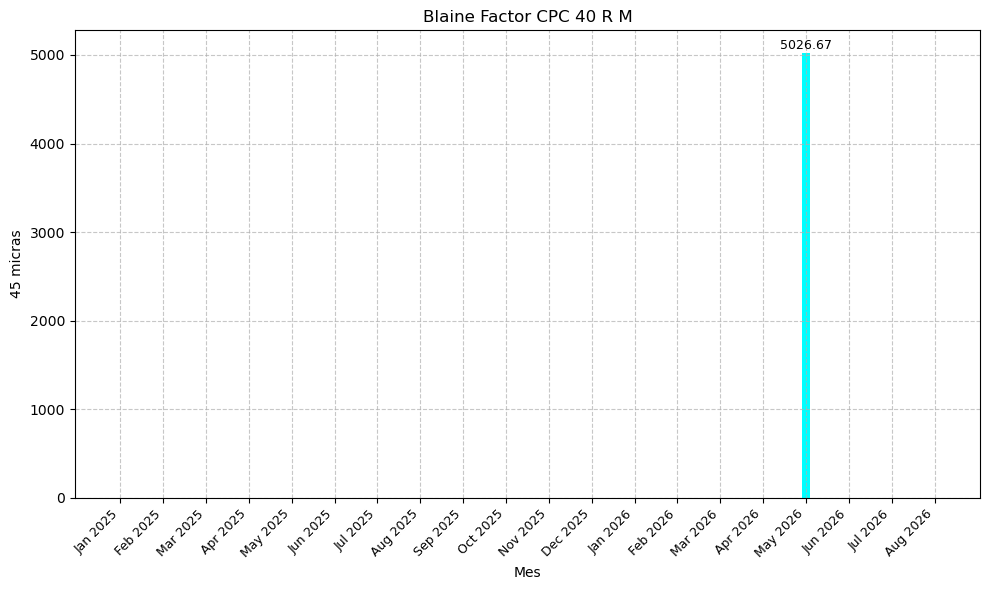

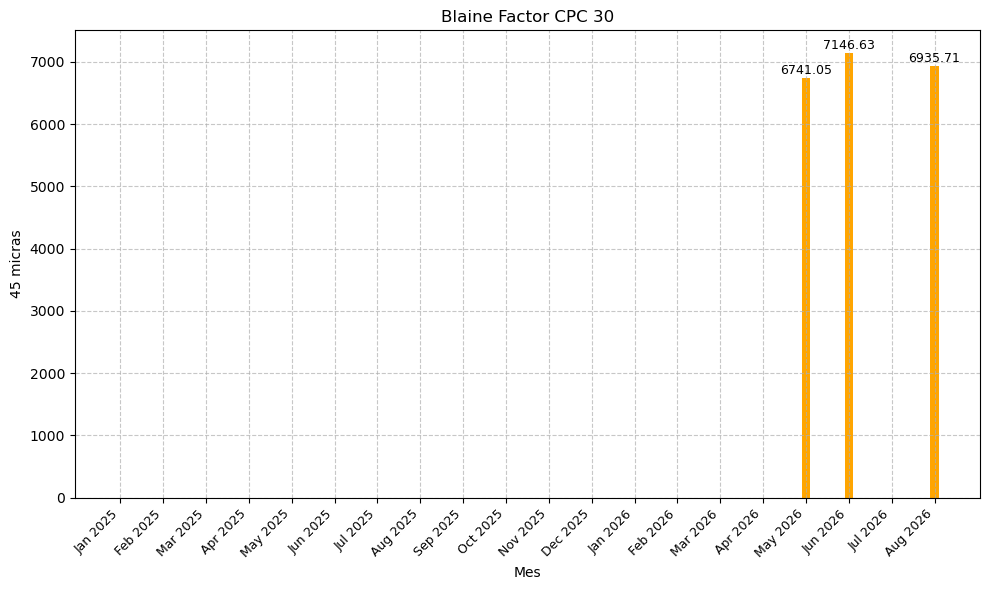

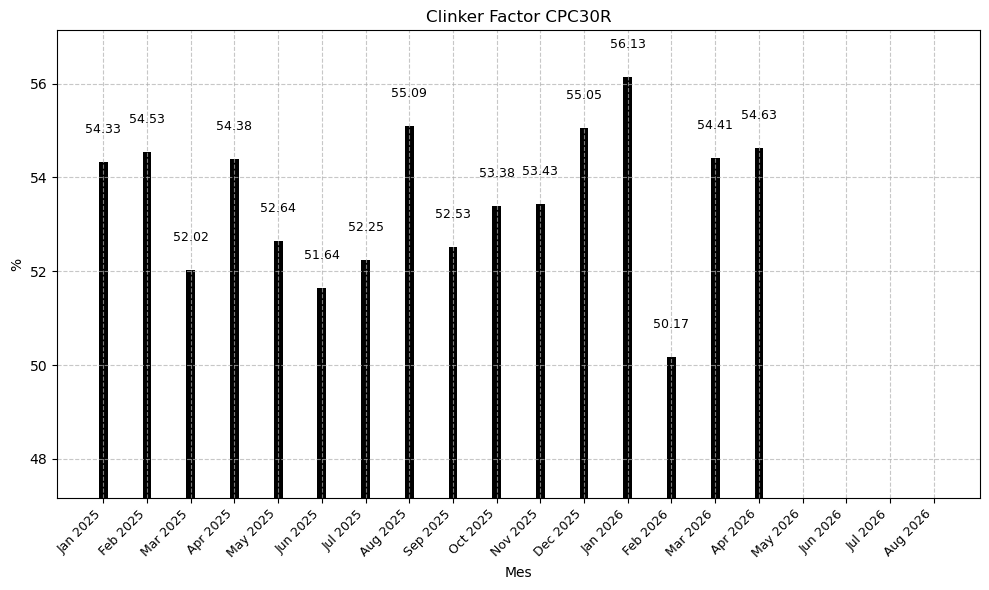

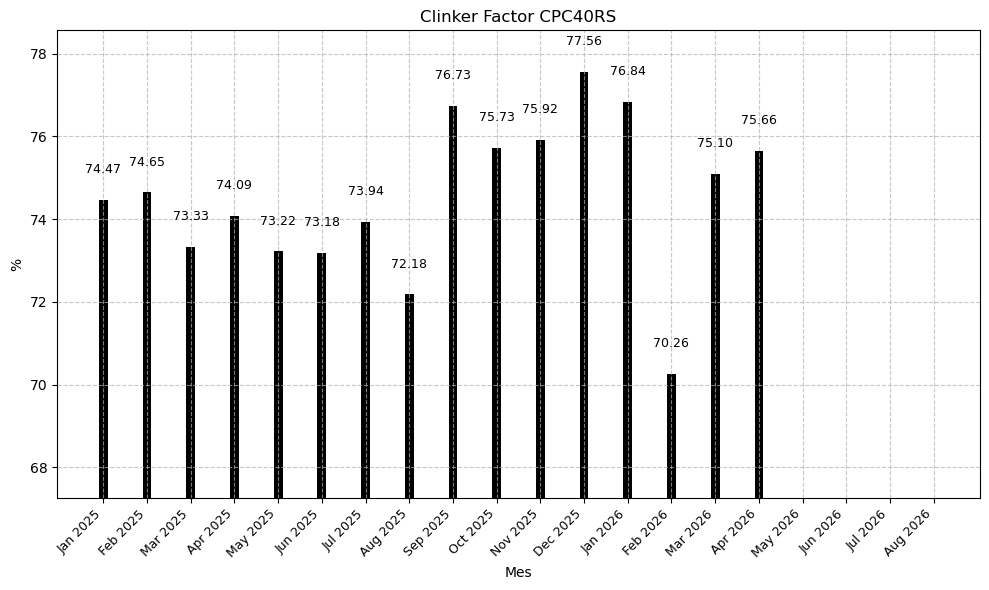


=== Promedios por períodos: Ene-Dic 2024 vs Ene-Dic 2025 ===

Contenido de promedios_periodos:
                                           Ene-Dic 2025  Ene-Dic 2026  \
MX-TEP-S01-611007-MX1-60003-03-HOR-M00-QM     98.364434     98.184588   
MX-TEP-S01-614010-MX1-60003-03-HOR-M00-QM     98.298849     97.989694   
MX-TEP-S01-611015-MX2-60003-03-HOR-M00-QM           NaN     98.268477   
MX-TEP-BLN-611007-MX1-60003-03-HOR-M00-QM   7116.255665   6545.080563   
MX-TEP-BLN-614010-MX1-60003-03-HOR-M00-QM   5804.369114   5467.525628   
MX-TEP-BLN-611007-MX1-60003-03-HOR-LG0-QM           NaN   6308.666667   
MX-TEP-BLN-614010-MX1-60003-03-HOR-LG0-QM           NaN   5026.666667   
MX-TEP-BLN-611015-MX2-60003-03-HOR-M00-QM           NaN   6941.132170   
Clinker Factor CPC30R                         53.438771     53.835233   
Clinker Factor CPC40RS                        74.582640     74.463757   

                                           Diferencia (2026 - 2025)  
MX-TEP-S01-611007-MX1-60003-03

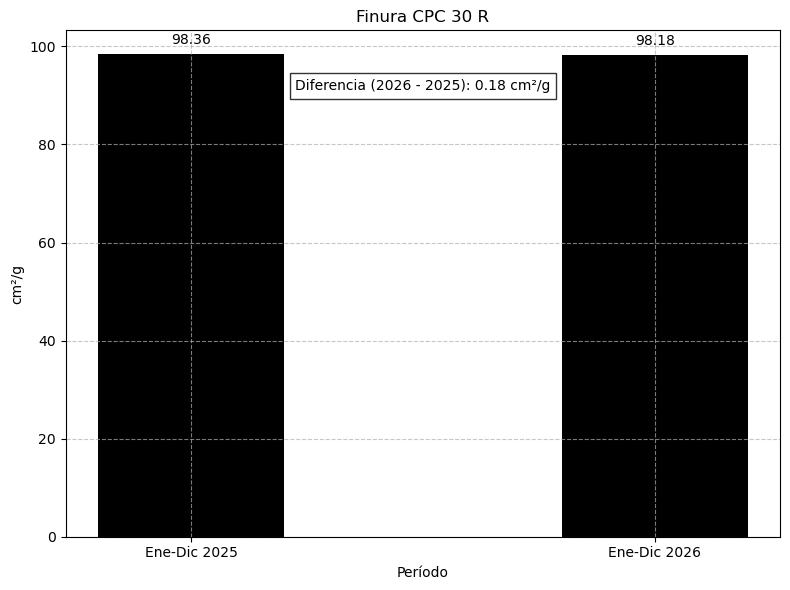

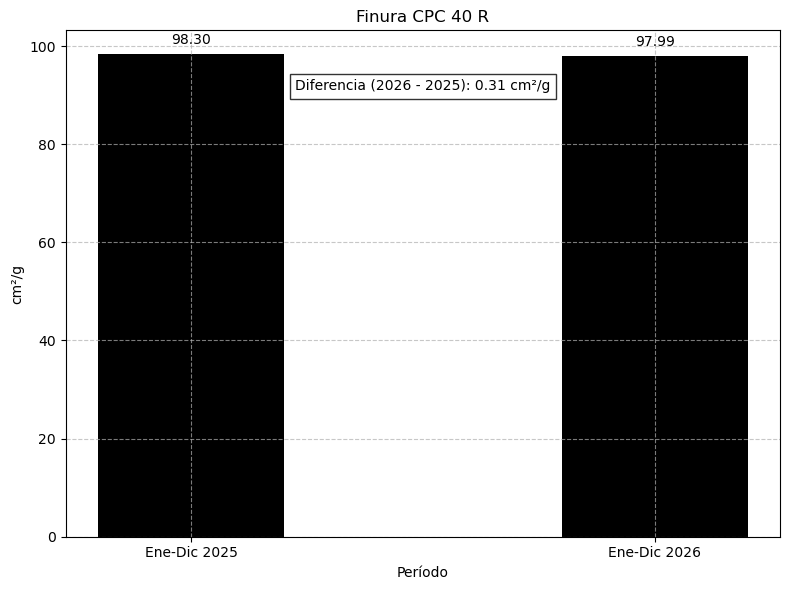

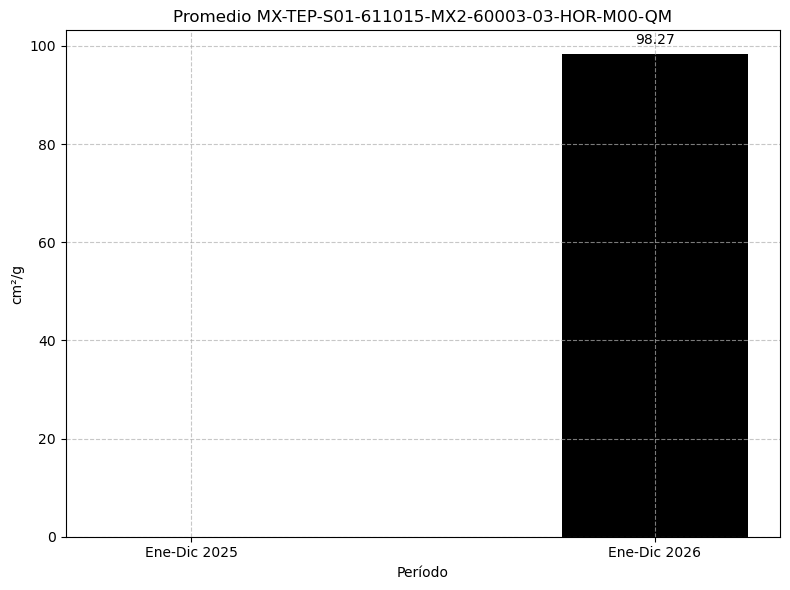

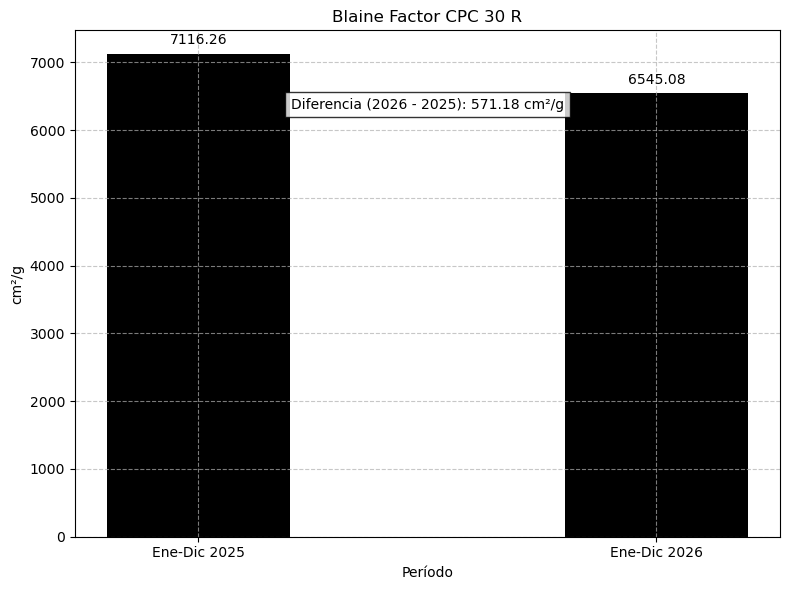

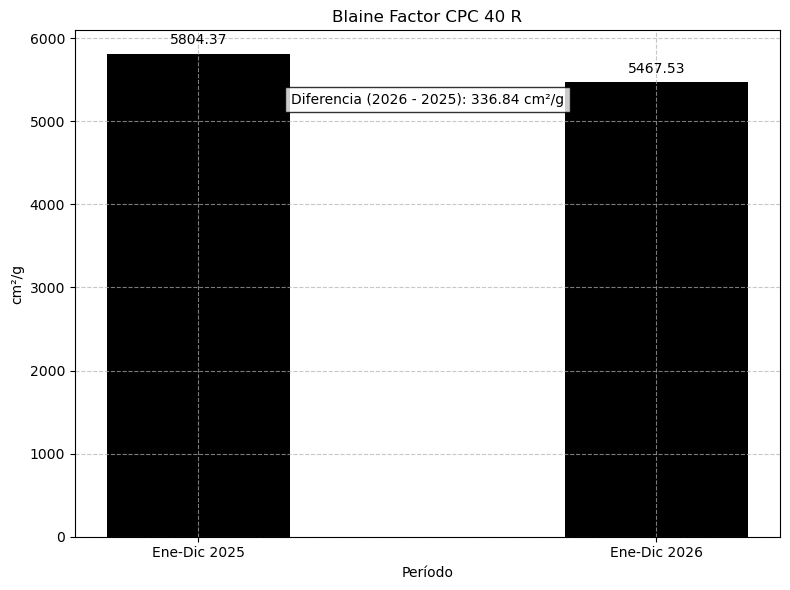

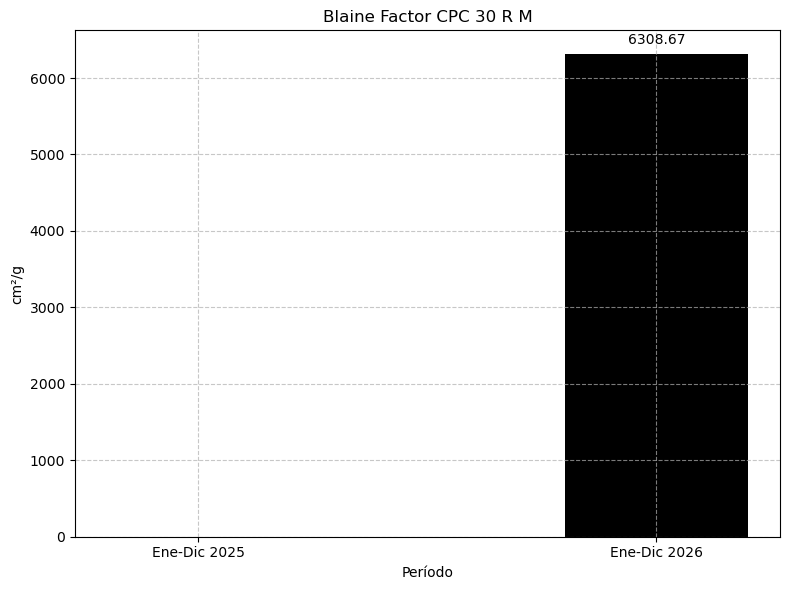

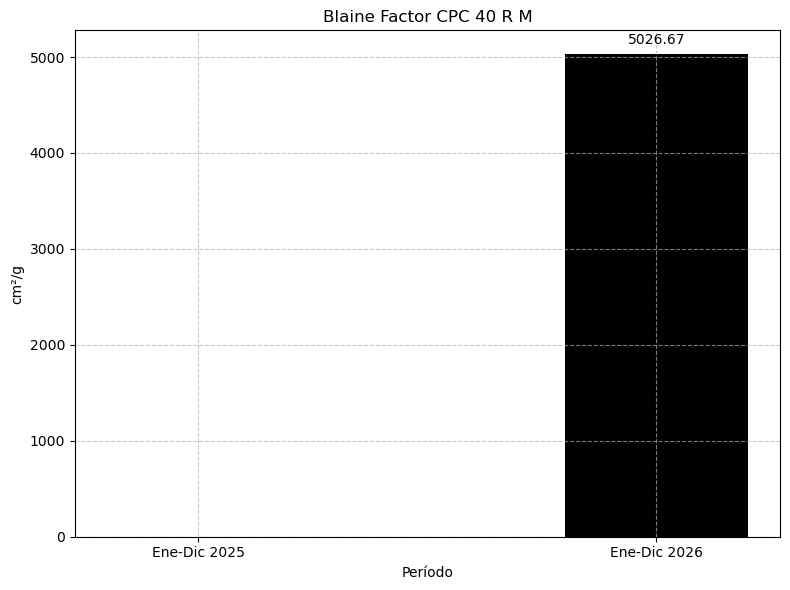

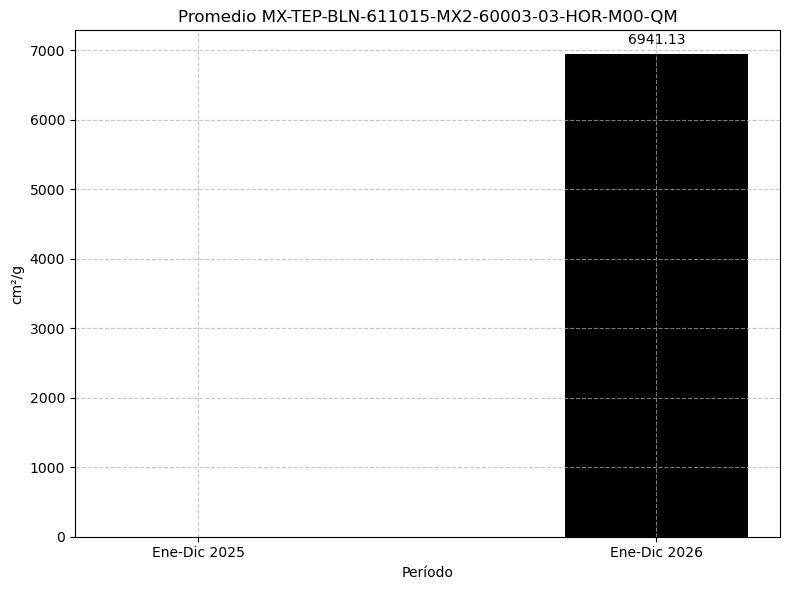

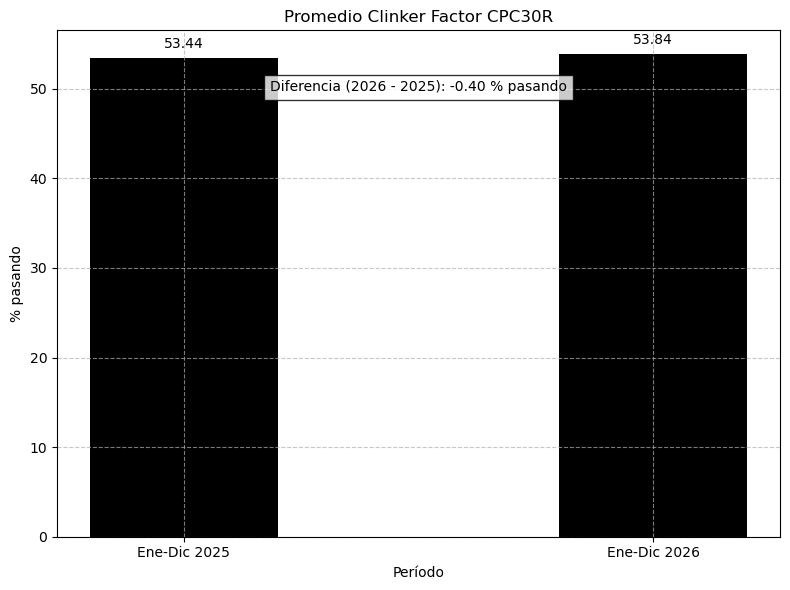

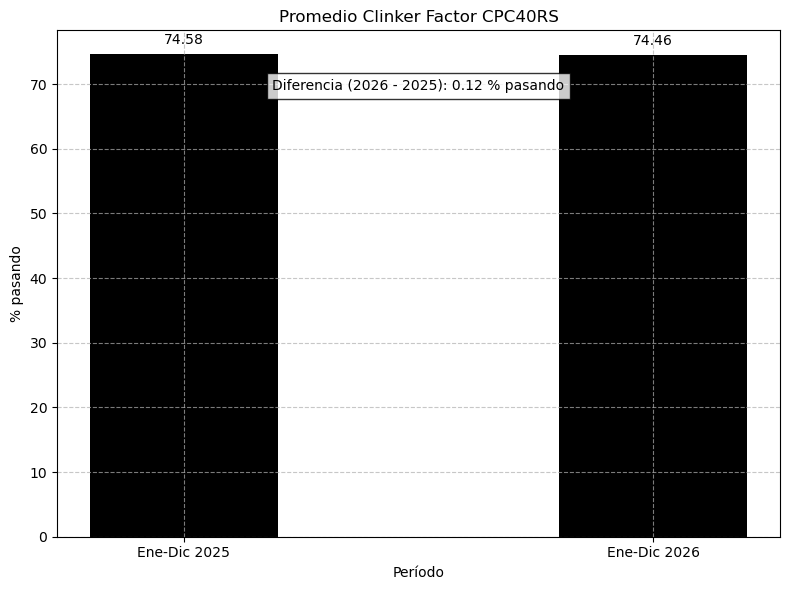

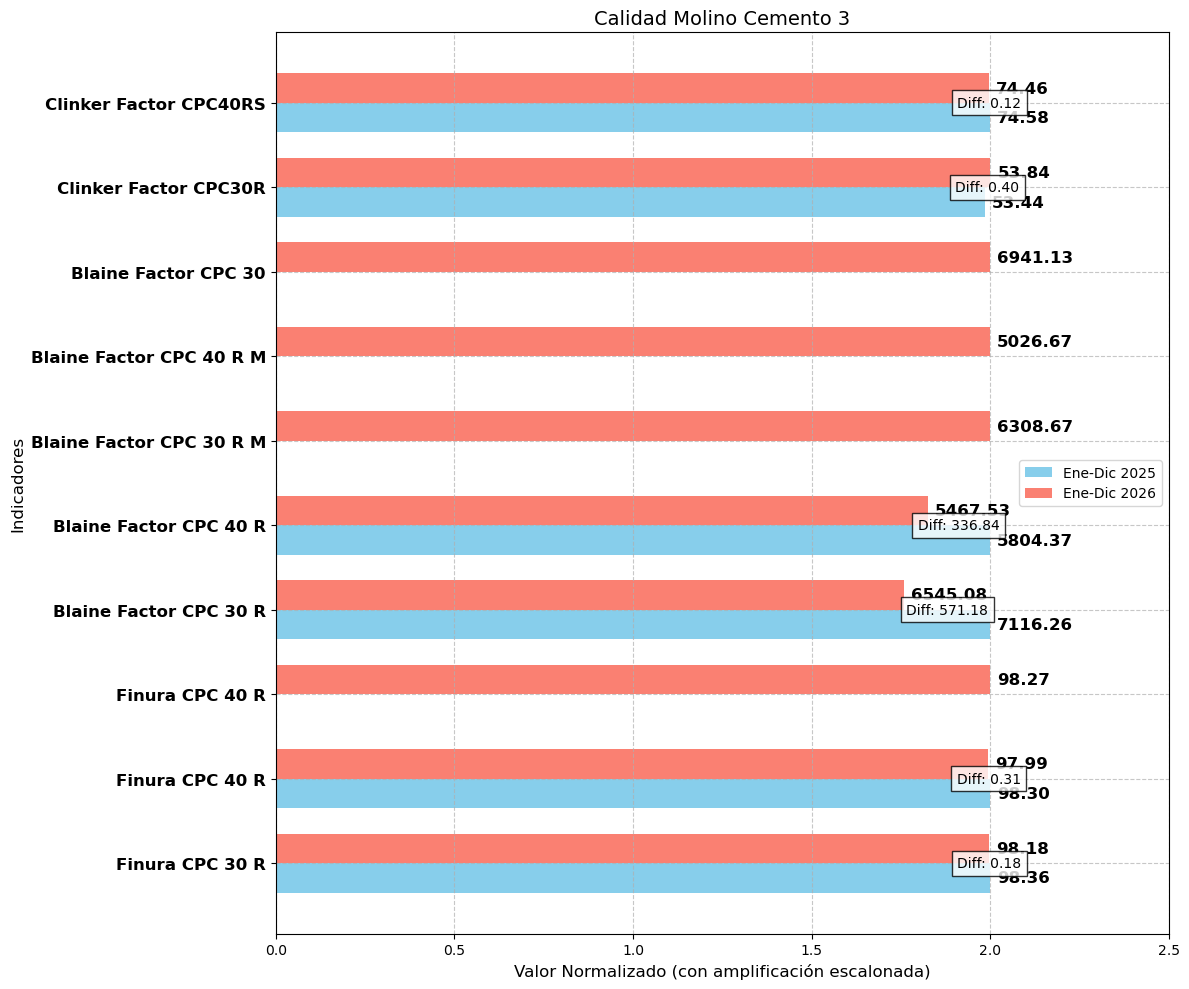

Guardado: Tepeaca_calidad_FM03_promedios_mensuales.xlsx
Guardado: Tepeaca_calidad_FM03_promedios_periodos.xlsx


In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Diccionario meses español → número
meses_es_a_num = {
    'Enero': 1, 'Febrero': 2, 'Marzo': 3, 'Abril': 4, 'Mayo': 5, 'Junio': 6,
    'Julio': 7, 'Agosto': 8, 'Septiembre': 9, 'Octubre': 10, 'Noviembre': 11, 'Diciembre': 12
}

# Paso 1: Definir los tags de Finura, Blaine
list_tags = [
            'MX-TEP-S01-611007-MX1-60003-03-HOR-M00-QM',  # Finura CPC30R
            'MX-TEP-S01-614010-MX1-60003-03-HOR-M00-QM',  # Finura CPC40RS
            'MX-TEP-S01-611015-MX2-60003-03-HOR-M00-QM',  #Finura CPC30
            'MX-TEP-BLN-611007-MX1-60003-03-HOR-M00-QM',  # Blaine CPC30R
            'MX-TEP-BLN-614010-MX1-60003-03-HOR-M00-QM',  # Blaine CPC40RS
            'MX-TEP-BLN-611007-MX1-60003-03-HOR-LG0-QM', 
            'MX-TEP-BLN-614010-MX1-60003-03-HOR-LG0-QM',
            'MX-TEP-BLN-611015-MX2-60003-03-HOR-M00-QM'   # Blaine CPC30
]

blaine_tags = [
            'MX-TEP-BLN-611007-MX1-60003-03-HOR-M00-QM',  # Blaine CPC30R
            'MX-TEP-BLN-614010-MX1-60003-03-HOR-M00-QM',  # Blaine CPC40RS
            'MX-TEP-BLN-611007-MX1-60003-03-HOR-LG0-QM', 
            'MX-TEP-BLN-614010-MX1-60003-03-HOR-LG0-QM',
            'MX-TEP-BLN-611015-MX2-60003-03-HOR-M00-QM'
]

# Paso 2: Extraer datos y calcular promedios mensuales
meses = pd.date_range(start="2025-01-01", end="2026-08-10", freq="MS").strftime("%Y-%m").tolist()
meses_nombres = pd.date_range(start="2025-01-01", end="2026-08-10", freq="MS").strftime("%b %Y").tolist()
promedios_mensuales = pd.DataFrame(index=meses)

for tag in list_tags:
    try:
        data = get_recorded_values('2025-01-01 00:00:00', '2026-08-10 23:59:59', tag)
        print(f"Datos cargados para {tag}: {len(data)} filas, Tipo de data: {type(data)}")
        
        tag_data = pd.DataFrame()
        tag_data = PI_to_dataframe(data, tag_data, tag, 0)
        
        if tag_data.empty or tag_data[tag].isna().all():
            print(f"Advertencia: No se cargaron datos válidos para {tag}")
            promedios_mensuales[tag] = np.nan
            continue
        
        tag_data['Time'] = pd.to_datetime(tag_data['Time'], format='%m/%d/%Y %I:%M:%S %p', errors='coerce')
        if tag_data['Time'].isna().any():
            print(f"Advertencia: Algunas fechas no se pudieron convertir a datetime para {tag}")
            print(f"Fechas problemáticas: {tag_data[tag_data['Time'].isna()]['Time']}")
        
        tag_data = tag_data.set_index('Time')
        
        if tag in blaine_tags:
            print(f"Aplicando filtro 1000 < valor < 8000 para {tag}")
            tag_data.loc[(tag_data[tag] <= 1000) | (tag_data[tag] >= 8000), tag] = np.nan
        
        print(f"\nEstadísticas para {tag}:")
        print(tag_data[tag].describe())
        print(f"Valores nulos para {tag}: {tag_data[tag].isna().sum()}")
        
        tag_data['Mes'] = tag_data.index.strftime('%Y-%m')
        promedios_mensuales[tag] = tag_data.groupby('Mes')[tag].mean()
        
        print(f"\nConteo de datos por mes para {tag}:")
        print(tag_data.groupby('Mes').size())
        
    except Exception as e:
        print(f"Error al procesar {tag}: {e}")
        promedios_mensuales[tag] = np.nan

# Asignar NaN a meses sin datos
for tag in list_tags:
    for mes in meses:
        if mes not in promedios_mensuales.index or pd.isna(promedios_mensuales.loc[mes, tag]):
            promedios_mensuales.loc[mes, tag] = np.nan

print("\nTabla de promedios mensuales:")
print(promedios_mensuales)


# Exportar promedios por período a Excel (fácil de abrir en tu PC)
promedios_mensuales.to_excel('Promedios_Mensuales_2024_vs_2025.xlsx', index=True)
print("\n¡Archivo guardado! Busca 'Promedios_Periodos_2024_vs_2025.xlsx' en tu carpeta actual.")




# === AGREGAR CLINKER FACTOR DEL EXCEL (flexible para cualquier cantidad de productos) ===
excel_file = r"C:\Users\damercado\OneDrive - CEMEX\Tepeaca_Clinker_Factor.xlsx"
sheet_name = 'MC3'  # Cambia aquí si usas otra pestaña (MC3, MC5, etc.)

try:
    clinker_df = pd.read_excel(excel_file, sheet_name=sheet_name)
    print("Excel leído. Primeras filas:")
    print(clinker_df.head(10))
    
    clinker_df['Mes'] = clinker_df['Mes'].astype(str).str.strip()
    clinker_df['Año'] = clinker_df['Año'].astype(str).str.strip()
    
    clinker_df = clinker_df.dropna(subset=['Año', 'Mes'])
    
    clinker_df['Año'] = pd.to_numeric(clinker_df['Año'], errors='coerce').astype('Int64')
    clinker_df = clinker_df.dropna(subset=['Año'])
    
    clinker_df['Month_num'] = clinker_df['Mes'].map(meses_es_a_num)
    clinker_df = clinker_df.dropna(subset=['Month_num'])
    
    clinker_df['Mes_key'] = clinker_df['Año'].astype(str) + '-' + clinker_df['Month_num'].astype(int).astype(str).str.zfill(2)
    clinker_df = clinker_df.set_index('Mes_key')
    
    # Detectar automáticamente columnas de productos (más flexible)
    clinker_columns = [col for col in clinker_df.columns 
                       if col.upper().startswith(('CPC_', 'CPO_', 'TYPE', 'TIPO', 'CEM_', 'OPC_')) 
                       or 'CLINKER' in col.upper() or 'FACTOR' in col.upper() or 'RB' in col.upper()]
    
    if not clinker_columns:
        print("No se encontraron columnas de productos (buscando CPC_, CPO_, Type, tipo, CEM_, OPC_, CLINKER, FACTOR o RB)")
    else:
        print(f"Productos detectados: {clinker_columns}")
        
        for col_excel in clinker_columns:
            prod_name = col_excel.replace('CPC_', 'CPC').replace('CPO_', 'CPO').replace('_', '')
            col_final = f'Clinker Factor {prod_name}'
            
            promedios_mensuales[col_final] = np.nan
            
            for idx in clinker_df.index:
                if idx in promedios_mensuales.index:
                    promedios_mensuales.loc[idx, col_final] = clinker_df.loc[idx, col_excel]
            
            print(f"\n¡Clinker agregado para {prod_name}: '{col_final}'")
            print("Valores agregados (completo):")
            print(promedios_mensuales[col_final])
except Exception as e:
    print("Error al leer/agregar Excel:", str(e))





# Paso 3: Imprimir resultados (incluyendo Clinkers)
for tag in list_tags + [col for col in promedios_mensuales.columns if col.startswith('Clinker Factor')]:
    unit = '% pasando' if 'S01' in tag or 'Clinker' in tag else 'cm²/g'
    print(f"\nPromedios mensuales para {tag} ({unit}):")
    for mes, prom in zip(meses_nombres, promedios_mensuales.get(tag, pd.Series([np.nan]*len(meses_nombres)))):
        print(f"{mes}: {prom:.2f} {unit}" if not np.isnan(prom) else f"{mes}: NaN")

# Paso 4: Generar gráficas de barras (base + una extra por Clinker/producto)
metricas_base = [
    ('MX-TEP-S01-611007-MX1-60003-03-HOR-M00-QM', 'Finura CPC 30 R', '45 micras', 'green'),
    ('MX-TEP-S01-614010-MX1-60003-03-HOR-M00-QM',  'Finura CPC 40 R', 'cm²/g', 'red'),
    ('MX-TEP-S01-611015-MX2-60003-03-HOR-M00-QM',  'Finura CPC 40 R', 'cm²/g', 'blue'),
    ('MX-TEP-BLN-611007-MX1-60003-03-HOR-M00-QM', 'Blaine Factor CPC 30 R', '45 micras', 'cyan'),
    ('MX-TEP-BLN-614010-MX1-60003-03-HOR-M00-QM', 'Blaine Factor CPC 40 R', '45 micras', 'cyan'),
    ('MX-TEP-BLN-611007-MX1-60003-03-HOR-LG0-QM', 'Blaine Factor CPC 30 R M', '45 micras', 'cyan'),
    ('MX-TEP-BLN-614010-MX1-60003-03-HOR-LG0-QM','Blaine Factor CPC 40 R M', '45 micras', 'cyan'), 
    ('MX-TEP-BLN-611015-MX2-60003-03-HOR-M00-QM','Blaine Factor CPC 30', '45 micras', 'orange'), 
    
]

for col, title, ylabel, color in metricas_base:
    plt.figure(figsize=(10, 6))
    x = np.arange(len(meses_nombres))
    values = promedios_mensuales[col].fillna(0)
    
    bars = plt.bar(x, values, color=color, width=0.2)
    
    for bar in bars:
        height = bar.get_height()
        if height != 0:
            plt.text(bar.get_x() + bar.get_width() / 2, height + 0.002 * height,
                     f'{height:.2f}', ha='center', va='bottom', fontsize=9)
    
    plt.title(title, fontsize=12)
    plt.xlabel('Mes', fontsize=10)
    plt.ylabel(ylabel, fontsize=10)
    plt.xticks(x, meses_nombres, rotation=45, ha='right', fontsize=9)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

# Gráficas extras: una por cada producto/Clinker detectado
clinker_columns_final = [col for col in promedios_mensuales.columns if col.startswith('Clinker Factor')]

for col_clinker in clinker_columns_final:
    prod_name = col_clinker.replace('Clinker Factor ', '')
    
    plt.figure(figsize=(10, 6))
    x = np.arange(len(meses_nombres))
    values = promedios_mensuales[col_clinker].fillna(0)
    
    bars = plt.bar(x, values, color='black', width=0.2)
    
    for bar in bars:
        height = bar.get_height()
        if height != 0:
            offset = height * 0.001 + 0.5
            plt.text(bar.get_x() + bar.get_width() / 2, 
                     height + offset, 
                     f'{height:.2f}', 
                     ha='center', va='bottom', fontsize=9)
    
    plt.title(f'Clinker Factor {prod_name}', fontsize=12)
    plt.xlabel('Mes', fontsize=10)
    plt.ylabel('%', fontsize=10)
    plt.xticks(x, meses_nombres, rotation=45, ha='right', fontsize=9)
    plt.grid(True, linestyle='--', alpha=0.7)
    
    # ESCALA Y DINÁMICA Y "MÁS CERCANA" PARA BARRAS ALTAS
    clinker_values = values[values > 0]
    if len(clinker_values) > 0:
        min_val = clinker_values.min()
        max_val = clinker_values.max()
        
        margen_bajo = max(3, (max_val - min_val) * 0.05)
        margen_alto = max(1, (max_val - min_val) * 0.02)
        
        plt.ylim(max(0, min_val - margen_bajo), max_val + margen_alto)
    else:
        plt.ylim(50, 90)
    
    plt.tight_layout()
    plt.show()


# Paso 9: Calcular y mostrar promedios por períodos
print("\n=== Promedios por períodos: Ene-Dic 2024 vs Ene-Dic 2025 ===")

periodo_2024 = ['2025-01', '2025-02', '2025-03', '2025-04','2025-05', '2025-06', '2025-07', '2025-08', '2025-09', '2025-10', '2025-11','2025-12']
periodo_2025 = ['2026-01', '2026-02', '2026-03', '2026-04','2026-05', '2026-06', '2026-07', '2026-08', '2026-09', '2026-10', '2026-11','2026-12']

# Usamos todas las columnas (incluyendo Clinkers)
all_columns = [col for col, _, _, _ in metricas_base] + clinker_columns_final

promedios_periodos = pd.DataFrame(index=all_columns)

promedios_periodos['Ene-Dic 2025'] = promedios_mensuales.loc[periodo_2024, all_columns].mean()
promedios_periodos['Ene-Dic 2026'] = promedios_mensuales.loc[promedios_mensuales.index.intersection(periodo_2025), all_columns].mean()

promedios_periodos['Diferencia (2026 - 2025)'] = promedios_periodos['Ene-Dic 2025'] - promedios_periodos['Ene-Dic 2026']

print("\nContenido de promedios_periodos:")
print(promedios_periodos)

# Diccionario de títulos amigables
titulos_amigables = {
    'MX-TEP-S01-611007-MX1-60003-03-HOR-M00-QM': 'Finura CPC 30 R', 
    'MX-TEP-S01-614010-MX1-60003-03-HOR-M00-QM':  'Finura CPC 40 R', 
    'MX-TEP-BLN-611007-MX1-60003-03-HOR-M00-QM': 'Blaine Factor CPC 30 R', 
    'MX-TEP-BLN-614010-MX1-60003-03-HOR-M00-QM': 'Blaine Factor CPC 40 R',
    'MX-TEP-BLN-611007-MX1-60003-03-HOR-LG0-QM': 'Blaine Factor CPC 30 R M',
    'MX-TEP-BLN-614010-MX1-60003-03-HOR-LG0-QM':'Blaine Factor CPC 40 R M',   
}

# Agregar títulos para Clinkers detectados automáticamente
for col_clinker in clinker_columns_final:
    prod_name = col_clinker.replace('Clinker Factor ', '')
    titulos_amigables[col_clinker] = f'Promedio Clinker Factor {prod_name}'

# Gráficas por período (con títulos amigables)
for col in all_columns:
    # Usa el título amigable si existe, si no el tag original
    title = titulos_amigables.get(col, f'Promedio {col}')
    
    ylabel = '% pasando' if 'Finura' in col or 'Clinker' in col else 'cm²/g'
    color = 'black'  # puedes personalizar
    
    plt.figure(figsize=(8, 6))
    x = np.array([0, 1])
    values = promedios_periodos.loc[col, ['Ene-Dic 2025', 'Ene-Dic 2026']].fillna(0).values
    
    bars = plt.bar(x, values, color=color, width=0.4)
    
    for bar in bars:
        height = bar.get_height()
        if height != 0:
            plt.text(bar.get_x() + bar.get_width() / 2, height + 0.015 * height,
                     f'{height:.2f}', ha='center', va='bottom', fontsize=10)
    
    diferencia = promedios_periodos.loc[col, 'Diferencia (2026 - 2025)']
    if not pd.isna(diferencia):
        y_pos = (values[0] + values[1]) / 2 - max(values) * 0.05
        plt.text(0.5, y_pos, f'Diferencia (2026 - 2025): {diferencia:.2f} {ylabel}',
                 ha='center', va='top', fontsize=10, bbox=dict(facecolor='white', alpha=0.8, edgecolor='black'))
    
    plt.title(title)
    plt.xlabel('Período')
    plt.ylabel(ylabel)
    plt.xticks(x, ['Ene-Dic 2025', 'Ene-Dic 2026'])
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()






# Paso 10: Gráfica comparativa horizontal (incluye todos los Clinkers)
indicadores = metricas_base.copy()  # Finura y Blaine

# Agregar todos los Clinkers detectados
for col_clinker in clinker_columns_final:
    prod_name = col_clinker.replace('Clinker Factor ', '')
    indicadores.append((col_clinker, f'Clinker Factor {prod_name}', '%', 'black'))

# Preparar datos
normalized_data = promedios_periodos.loc[[ind[0] for ind in indicadores], ['Ene-Dic 2025', 'Ene-Dic 2026']].copy()
normalized_data_np = normalized_data.fillna(0).to_numpy()

scaled_data = normalized_data_np.copy()
for i in range(normalized_data_np.shape[0]):
    max_val = max(normalized_data_np[i, 0], normalized_data_np[i, 1])
    if max_val > 0:
        scaled_data[i, :] = normalized_data_np[i, :] / max_val

large_diff_threshold = 0.10
medium_diff_threshold = 0.02
large_amplification = 3.0
medium_amplification = 1.5
small_amplification = 1.05

adjusted_data = scaled_data.copy()
for i in range(normalized_data_np.shape[0]):
    val_2024 = normalized_data_np[i, 0]
    val_2025 = normalized_data_np[i, 1]
    if val_2024 == 0 or val_2025 == 0:
        continue
    rel_diff = abs((val_2025 - val_2024) / val_2024) if val_2024 != 0 else 0
    
    if rel_diff >= large_diff_threshold:
        dynamic_amplification = large_amplification + (rel_diff * 10)
        adjusted_data[i, 0] = scaled_data[i, 0]
        adjusted_data[i, 1] = scaled_data[i, 1] + (scaled_data[i, 1] - scaled_data[i, 0]) * (dynamic_amplification - 1)
    elif rel_diff >= medium_diff_threshold:
        adjusted_data[i, 0] = scaled_data[i, 0]
        adjusted_data[i, 1] = scaled_data[i, 1] + (scaled_data[i, 1] - scaled_data[i, 0]) * (medium_amplification - 1)
    else:
        adjusted_data[i, 0] = scaled_data[i, 0]
        adjusted_data[i, 1] = scaled_data[i, 1] + (scaled_data[i, 1] - scaled_data[i, 0]) * (small_amplification - 1)

normalized_data = pd.DataFrame(adjusted_data, index=normalized_data.index, columns=normalized_data.columns)

global_max = normalized_data.max().max()
normalized_data = normalized_data / (global_max * 0.5) if global_max > 0 else normalized_data
normalized_data = normalized_data.fillna(0)

plt.figure(figsize=(12, 10))
n_indicadores = len(indicadores)
y = np.arange(n_indicadores)
height = 0.35

bars1 = plt.barh(y - height/2, normalized_data['Ene-Dic 2025'], height, label='Ene-Dic 2025', color='skyblue')
bars2 = plt.barh(y + height/2, normalized_data['Ene-Dic 2026'], height, label='Ene-Dic 2026', color='salmon')

for bars, period in [(bars1, 'Ene-Dic 2025'), (bars2, 'Ene-Dic 2026')]:
    for i, bar in enumerate(bars):
        width = bar.get_width()
        if width > 0:
            real_value = promedios_periodos.loc[indicadores[i][0], period]
            if not pd.isna(real_value):
                plt.text(width + 0.02, bar.get_y() + bar.get_height()/2,
                         f'{real_value:.2f}', ha='left', va='center', fontsize=12, fontweight='bold')

for i, (col, _, _, _) in enumerate(indicadores):
    val_2024 = promedios_periodos.loc[col, 'Ene-Dic 2025']
    val_2025 = promedios_periodos.loc[col, 'Ene-Dic 2026']
    abs_diff = abs(val_2025 - val_2024) if not (pd.isna(val_2024) or pd.isna(val_2025)) else 0
    if abs_diff > 0:
        y_pos = y[i]
        x_pos = (normalized_data.loc[col, 'Ene-Dic 2025'] + normalized_data.loc[col, 'Ene-Dic 2026']) / 2
        plt.text(x_pos, y_pos, f'Diff: {abs_diff:.2f}', ha='center', va='center', fontsize=10, 
                 bbox=dict(facecolor='white', alpha=0.8, edgecolor='black'))

plt.title('Calidad Molino Cemento 3', fontsize=14)
plt.xlabel('Valor Normalizado (con amplificación escalonada)', fontsize=12)
plt.ylabel('Indicadores', fontsize=12)
plt.yticks(y, [label for _, label, _, _ in indicadores], fontsize=12, fontweight='bold')
plt.xlim(0, 2.5)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()




# Guardar tablas importantes automáticamente al final
import os

# Lista de DataFrames que quieres guardar (agrega los que tengas)
tablas_a_guardar = {
    'promedios_mensuales': promedios_mensuales if 'promedios_mensuales' in globals() else None,
    'promedios_periodos': promedios_periodos if 'promedios_periodos' in globals() else None,
    # Agrega más si tienes, ej: 'clinker_df': clinker_df
}

nombre_base = 'Tepeaca_calidad_FM03'  # o pon el nombre manual: 'Atotonilco', 'Zapotiltic', etc.

for nombre, df in tablas_a_guardar.items():
    if df is not None and isinstance(df, pd.DataFrame):
        archivo = f"{nombre_base}_{nombre}.xlsx"
        df.to_excel(archivo, index=True)
        print(f"Guardado: {archivo}")






Datos cargados para FI_411163.TPC: 422640 filas, Tipo de data: <class 'OSIsoft.AF.Asset.AFValues'>
Datos cargados para JI_422023.TPC: 422640 filas, Tipo de data: <class 'OSIsoft.AF.Asset.AFValues'>
Datos cargados para JI_422083.TPC: 422640 filas, Tipo de data: <class 'OSIsoft.AF.Asset.AFValues'>
Datos cargados para JI_422043.TPC: 422640 filas, Tipo de data: <class 'OSIsoft.AF.Asset.AFValues'>

Filas en operative_data: 422640

Primeras filas de operative_data:
                   Time  FI_411163.TPC  JI_422023.TPC  JI_422083.TPC  \
0  1/1/2025 12:00:00 AM     446.642242    3728.650391    4039.062744   
1  1/1/2025 12:02:00 AM     439.682709    3798.534912    4012.273682   
2  1/1/2025 12:04:00 AM     436.809204    3730.379150    4017.687988   
3  1/1/2025 12:06:00 AM     442.474884    3821.935059    4011.212158   
4  1/1/2025 12:08:00 AM     448.140564    3841.057617    3951.215820   

   JI_422043.TPC  
0      54.414169  
1      54.429928  
2      54.445686  
3      54.461441  
4      5

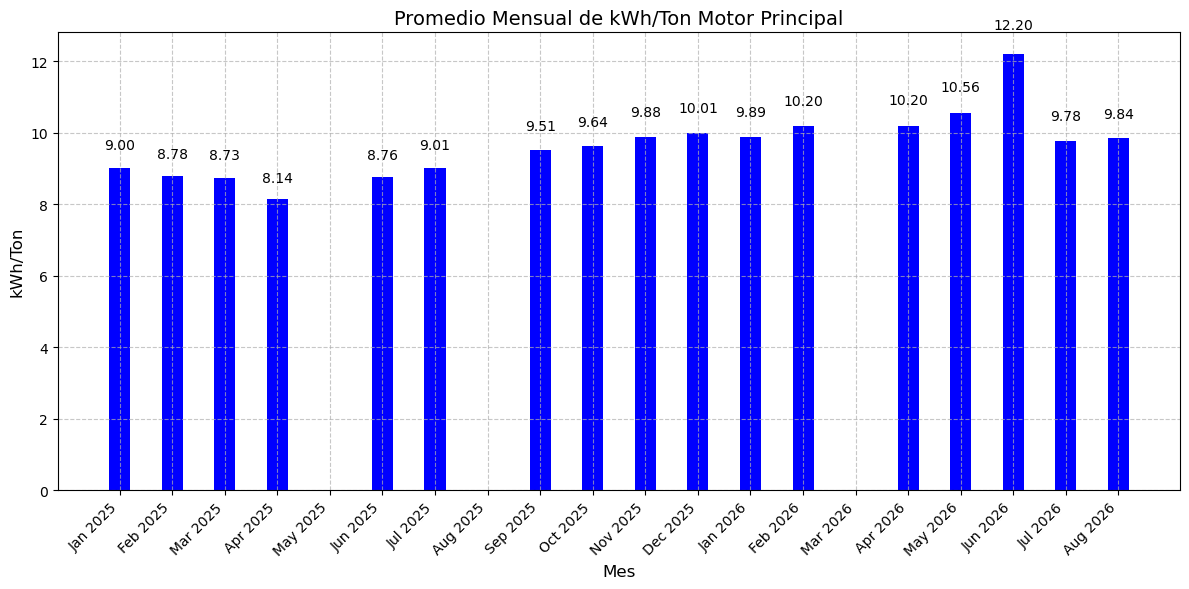

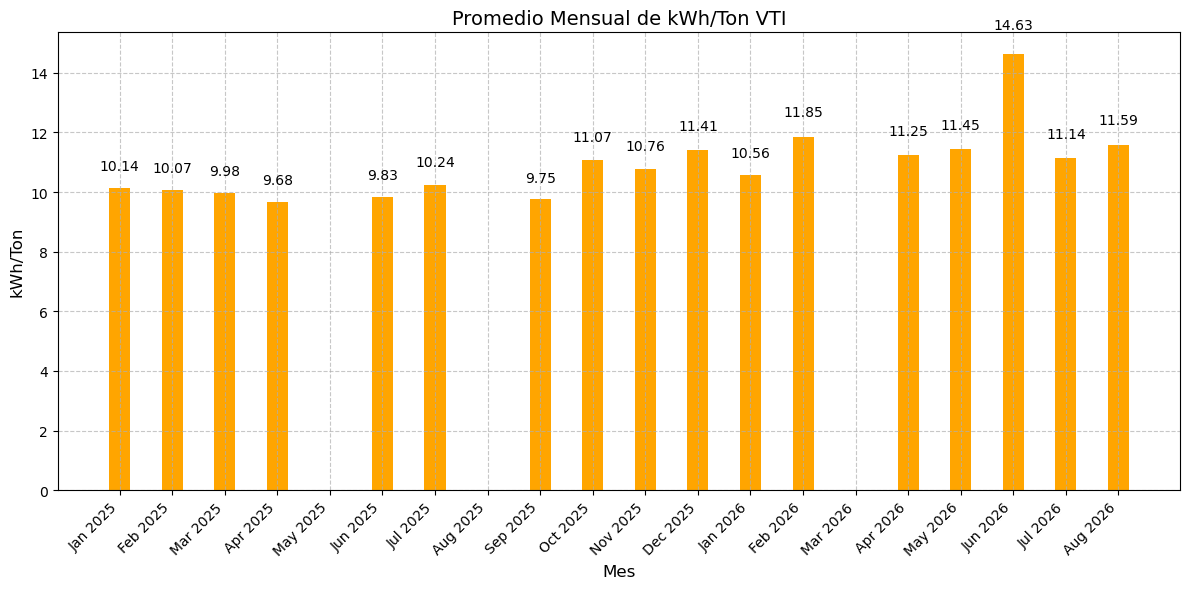

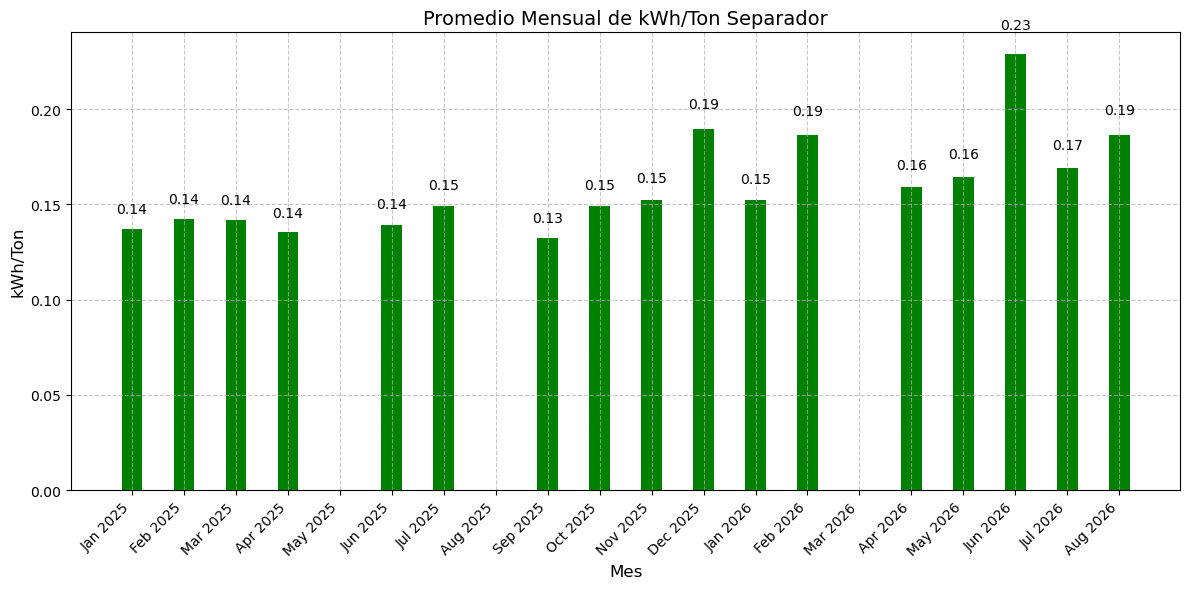

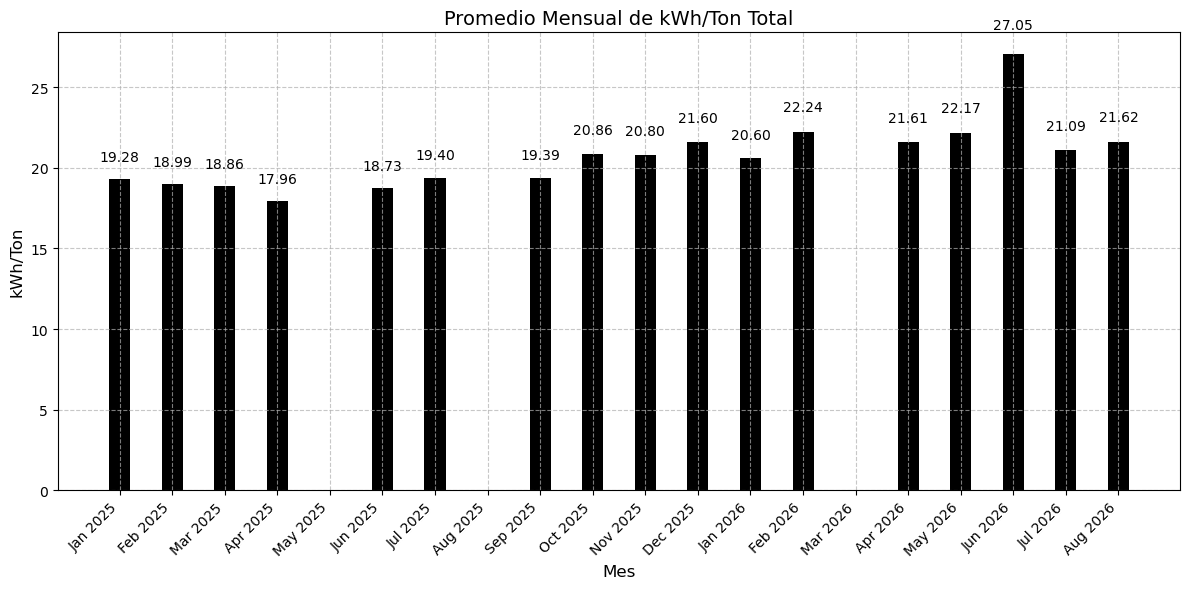

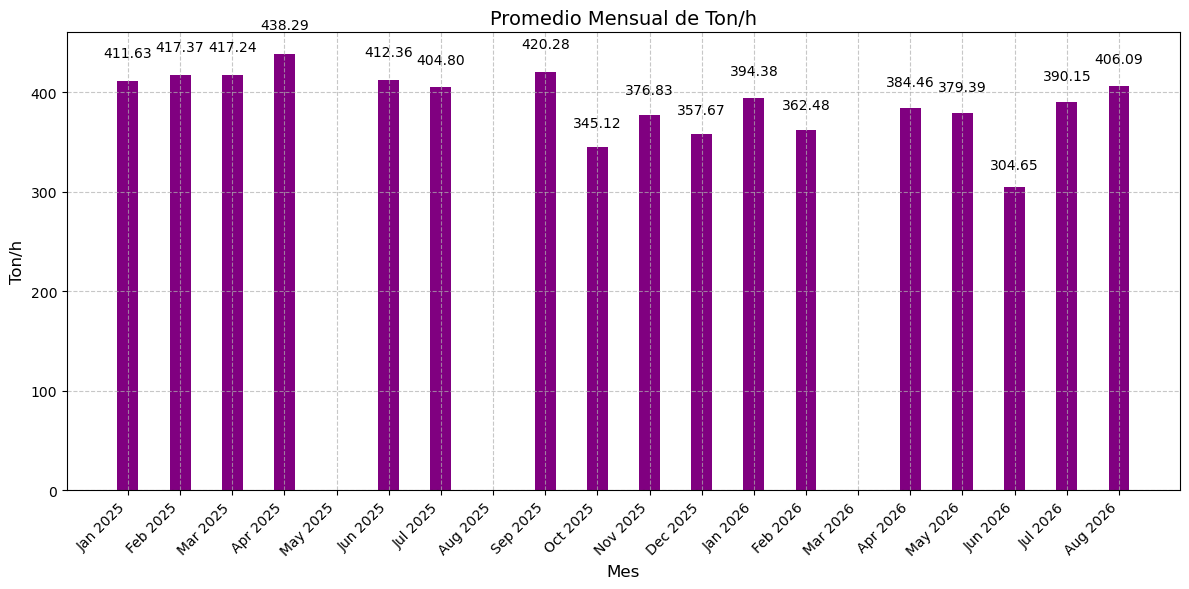


=== Promedios por períodos: Febrero-Mayo 2024 vs Febrero-Mayo 2025 ===

Contenido de promedios_periodos:
                         Ene-Dic 2025  Ene-Dic 2026  Diferencia (2026 - 2025)
kWh_Ton_Motor Principal      9.145081     10.381015                 -1.235934
kWh_Ton_VTI                 10.293444     11.780876                 -1.487432
kWh_Ton_Separador            0.146830      0.178053                 -0.031222
kWh_Ton_Total               19.585356     22.339944                 -2.754588
Ton_h_Promedio             400.159863    374.515440                 25.644424

Promedio de kWh_Ton_Motor Principal por período:
                         Ene-Dic 2025  Ene-Dic 2026  Diferencia (2026 - 2025)
kWh_Ton_Motor Principal      9.145081     10.381015                 -1.235934

Promedio de kWh_Ton_VTI por período:
             Ene-Dic 2025  Ene-Dic 2026  Diferencia (2026 - 2025)
kWh_Ton_VTI     10.293444     11.780876                 -1.487432

Promedio de kWh_Ton_Separador por período:
      

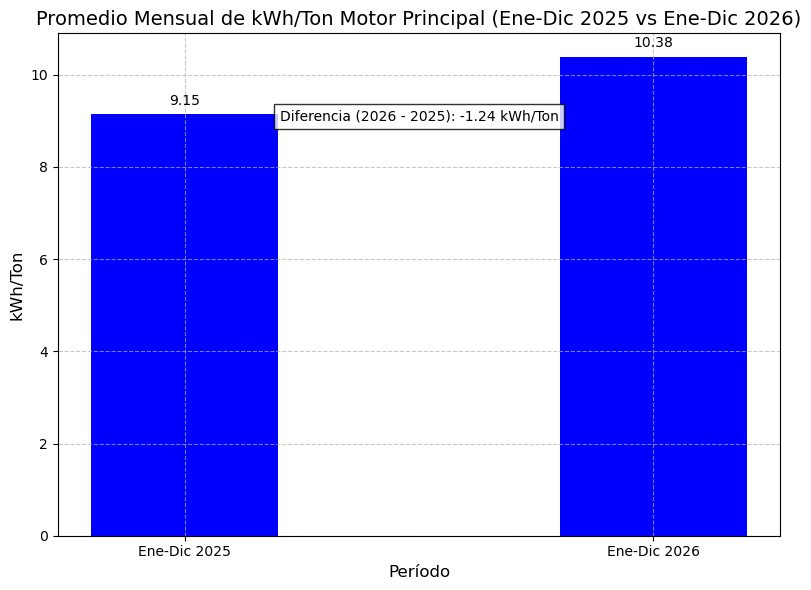

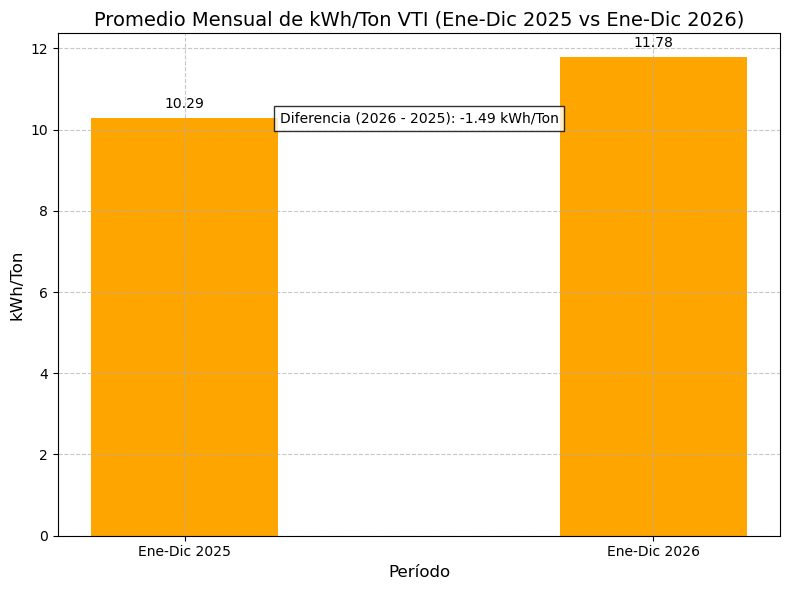

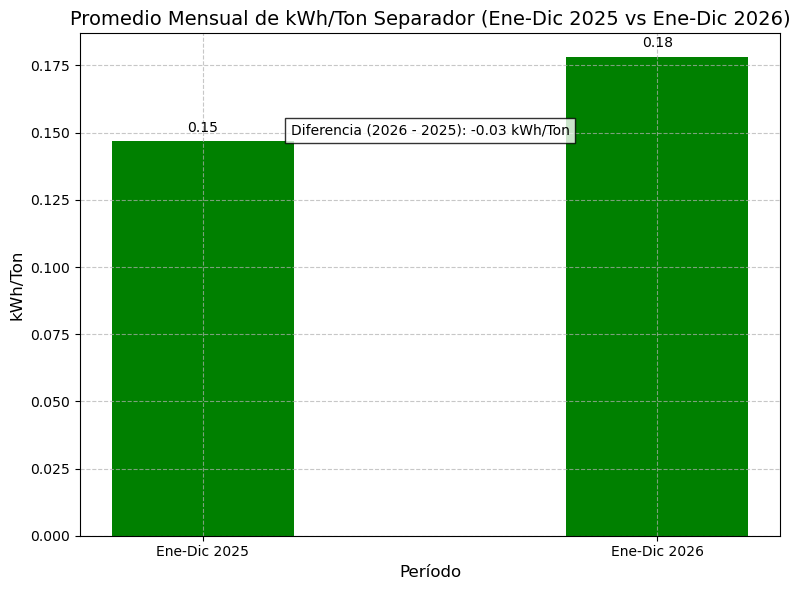

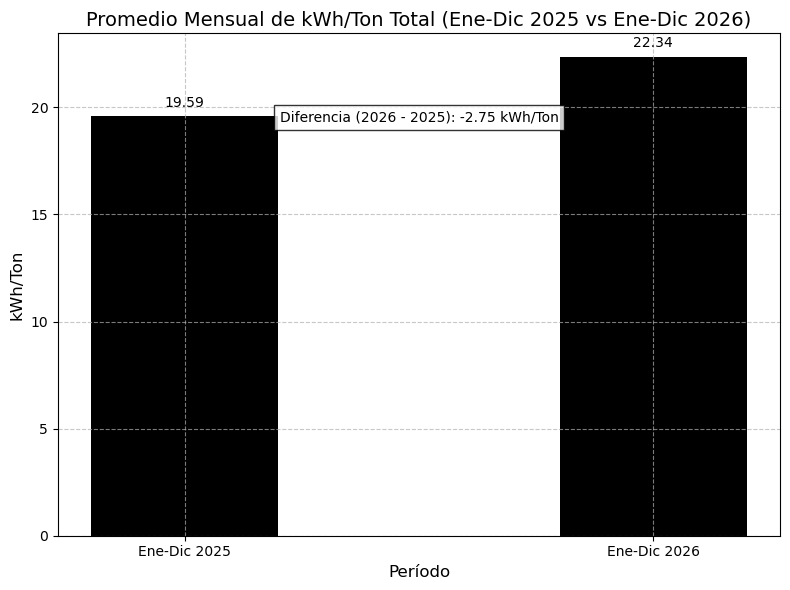

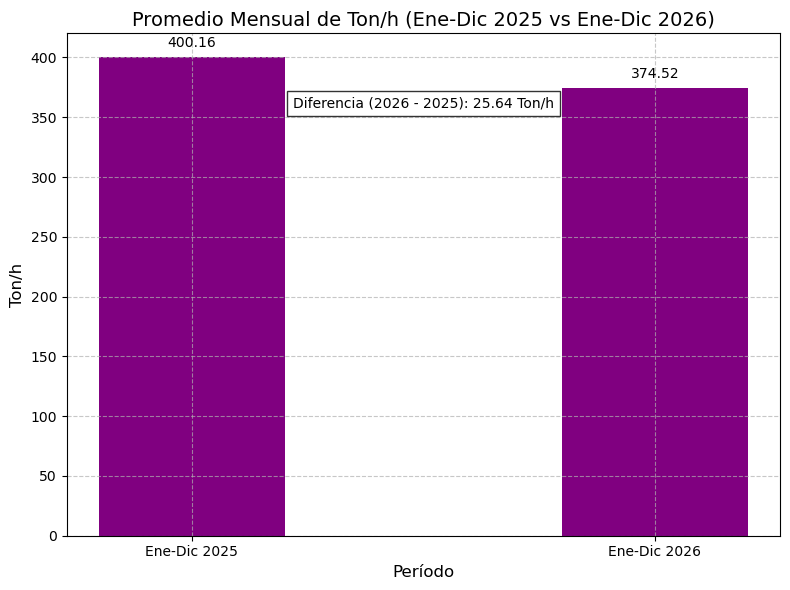


Contribuciones promedio de cada tag al kWh_Ton_Total:
kWh_Ton_Motor Principal: 9.76 kWh/Ton
kWh_Ton_VTI: 11.04 kWh/Ton
kWh_Ton_Separador: 0.16 kWh/Ton


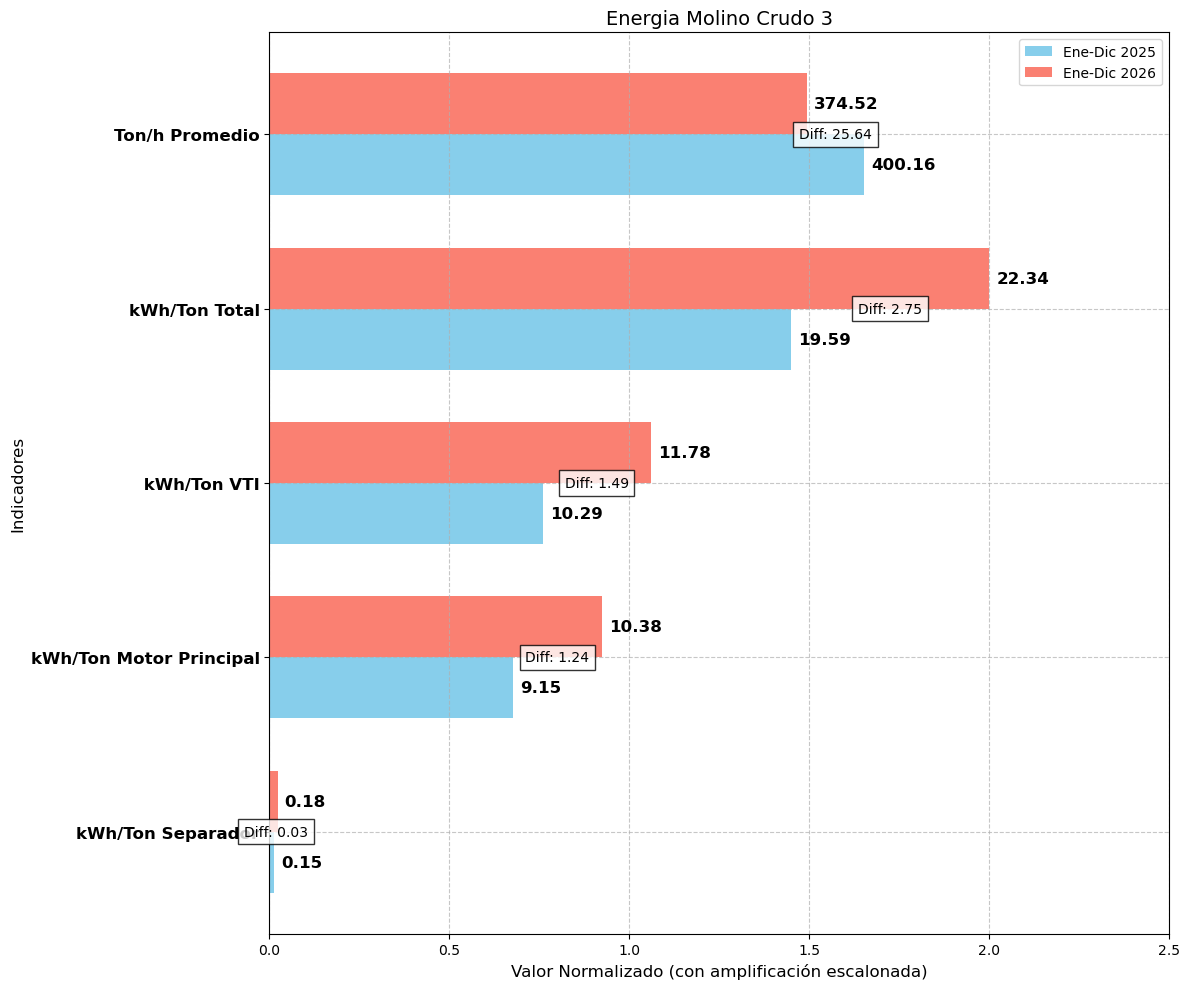

Guardado: Tepeaca_RM03_promedios_mensuales.xlsx
Guardado: Tepeaca_RM03_promedios_periodos.xlsx


In [38]:
# Paso 1: Definir los tags operativos
list_tags = {
    'Tags': [
        'FI_411163.TPC',    # Alimentación (Ton/h)
        'JI_422023.TPC',    # kW Motor Principal
        'JI_422083.TPC',    # Amperaje VTI
        'JI_422043.TPC'    # Amperaje Separador
       
    ]
}

tags = pd.DataFrame(list_tags)
tags = tags.Tags
frequency_op = '2m'

# Paso 2: Extraer datos del PI System
operative_data = pd.DataFrame(columns=['Time'])
for n, tag in enumerate(tags):
    try:
        data = get_interpolated_values('2025-01-01 00:00:00', '2026-08-10 23:59:59', frequency_op, tag)
        print(f"Datos cargados para {tag}: {len(data)} filas, Tipo de data: {type(data)}")
        operative_data = PI_to_dataframe(data, operative_data, tag, n)
        if operative_data.empty or operative_data[tag].isna().all():
            print(f"Advertencia: No se cargaron datos válidos para {tag}")
    except Exception as e:
        print(f"Error al cargar datos para {tag}: {e}")
        operative_data[tag] = np.nan

# Verificar que los datos se cargaron
if operative_data is None or operative_data.empty or operative_data[tags].isna().all().all():
    print("Error: No se cargaron datos operativos.")
    exit()

# Diagnóstico
print("\nFilas en operative_data:", len(operative_data))
print("\nPrimeras filas de operative_data:")
print(operative_data.head())
print("\nValores nulos en operative_data:")
print(operative_data.isna().sum())

# Paso 3: Convertir amperajes a kW
operative_data['kW_Motor_Principal'] = operative_data['JI_422023.TPC'] # Ya existe en kW
operative_data['kW_VTI'] = operative_data['JI_422083.TPC'] 
operative_data['kW_Separador'] = operative_data['JI_422043.TPC'] 

# Diagnóstico
print("\nEstadísticas de tags operativos en kW:")
print(operative_data[['kW_Motor_Principal', 'kW_VTI', 'kW_Separador']].describe())

# Paso 4: Procesar datos
operative_data['Time'] = pd.to_datetime(operative_data['Time'], format='%m/%d/%Y %I:%M:%S %p', errors='coerce')
if operative_data['Time'].isna().any():
    print(f"Advertencia: Algunas fechas no se pudieron convertir a datetime")
    print(f"Fechas problemáticas: {operative_data[operative_data['Time'].isna()]['Time']}")
operative_data = operative_data.set_index('Time')

# Paso 5: Calcular kWh/Ton por equipo
equipos = ['Motor Principal', 'VTI','Separador']
tags_kw = ['kW_Motor_Principal', 'kW_VTI', 'kW_Separador']
tag_tonh = 'FI_411163.TPC'

for eq, tag_kw in zip(equipos, tags_kw):
    operative_data[f'kWh_Ton_{eq}'] = operative_data[tag_kw] / operative_data[tag_tonh]

# Filtrar kW > 10 y Ton_h > 0, con kW_Motor_Principal > 200
filtro = (
    (operative_data['kW_Motor_Principal'] > 3000) &
    (operative_data['kW_VTI'] > 10) &
    (operative_data['kW_Separador'] > 10) &
    (operative_data['FI_411163.TPC'] > 10) 
)
print("\nFilas antes del filtro:", len(operative_data))
operative_data = operative_data[filtro]
print("Filas después del filtro:", len(operative_data))

# Diagnóstico después del filtro
print("\nValores nulos después del filtro:")
print(operative_data.isna().sum())
operative_data['Mes'] = operative_data.index.strftime('%Y-%m')
print("\nConteo de datos por mes (después de filtro):")
print(operative_data.groupby('Mes').size())

# Paso 6: Calcular promedios mensuales
meses = pd.date_range(start="2025-01-01", end="2026-08-10", freq="MS").strftime("%Y-%m").tolist()
meses_nombres = pd.date_range(start="2025-01-01", end="2026-08-10", freq="MS").strftime("%b %Y").tolist()

promedios_mensuales = pd.DataFrame(index=meses)
for eq in equipos:
    promedios_mensuales[f'kWh_Ton_{eq}'] = operative_data.groupby('Mes')[f'kWh_Ton_{eq}'].mean()
promedios_mensuales['Ton_h_Promedio'] = operative_data.groupby('Mes')[tag_tonh].mean()
promedios_mensuales['kWh_Ton_Total'] = promedios_mensuales[[f'kWh_Ton_{eq}' for eq in equipos]].sum(axis=1)

# Asignar NaN si no hay datos válidos
for mes in meses:
    if mes not in operative_data['Mes'].values:
        for col in promedios_mensuales.columns:
            promedios_mensuales.loc[mes, col] = np.nan

# Paso 7: Imprimir resultados
for eq in equipos:
    print(f"\nPromedios mensuales de kWh/Ton para {eq}:")
    for mes, prom in zip(meses_nombres, promedios_mensuales[f'kWh_Ton_{eq}']):
        print(f"{mes}: {prom:.2f} kWh/Ton" if not np.isnan(prom) else f"{mes}: NaN")

print("\nkWh/Ton totales por mes (suma de todos los equipos):")
for mes, total in zip(meses_nombres, promedios_mensuales['kWh_Ton_Total']):
    print(f"{mes}: {total:.2f} kWh/Ton" if not np.isnan(total) else f"{mes}: NaN")

print("\nPromedio mensual de Ton/h:")
for mes, total in zip(meses_nombres, promedios_mensuales['Ton_h_Promedio']):
    print(f"{mes}: {total:.2f} Ton/h" if not np.isnan(total) else f"{mes}: NaN")

print("\nNota: Los promedios de kWh/Ton y Ton/h están sujetos a kW_Motor_Principal > 2000, "
      "kW_VTI > 10, kW_Separador > 10 , FIC_612051_SP.CPN")

# Paso 8: Generar gráficas de barras separadas
metricas = [
    ('kWh_Ton_Motor Principal', 'Promedio Mensual de kWh/Ton Motor Principal', 'kWh/Ton', 'blue'),
    ('kWh_Ton_VTI', 'Promedio Mensual de kWh/Ton VTI', 'kWh/Ton', 'orange'),
    ('kWh_Ton_Separador', 'Promedio Mensual de kWh/Ton Separador', 'kWh/Ton', 'green'),
    ('kWh_Ton_Total', 'Promedio Mensual de kWh/Ton Total', 'kWh/Ton', 'black'),
    ('Ton_h_Promedio', 'Promedio Mensual de Ton/h', 'Ton/h', 'purple')
]

for col, title, ylabel, color in metricas:
    plt.figure(figsize=(12, 6))
    x = np.arange(len(meses_nombres))
    values = promedios_mensuales[col].fillna(0)
    
    bars = plt.bar(x, values, color=color, width=0.4)
    
    for bar in bars:
        height = bar.get_height()
        if np.isfinite(height) and height > 0:
            plt.text(bar.get_x() + bar.get_width() / 2, height + 0.05 * height,
                     f'{height:.2f}', ha='center', va='bottom', fontsize=10)
    
    plt.title(title, fontsize=14)
    plt.xlabel('Mes', fontsize=12)
    plt.ylabel(ylabel, fontsize=12)
    plt.xticks(x, meses_nombres, rotation=45, ha='right', fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()


# Paso 9: Calcular y mostrar promedios por períodos (Feb-May 2024 y Feb-May 2025)
print("\n=== Promedios por períodos: Febrero-Mayo 2024 vs Febrero-Mayo 2025 ===")

# Definir los períodos
periodo_2024 = ['2025-01', '2025-02', '2025-03', '2025-04','2025-05', '2025-06', '2025-07', '2025-08', '2025-09', '2025-10', '2025-11','2025-12']
periodo_2025 = ['2026-01', '2026-02', '2026-03', '2026-04','2026-05', '2026-06', '2026-07', '2026-08', '2026-09', '2026-10', '2026-11','2026-12']

# Crear un DataFrame para almacenar los promedios por período
promedios_periodos = pd.DataFrame(index=[col for col, _, _, _ in metricas])

# Calcular promedios para cada período
promedios_periodos['Ene-Dic 2025'] = promedios_mensuales.loc[periodo_2024, [col for col, _, _, _ in metricas]].mean()
promedios_periodos['Ene-Dic 2026'] = promedios_mensuales.loc[promedios_mensuales.index.intersection(periodo_2025), [col for col, _, _, _ in metricas]].mean()

# Calcular la diferencia (2025 - 2024)
promedios_periodos['Diferencia (2026 - 2025)'] = promedios_periodos['Ene-Dic 2025'] - promedios_periodos['Ene-Dic 2026']

# Diagnóstico: Imprimir promedios_periodos
print("\nContenido de promedios_periodos:")
print(promedios_periodos)

# Imprimir tablas para cada métrica, incluyendo la diferencia
for col in promedios_periodos.index:
    print(f"\nPromedio de {col} por período:")
    print(promedios_periodos.loc[[col], ['Ene-Dic 2025', 'Ene-Dic 2026', 'Diferencia (2026 - 2025)']].to_string(index=True))

# Generar gráficas de barras para cada métrica (por períodos)
for col, title, ylabel, color in metricas:
    plt.figure(figsize=(8, 6))
    x = np.array([0, 1])
    values = promedios_periodos.loc[col, ['Ene-Dic 2025', 'Ene-Dic 2026']].fillna(0).values
    
    bars = plt.bar(x, values, color=color, width=0.4)
    
    for bar in bars:
        height = bar.get_height()
        if height != 0:
            plt.text(bar.get_x() + bar.get_width() / 2, height + 0.015 * height,
                     f'{height:.2f}', ha='center', va='bottom', fontsize=10)
    
    # Añadir anotación con la diferencia en medio de las dos barras, más abajo
    diferencia = promedios_periodos.loc[col, 'Diferencia (2026 - 2025)']
    if not pd.isna(diferencia):
        # Colocar el texto en x=0.5 (entre las barras) y y=promedio de las alturas - 5% para bajarlo
        y_pos = (values[0] + values[1]) / 2 - max(values) * 0.05
        plt.text(0.5, y_pos, f'Diferencia (2026 - 2025): {diferencia:.2f} {ylabel}',
                 ha='center', va='top', fontsize=10, bbox=dict(facecolor='white', alpha=0.8, edgecolor='black'))
    
    plt.title(f'{title} (Ene-Dic 2025 vs Ene-Dic 2026)', fontsize=14)
    plt.xlabel('Período', fontsize=12)
    plt.ylabel(ylabel, fontsize=12)
    plt.xticks(x, ['Ene-Dic 2025', 'Ene-Dic 2026'], fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()



# Paso 10: Generar gráfica comparativa horizontal de todos los indicadores para ambos períodos
# Calcular la contribución promedio de cada equipo al kWh_Ton_Total (promedio entre 2024 y 2025)
kw_tags = [
    ('kWh_Ton_Motor Principal', 'kWh/Ton Motor Principal', 'kWh/Ton', 'blue'),
    ('kWh_Ton_VTI', ' kWh/Ton VTI', 'kWh/Ton', 'orange'),
    ('kWh_Ton_Separador', 'kWh/Ton Separador', 'kWh/Ton', 'green'),
]

# Calcular el promedio de contribución de cada tag al total
contribuciones = {}
for tag, label, unit, color in kw_tags:
    avg_2024 = promedios_periodos.loc[tag, 'Ene-Dic 2025']
    avg_2025 = promedios_periodos.loc[tag, 'Ene-Dic 2026']
    avg_value = np.nanmean([avg_2024, avg_2025])  # Promedio entre los dos períodos
    contribuciones[tag] = avg_value

# Imprimir las contribuciones para diagnóstico
print("\nContribuciones promedio de cada tag al kWh_Ton_Total:")
for tag, contrib in contribuciones.items():
    print(f"{tag}: {contrib:.2f} kWh/Ton")

# Ordenar los tags de kWh/Ton por contribución (de mayor a menor)
sorted_kw_tags = sorted(contribuciones.items(), key=lambda x: x[1], reverse=True)
sorted_tags = [x[0] for x in sorted_kw_tags]

# Reorganizar kw_tags según el orden de sorted_tags
sorted_kw_tags_full = []
for tag in sorted_tags:
    for kw_tag in kw_tags:
        if kw_tag[0] == tag:
            sorted_kw_tags_full.append(kw_tag)
            break

# Definir sorted_indicadores en el orden original (para la normalización)
sorted_indicadores = [
    ('Ton_h_Promedio', 'Ton/h Promedio', 'Ton/h', 'purple'),
    ('kWh_Ton_Total', 'kWh/Ton Total', 'kWh/Ton', 'black')
] + sorted_kw_tags_full

# Preparar datos para normalización (usando el orden original)
normalized_data = promedios_periodos.loc[[ind[0] for ind in sorted_indicadores], ['Ene-Dic 2025', 'Ene-Dic 2026']].copy()
normalized_data_np = normalized_data.fillna(0).to_numpy()

# Normalización inicial: kWh_Ton_Total y Ton_h_Promedio con tamaño base uniforme
scaled_data = normalized_data_np.copy()
for i in range(2):  # kWh_Ton_Total y Ton_h_Promedio
    max_val = max(normalized_data_np[i, 0], normalized_data_np[i, 1])
    if max_val > 0:
        scaled_data[i, :] = normalized_data_np[i, :] / max_val  # Escalar al rango [0, 1]

# Normalización proporcional para los tags de kWh/Ton
min_scale = 0.01  # Reducido para permitir mayor diferencia visual
elevator_reduction = 0.65  # Factor de reducción para el Elevador
for i in range(2, len(sorted_indicadores)):  # Solo los tags de kWh/Ton
    tag = sorted_indicadores[i][0]
    avg_contrib = contribuciones.get(tag, 0)  # Usar .get() para manejar casos donde tag no esté en contribuciones
    total_avg = np.nanmean([promedios_periodos.loc['kWh_Ton_Total', 'Ene-Dic 2025'],
                           promedios_periodos.loc['kWh_Ton_Total', 'Ene-Dic 2026']])
    if total_avg > 0:
        proportion = avg_contrib / total_avg  # Proporción respecto al total
        # Asegurar que los valores pequeños sean visibles
        proportion = max(proportion, min_scale)
        # Reducir el tamaño del Elevador
        if "Elevador" in tag:
            proportion *= elevator_reduction
        # Escalar los valores originales según la proporción
        scaled_data[i, :] = normalized_data_np[i, :] / max(normalized_data_np[i, 0], normalized_data_np[i, 1]) * proportion
    else:
        scaled_data[i, :] = 0

# Definir umbrales y factores de amplificación basados en diferencias relativas (%)
large_diff_threshold = 0.10  # 10% de diferencia relativa
medium_diff_threshold = 0.02  # 2% de diferencia relativa
large_amplification = 2  # Factor base para diferencias grandes (≥10%)
medium_amplification = 1.5  # Factor para diferencias intermedias (2% a 10%)
small_amplification = 1.05  # Factor para diferencias pequeñas (<2%)

# Aplicar amplificación escalonada basada en la diferencia relativa
adjusted_data = scaled_data.copy()
for i in range(normalized_data_np.shape[0]):
    val_2024 = normalized_data_np[i, 0]
    val_2025 = normalized_data_np[i, 1]
    if val_2024 == 0 or val_2025 == 0:
        continue
    # Calcular diferencia relativa: | (2025 - 2024) / 2024 |
    rel_diff = abs((val_2025 - val_2024) / val_2024) if val_2024 != 0 else 0
    
    if rel_diff >= large_diff_threshold:
        # Amplificación para diferencias grandes (≥10%)
        dynamic_amplification = large_amplification + (rel_diff * 5)  # Escala con la diferencia relativa
        adjusted_data[i, 0] = scaled_data[i, 0]
        adjusted_data[i, 1] = scaled_data[i, 1] + (scaled_data[i, 1] - scaled_data[i, 0]) * (dynamic_amplification - 1)
    elif rel_diff >= medium_diff_threshold:
        # Amplificar diferencias intermedias (2% a 10%)
        adjusted_data[i, 0] = scaled_data[i, 0]
        adjusted_data[i, 1] = scaled_data[i, 1] + (scaled_data[i, 1] - scaled_data[i, 0]) * (medium_amplification - 1)
    else:
        # Amplificar mínimamente diferencias pequeñas (<2%)
        adjusted_data[i, 0] = scaled_data[i, 0]
        adjusted_data[i, 1] = scaled_data[i, 1] + (scaled_data[i, 1] - scaled_data[i, 0]) * (small_amplification - 1)

# Convertir de vuelta a DataFrame
normalized_data = pd.DataFrame(adjusted_data, index=normalized_data.index, columns=normalized_data.columns)

# Normalización final: ajustar escala para barras más largas
global_max = normalized_data.max().max()
normalized_data = normalized_data / (global_max * 0.5)  # Reducir divisor para barras más largas
normalized_data = normalized_data.fillna(0)

# Invertir el orden para la visualización (TPH, Total, luego tags ordenados)
display_order = sorted_indicadores[::-1]
display_labels = [label for _, label, _, _ in display_order]
display_indices = [sorted_indicadores.index(ind) for ind in display_order]

# Reorganizar los datos según el orden de visualización
normalized_data_display = normalized_data.iloc[display_indices]

# Generar gráfica de barras horizontales
plt.figure(figsize=(12, 10))  # Ajustar tamaño para 6 indicadores
n_indicadores = len(sorted_indicadores)
y = np.arange(n_indicadores)
height = 0.35

bars1 = plt.barh(y - height/2, normalized_data_display['Ene-Dic 2025'], height, label='Ene-Dic 2025', color='skyblue')
bars2 = plt.barh(y + height/2, normalized_data_display['Ene-Dic 2026'], height, label='Ene-Dic 2026', color='salmon')

# Añadir etiquetas con los valores reales
for bars, period in [(bars1, 'Ene-Dic 2025'), (bars2, 'Ene-Dic 2026')]:
    for i, bar in enumerate(bars):
        width = bar.get_width()
        if width > 0:
            real_value = promedios_periodos.loc[display_order[i][0], period]
            if not pd.isna(real_value):
                plt.text(width + 0.02, bar.get_y() + bar.get_height()/2,
                         f'{real_value:.2f}', ha='left', va='center', fontsize=12, fontweight='bold')

# Añadir anotaciones de diferencias absolutas
for i, (col, _, _, _) in enumerate(display_order):
    val_2024 = promedios_periodos.loc[col, 'Ene-Dic 2025']
    val_2025 = promedios_periodos.loc[col, 'Ene-Dic 2026']
    abs_diff = abs(val_2025 - val_2024) if not (pd.isna(val_2024) or pd.isna(val_2025)) else 0
    if abs_diff > 0:
        y_pos = y[i]
        x_pos = (normalized_data_display.loc[col, 'Ene-Dic 2025'] + normalized_data_display.loc[col, 'Ene-Dic 2026']) / 2
        plt.text(x_pos, y_pos, f'Diff: {abs_diff:.2f}', ha='center', va='center', fontsize=10, 
                 bbox=dict(facecolor='white', alpha=0.8, edgecolor='black'))

# Configuración de la gráfica
plt.title('Energia Molino Crudo 3', fontsize=14)
plt.xlabel('Valor Normalizado (con amplificación escalonada)', fontsize=12)
plt.ylabel('Indicadores', fontsize=12)
plt.yticks(y, display_labels, fontsize=12, fontweight='bold')
plt.xlim(0, 2.5)  # Aumentar límite para barras más largas
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()





# Guardar tablas importantes automáticamente al final
import os

# Lista de DataFrames que quieres guardar (agrega los que tengas)
tablas_a_guardar = {
    'promedios_mensuales': promedios_mensuales if 'promedios_mensuales' in globals() else None,
    'promedios_periodos': promedios_periodos if 'promedios_periodos' in globals() else None,
    # Agrega más si tienes, ej: 'clinker_df': clinker_df
}

nombre_base = 'Tepeaca_RM03'  # o pon el nombre manual: 'Atotonilco', 'Zapotiltic', etc.

for nombre, df in tablas_a_guardar.items():
    if df is not None and isinstance(df, pd.DataFrame):
        archivo = f"{nombre_base}_{nombre}.xlsx"
        df.to_excel(archivo, index=True)
        print(f"Guardado: {archivo}")




Datos cargados para MX-TEP-S03-411001-DNA-40003-03-HOR-M00-QM: 2906 filas, Tipo de data: <class 'OSIsoft.AF.Asset.AFValues'>

Estadísticas para MX-TEP-S03-411001-DNA-40003-03-HOR-M00-QM:
count    2906.000000
mean       79.875478
std         1.575397
min        71.320000
25%        78.860001
50%        79.959999
75%        80.910004
max        86.040001
Name: MX-TEP-S03-411001-DNA-40003-03-HOR-M00-QM, dtype: float64
Valores nulos para MX-TEP-S03-411001-DNA-40003-03-HOR-M00-QM: 0

Conteo de datos por mes para MX-TEP-S03-411001-DNA-40003-03-HOR-M00-QM:
Mes
2025-01    356
2025-02    227
2025-03    130
2025-04    219
2025-06    198
2025-07    189
2025-09    211
2025-10     11
2025-11    237
2025-12     98
2026-01    253
2026-02    101
2026-04    178
2026-05    191
2026-06     24
2026-07    213
2026-08     70
dtype: int64

Tabla de promedios mensuales:
         MX-TEP-S03-411001-DNA-40003-03-HOR-M00-QM
2025-01                                  80.013427
2025-02                                

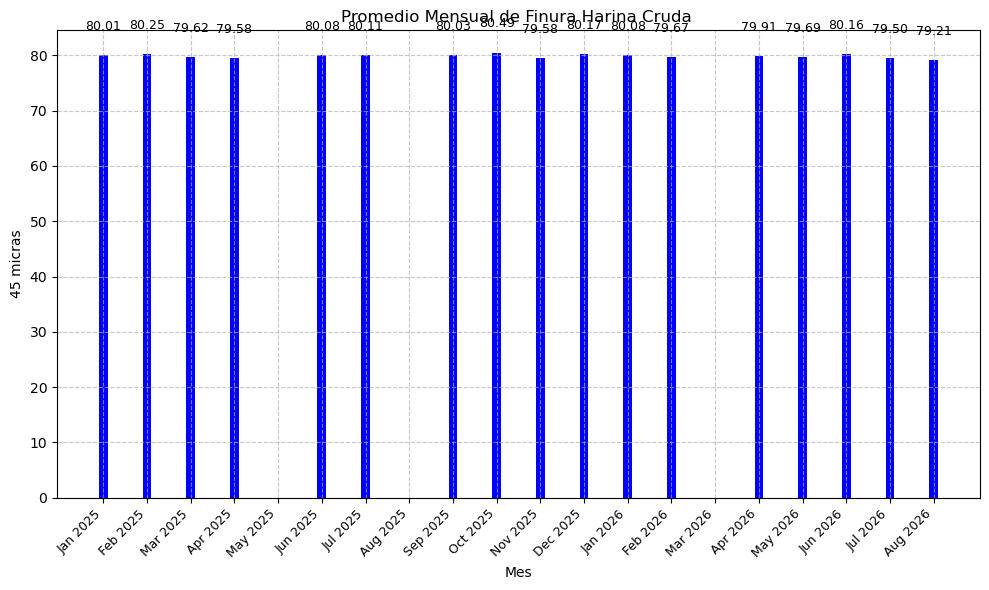


=== Promedios por períodos: Febrero-Mayo 2024 vs Febrero-Mayo 2025 ===

Contenido de promedios_periodos:
                                           Ene-Dic 2025  Ene-Dic 2026  \
MX-TEP-S03-411001-DNA-40003-03-HOR-M00-QM     79.991993     79.745743   

                                           Diferencia (2026 - 2025)  
MX-TEP-S03-411001-DNA-40003-03-HOR-M00-QM                  0.246249  

Promedio de MX-TEP-S03-411001-DNA-40003-03-HOR-M00-QM por período:
                                           Ene-Dic 2025  Ene-Dic 2026  Diferencia (2026 - 2025)
MX-TEP-S03-411001-DNA-40003-03-HOR-M00-QM     79.991993     79.745743                  0.246249


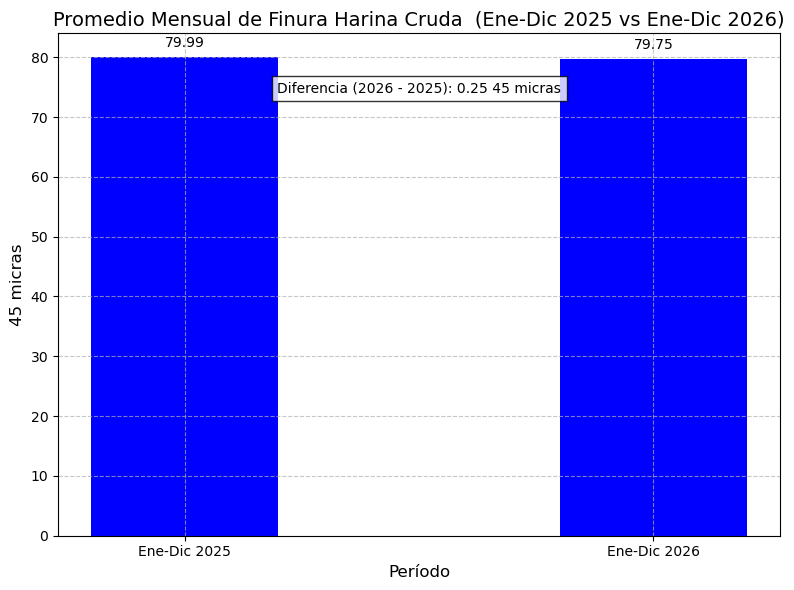

Guardado: Tepeaca_calidad_RM03_promedios_mensuales.xlsx
Guardado: Tepeaca_calidad_RM03_promedios_periodos.xlsx


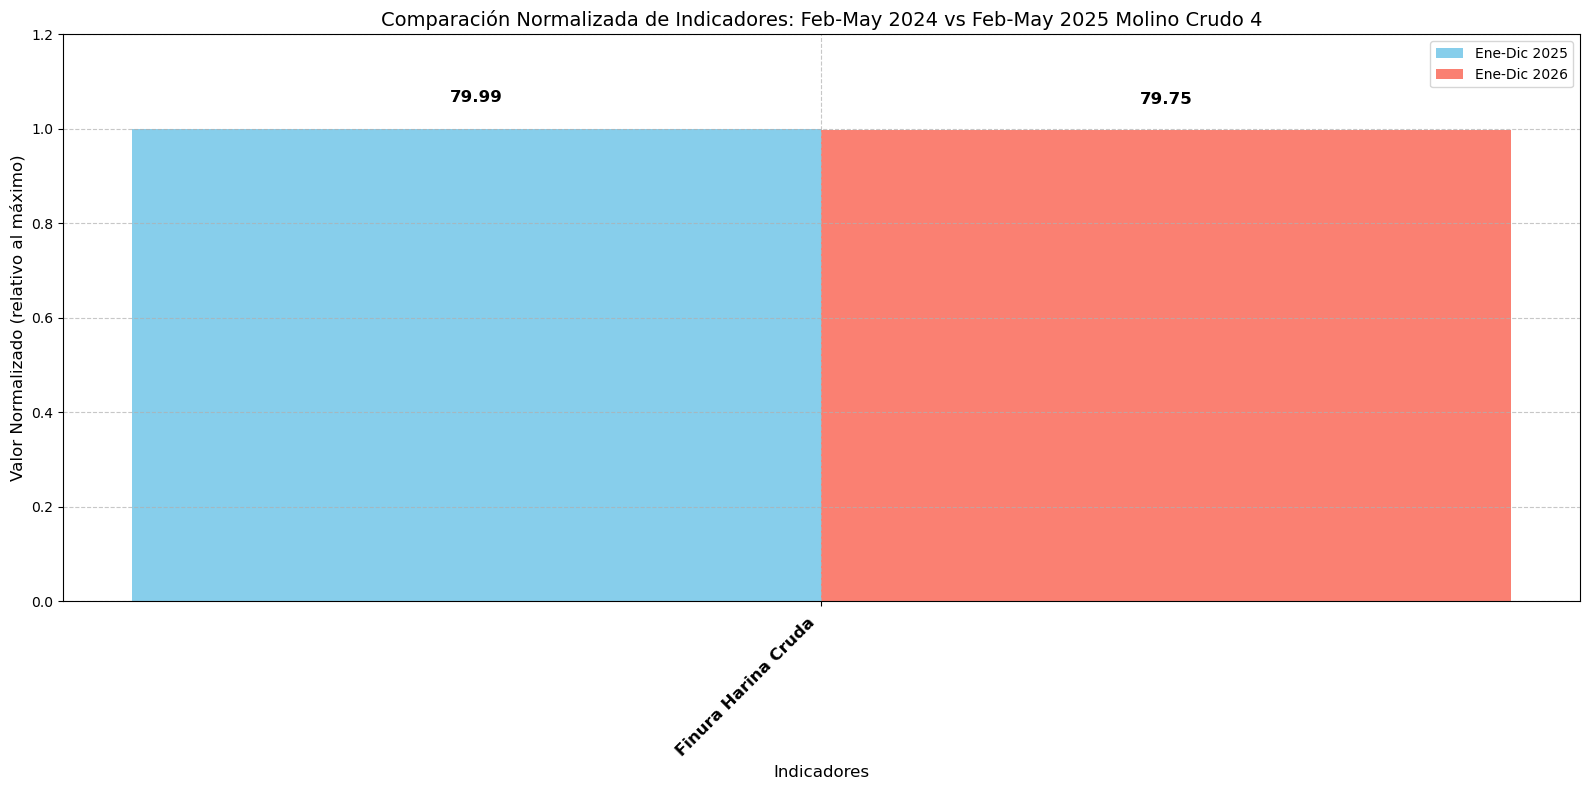

In [39]:
# Paso 1: Definir los tags de Finura y Blaine
list_tags = [
    'MX-TEP-S03-411001-DNA-40003-03-HOR-M00-QM',  # Finura Harina Cruda
]


# Paso 2: Extraer datos y calcular promedios mensuales
meses = pd.date_range(start="2025-01-01", end="2026-08-10", freq="MS").strftime("%Y-%m").tolist()
meses_nombres = pd.date_range(start="2025-01-01", end="2026-08-10", freq="MS").strftime("%b %Y").tolist()
promedios_mensuales = pd.DataFrame(index=meses)

for tag in list_tags:
    try:
        # Obtener datos
        data = get_recorded_values('2025-01-01 00:00:00', '2026-08-10 23:59:59', tag)
        print(f"Datos cargados para {tag}: {len(data)} filas, Tipo de data: {type(data)}")
        
        # Crear DataFrame para el tag
        tag_data = pd.DataFrame()
        tag_data = PI_to_dataframe(data, tag_data, tag, 0)
        
        if tag_data.empty or tag_data[tag].isna().all():
            print(f"Advertencia: No se cargaron datos válidos para {tag}")
            promedios_mensuales[tag] = np.nan
            continue
        
        # Convertir Time a datetime
        tag_data['Time'] = pd.to_datetime(tag_data['Time'], format='%m/%d/%Y %I:%M:%S %p', errors='coerce')
        if tag_data['Time'].isna().any():
            print(f"Advertencia: Algunas fechas no se pudieron convertir a datetime para {tag}")
            print(f"Fechas problemáticas: {tag_data[tag_data['Time'].isna()]['Time']}")
        
        # Establecer Time como índice
        tag_data = tag_data.set_index('Time')
        
        # Diagnóstico
        print(f"\nEstadísticas para {tag}:")
        print(tag_data[tag].describe())
        print(f"Valores nulos para {tag}: {tag_data[tag].isna().sum()}")
        
        # Calcular promedios mensuales
        tag_data['Mes'] = tag_data.index.strftime('%Y-%m')
        promedios_mensuales[tag] = tag_data.groupby('Mes')[tag].mean()
        
        # Conteo de datos por mes
        print(f"\nConteo de datos por mes para {tag}:")
        print(tag_data.groupby('Mes').size())
        
    except Exception as e:
        print(f"Error al procesar {tag}: {e}")
        promedios_mensuales[tag] = np.nan

# Asignar NaN a meses sin datos
for tag in list_tags:
    for mes in meses:
        if mes not in promedios_mensuales.index or pd.isna(promedios_mensuales.loc[mes, tag]):
            promedios_mensuales.loc[mes, tag] = np.nan

# Diagnóstico final
print("\nTabla de promedios mensuales:")
print(promedios_mensuales)

# Paso 3: Imprimir resultados
for tag in list_tags:
    unit = '% pasando' if 'S01' in tag else 'cm²/g'
    print(f"\nPromedios mensuales para {tag} ({unit}):")
    for mes, prom in zip(meses_nombres, promedios_mensuales[tag]):
        print(f"{mes}: {prom:.2f} {unit}" if not np.isnan(prom) else f"{mes}: NaN")

# Paso 4: Generar gráficas de barras
metricas = [
    ('MX-TEP-S03-411001-DNA-40003-03-HOR-M00-QM', 'Promedio Mensual de Finura Harina Cruda ', '45 micras', 'blue'),
  
]

for col, title, ylabel, color in metricas:
    plt.figure(figsize=(10, 6))
    x = np.arange(len(meses_nombres))
    values = promedios_mensuales[col].fillna(0)
    
    bars = plt.bar(x, values, color=color, width=0.2)
    
    for bar in bars:
        height = bar.get_height()
        if height != 0:
            plt.text(bar.get_x() + bar.get_width() / 2, height + 0.05 * height,
                     f'{height:.2f}', ha='center', va='bottom', fontsize=9)
    
    plt.title(title, fontsize=12)
    plt.xlabel('Mes', fontsize=10)
    plt.ylabel(ylabel, fontsize=10)
    plt.xticks(x, meses_nombres, rotation=45, ha='right', fontsize=9)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

# Paso 9: Calcular y mostrar promedios por períodos (Feb-May 2024 y Feb-May 2025)
print("\n=== Promedios por períodos: Febrero-Mayo 2024 vs Febrero-Mayo 2025 ===")

# Definir los períodos
periodo_2024 = ['2025-01', '2025-02', '2025-03', '2025-04','2025-05', '2025-06', '2025-07', '2025-08', '2025-09', '2025-10', '2025-11','2025-12']
periodo_2025 = ['2026-01', '2026-02', '2026-03', '2026-04','2026-05', '2026-06', '2026-07', '2026-08', '2026-09', '2026-10', '2026-11','2026-12']

# Crear un DataFrame para almacenar los promedios por período
promedios_periodos = pd.DataFrame(index=[col for col, _, _, _ in metricas])

# Calcular promedios para cada período
promedios_periodos['Ene-Dic 2025'] = promedios_mensuales.loc[periodo_2024, [col for col, _, _, _ in metricas]].mean()
promedios_periodos['Ene-Dic 2026'] = promedios_mensuales.loc[promedios_mensuales.index.intersection(periodo_2025), [col for col, _, _, _ in metricas]].mean()

# Calcular la diferencia (2025 - 2024)
promedios_periodos['Diferencia (2026 - 2025)'] = promedios_periodos['Ene-Dic 2025'] - promedios_periodos['Ene-Dic 2026']

# Diagnóstico: Imprimir promedios_periodos
print("\nContenido de promedios_periodos:")
print(promedios_periodos)

# Imprimir tablas para cada métrica, incluyendo la diferencia
for col in promedios_periodos.index:
    print(f"\nPromedio de {col} por período:")
    print(promedios_periodos.loc[[col], ['Ene-Dic 2025', 'Ene-Dic 2026', 'Diferencia (2026 - 2025)']].to_string(index=True))

# Generar gráficas de barras para cada métrica (por períodos)
for col, title, ylabel, color in metricas:
    plt.figure(figsize=(8, 6))
    x = np.array([0, 1])
    values = promedios_periodos.loc[col, ['Ene-Dic 2025', 'Ene-Dic 2026']].fillna(0).values
    
    bars = plt.bar(x, values, color=color, width=0.4)
    
    for bar in bars:
        height = bar.get_height()
        if height != 0:
            plt.text(bar.get_x() + bar.get_width() / 2, height + 0.015 * height,
                     f'{height:.2f}', ha='center', va='bottom', fontsize=10)
    
    # Añadir anotación con la diferencia en medio de las dos barras, más abajo
    diferencia = promedios_periodos.loc[col, 'Diferencia (2026 - 2025)']
    if not pd.isna(diferencia):
        # Colocar el texto en x=0.5 (entre las barras) y y=promedio de las alturas - 5% para bajarlo
        y_pos = (values[0] + values[1]) / 2 - max(values) * 0.05
        plt.text(0.5, y_pos, f'Diferencia (2026 - 2025): {diferencia:.2f} {ylabel}',
                 ha='center', va='top', fontsize=10, bbox=dict(facecolor='white', alpha=0.8, edgecolor='black'))
    
    plt.title(f'{title} (Ene-Dic 2025 vs Ene-Dic 2026)', fontsize=14)
    plt.xlabel('Período', fontsize=12)
    plt.ylabel(ylabel, fontsize=12)
    plt.xticks(x, ['Ene-Dic 2025', 'Ene-Dic 2026'], fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

# Paso 10: Generar gráfica comparativa de todos los indicadores para ambos períodos (con normalización)
indicadores = [
 'MX-TEP-S03-411001-DNA-40003-03-HOR-M00-QM',
]

# Normalizar los valores dividiendo por el máximo de cada indicador
normalized_data = promedios_periodos.loc[indicadores, ['Ene-Dic 2025', 'Ene-Dic 2026']].copy()
max_values = normalized_data.max(axis=1)  # Máximo por indicador (entre ambos períodos)
normalized_data = normalized_data.div(max_values, axis=0).fillna(0)  # Normalizar y manejar NaN

plt.figure(figsize=(16, 8))

# Configuración de las barras
n_indicadores = len(indicadores)
x = np.arange(n_indicadores)
width = 0.35

# Crear barras normalizadas
bars1 = plt.bar(x - width/2, normalized_data['Ene-Dic 2025'], width, label='Ene-Dic 2025', color='skyblue')
bars2 = plt.bar(x + width/2, normalized_data['Ene-Dic 2026'], width, label='Ene-Dic 2026', color='salmon')

# Añadir etiquetas con los valores reales (no normalizados)
for bars, period in [(bars1, 'Ene-Dic 2025'), (bars2, 'Ene-Dic 2026')]:
    for i, bar in enumerate(bars):
        height = bar.get_height()
        if height > 0:
            real_value = promedios_periodos.loc[indicadores[i], period]
            if not pd.isna(real_value):
                plt.text(bar.get_x() + bar.get_width()/2, height + 0.05,
                         f'{real_value:.2f}', ha='center', va='bottom', fontsize=12, fontweight='bold')

# Configuración de la gráfica
plt.title('Comparación Normalizada de Indicadores: Feb-May 2024 vs Feb-May 2025 Molino Crudo 4', fontsize=14)
plt.xlabel('Indicadores', fontsize=12)
plt.ylabel('Valor Normalizado (relativo al máximo)', fontsize=12)
plt.xticks(x, [
'Finura Harina Cruda ',
], rotation=45, ha='right', fontsize=12, fontweight='bold' )
plt.ylim(0, 1.2)  # Ajustar el límite superior para dejar espacio a las etiquetas
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show






# Guardar tablas importantes automáticamente al final
import os

# Lista de DataFrames que quieres guardar (agrega los que tengas)
tablas_a_guardar = {
    'promedios_mensuales': promedios_mensuales if 'promedios_mensuales' in globals() else None,
    'promedios_periodos': promedios_periodos if 'promedios_periodos' in globals() else None,
    # Agrega más si tienes, ej: 'clinker_df': clinker_df
}

nombre_base = 'Tepeaca_calidad_RM03'  # o pon el nombre manual: 'Atotonilco', 'Zapotiltic', etc.

for nombre, df in tablas_a_guardar.items():
    if df is not None and isinstance(df, pd.DataFrame):
        archivo = f"{nombre_base}_{nombre}.xlsx"
        df.to_excel(archivo, index=True)
        print(f"Guardado: {archivo}")



In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import joblib

# ============================================================
# Paso 1: Definir los tags
# ============================================================
list_tags = {
    'Tags': [
        # Parámetros Operativos
        'FI_520501.MCO',    # Alimentación
        'SI_530201.MCO',    # VTI Precalentador
        'SI_566701.MCO',    # VTI Enfriador
        'FIC_885401.MCO',   # Flujo de Carbón Quemador
        'FI_884801.MCO',    # Flujo Carbón Calcinador
        'JI_541101.MCO',    # Potencia Motor

        # Gases
        'AI_540501B.MCO',   # %Gases NO
        'AI_540501C.MCO',   # %Gases SO2
        'AI_540501A.MCO',   # %CO
        'AI_540501D.MCO',   # %O2
    ]
}

tags = pd.DataFrame(list_tags).Tags
frequency = '2m'

# ============================================================
# Paso 2: Extraer datos del PI System
# ============================================================
start_time = '2026-01-01 00:00:00'
end_time   = '2026-09-21 23:59:59'

operative_data = pd.DataFrame(columns=['Time'])

for n, tag in enumerate(tags):
    try:
        data = get_interpolated_values(start_time, end_time, frequency, tag)
        print(f"Datos cargados para {tag}: {len(data)} filas")
        operative_data = PI_to_dataframe(data, operative_data, tag, n)
    except Exception as e:
        print(f"Error al cargar {tag}: {e}")
        operative_data[tag] = np.nan

print("\nFilas totales cargadas:", len(operative_data))
print(operative_data.head())

# ============================================================
# Paso 3: Procesar Time y renombrar
# ============================================================
operative_data['Time'] = pd.to_datetime(operative_data['Time'], errors='coerce')
operative_data = operative_data.set_index('Time')

df = operative_data.rename(columns={
    'FI_520501.MCO':  'Alimentacion',
    'SI_530201.MCO':  'VTI_Precalentador',
    'SI_566701.MCO':  'VTI_Enfriador',
    'FIC_885401.MCO': 'Flujo_Carbon_Quemador',
    'FI_884801.MCO':  'Flujo_Carbon_Calcinador',
    'JI_541101.MCO':  'Potencia_Motor',
    'AI_540501B.MCO': 'NO',
    'AI_540501C.MCO': 'SO2',
    'AI_540501A.MCO': 'CO',
    'AI_540501D.MCO': 'O2'
})

# ============================================================
# Paso 4: Filtros operativos básicos
# ============================================================
filtro = (
    (df['Alimentacion'] > 50) &
    (df['Potencia_Motor'] > 100) &
    (df['Flujo_Carbon_Quemador'] > 0) &
    (df['Flujo_Carbon_Calcinador'] > 0) &
    (df['O2'] > 0) & (df['O2'] < 12) &
    (df['NO'] > 0) & (df['NO'] < 1500)
)

df = df[filtro].copy()
print(f"\nFilas después de filtros: {len(df)}")

# ============================================================
# Paso 5: Crear estado previo del horno (lags)
# ============================================================
for col in ['Alimentacion', 'VTI_Precalentador', 'VTI_Enfriador',
            'Flujo_Carbon_Quemador', 'Flujo_Carbon_Calcinador',
            'Potencia_Motor', 'NO', 'SO2', 'CO', 'O2']:
    df[f'{col}_lag1'] = df[col].shift(1)

df = df.dropna()
print(f"Filas después de crear lags: {len(df)}")

# ============================================================
# Paso 6: Separar por PERIODOS (forma robusta - PORCENTAJE)
# ============================================================
df = df.sort_index()

n = len(df)
train_end = int(n * 0.70)      # 70% entrenamiento
val_end   = int(n * 0.85)      # 15% validación

train = df.iloc[:train_end]
val   = df.iloc[train_end:val_end]
test  = df.iloc[val_end:]

print(f"\nRango de fechas del dataset:")
print(f"Desde: {df.index.min()}  →  Hasta: {df.index.max()}")
print(f"\nEntrenamiento: {len(train)} filas")
print(f"Validación:    {len(val)} filas")
print(f"Prueba:        {len(test)} filas")

features = [
    'Alimentacion', 'VTI_Precalentador', 'VTI_Enfriador',
    'Flujo_Carbon_Quemador', 'Flujo_Carbon_Calcinador', 'Potencia_Motor',
    'Alimentacion_lag1', 'VTI_Precalentador_lag1', 'VTI_Enfriador_lag1',
    'Flujo_Carbon_Quemador_lag1', 'Flujo_Carbon_Calcinador_lag1',
    'Potencia_Motor_lag1', 'NO_lag1', 'SO2_lag1', 'CO_lag1', 'O2_lag1'
]

targets = ['NO', 'SO2', 'CO', 'O2']

X_train, y_train = train[features], train[targets]
X_val, y_val     = val[features], val[targets]
X_test, y_test   = test[features], test[targets]

# ============================================================
# Paso 7: Entrenar el modelo (Random Forest)
# ============================================================
print("\n=== Entrenando modelo predictivo (Random Forest) ===")

model = MultiOutputRegressor(
    RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_split=10,
        n_jobs=-1,
        random_state=42
    )
)

model.fit(X_train, y_train)

# Evaluación
y_pred = model.predict(X_test)
print("\nResultados en conjunto de Prueba:")
for i, col in enumerate(targets):
    print(f"{col:5} → R² = {r2_score(y_test.iloc[:,i], y_pred[:,i]):.3f} | MAE = {mean_absolute_error(y_test.iloc[:,i], y_pred[:,i]):.2f}")

# Guardar el modelo
joblib.dump(model, 'modelo_random_forest_emisiones.pkl')
print("\nModelo guardado como: modelo_random_forest_emisiones.pkl")

# ============================================================
# Paso 8: Recomendaciones (Modo Sombra)
# ============================================================
print("\n" + "="*70)
print("=== RECOMENDACIONES (Modo Sombra) ===")
print("="*70)

df_eficiente = train[
    (train['CO'] < 0.5) &
    (train['NO'] < 500) &
    (train['O2'] < 3.0)
].copy()

if not df_eficiente.empty:
    print(f"\nSe encontraron {len(df_eficiente)} registros que cumplen las restricciones.")
    print("\nPara mantener %CO < 0.5, %NO < 500 y %O2 < 3.0,")
    print("se recomienda mantener las variables en los siguientes rangos:\n")

    variables_manipulables = [
        'Alimentacion', 'VTI_Precalentador', 'VTI_Enfriador',
        'Flujo_Carbon_Quemador', 'Flujo_Carbon_Calcinador', 'Potencia_Motor'
    ]

    recomendaciones = []
    for var in variables_manipulables:
        recomendaciones.append({
            "Variable Manipulable": var,
            "Valor Mínimo": round(df_eficiente[var].min(), 2),
            "Valor Máximo": round(df_eficiente[var].max(), 2),
            "Setpoint Sugerido (Promedio)": round(df_eficiente[var].mean(), 2)
        })

    df_setpoints = pd.DataFrame(recomendaciones)
    print(df_setpoints.to_string(index=False))
    print("\n" + "="*70)
    print("Estos valores se entregan en Modo Sombra (solo recomendación al operador).")
else:
    print("Ningún registro cumplió con las 3 restricciones al mismo tiempo.")
    print("Prueba relajar un poco los límites (por ejemplo NO < 600 o O2 < 3.5)")

Datos cargados para FI_520501.MCO: 190080 filas
Datos cargados para SI_530201.MCO: 190080 filas
Datos cargados para SI_566701.MCO: 190080 filas
Datos cargados para FIC_885401.MCO: 190080 filas
Datos cargados para FI_884801.MCO: 190080 filas
Datos cargados para JI_541101.MCO: 190080 filas
Datos cargados para AI_540501B.MCO: 190080 filas
Datos cargados para AI_540501C.MCO: 190080 filas
Datos cargados para AI_540501A.MCO: 190080 filas
Datos cargados para AI_540501D.MCO: 190080 filas

Filas totales cargadas: 190080
                   Time  FI_520501.MCO  SI_530201.MCO  SI_566701.MCO  \
0  1/1/2026 12:00:00 AM       0.212411            0.0       0.465855   
1  1/1/2026 12:02:00 AM       0.220635            0.0       0.476882   
2  1/1/2026 12:04:00 AM       0.215962            0.0       0.492915   
3  1/1/2026 12:06:00 AM       0.194877            0.0       0.508948   
4  1/1/2026 12:08:00 AM       0.216894            0.0       0.524981   

   FIC_885401.MCO  FI_884801.MCO  JI_541101.MCO  A

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score
import joblib

# ============================================================
# Paso 1: Definir los tags
# ============================================================
list_tags = {
    'Tags': [
        # Parámetros Operativos
        'FI_520501.MCO',    # Alimentación
        'SI_530201.MCO',    # VTI Precalentador
        'SI_566701.MCO',    # VTI Enfriador
        'FIC_885401.MCO',   # Flujo de Carbón Quemador
        'FI_884801.MCO',    # Flujo Carbón Calcinador
        'JI_541101.MCO',    # Potencia Motor

        # Gases
        'AI_540501B.MCO',   # %Gases NO
        'AI_540501C.MCO',   # %Gases SO2
        'AI_540501A.MCO',   # %CO
        'AI_540501D.MCO',   # %O2
    ]
}

tags = pd.DataFrame(list_tags).Tags
frequency = '2m'

# ============================================================
# Paso 2: Extraer datos del PI System
# ============================================================
start_time = '2026-01-01 00:00:00'
end_time   = '2026-09-21 23:59:59'

operative_data = pd.DataFrame(columns=['Time'])

for n, tag in enumerate(tags):
    try:
        data = get_interpolated_values(start_time, end_time, frequency, tag)
        print(f"Datos cargados para {tag}: {len(data)} filas")
        operative_data = PI_to_dataframe(data, operative_data, tag, n)
    except Exception as e:
        print(f"Error al cargar {tag}: {e}")
        operative_data[tag] = np.nan

print("\nFilas totales cargadas:", len(operative_data))

# ============================================================
# Paso 3: Procesar Time y renombrar
# ============================================================
operative_data['Time'] = pd.to_datetime(operative_data['Time'], errors='coerce')
operative_data = operative_data.set_index('Time')

df = operative_data.rename(columns={
    'FI_520501.MCO':  'Alimentacion',
    'SI_530201.MCO':  'VTI_Precalentador',
    'SI_566701.MCO':  'VTI_Enfriador',
    'FIC_885401.MCO': 'Flujo_Carbon_Quemador',
    'FI_884801.MCO':  'Flujo_Carbon_Calcinador',
    'JI_541101.MCO':  'Potencia_Motor',
    'AI_540501B.MCO': 'NO',
    'AI_540501C.MCO': 'SO2',
    'AI_540501A.MCO': 'CO',
    'AI_540501D.MCO': 'O2'
})

# ============================================================
# Paso 4: Filtros operativos (más suaves para mejorar CO)
# ============================================================
filtro = (
    (df['Alimentacion'] > 50) &
    (df['Potencia_Motor'] > 80) &
    (df['Flujo_Carbon_Quemador'] > 0) &
    (df['Flujo_Carbon_Calcinador'] > 0) &
    (df['O2'] > 0.5) & (df['O2'] < 10) &
    (df['NO'] > 0) & (df['NO'] < 1200) &
    (df['CO'] >= 0) & (df['CO'] < 2)          # filtro más amplio para CO
)

df = df[filtro].copy()
print(f"\nFilas después de filtros: {len(df)}")

# ============================================================
# Paso 5: Crear estado previo del horno (lags) + features extra
# ============================================================
cols_lag = ['Alimentacion', 'VTI_Precalentador', 'VTI_Enfriador',
            'Flujo_Carbon_Quemador', 'Flujo_Carbon_Calcinador',
            'Potencia_Motor', 'NO', 'SO2', 'CO', 'O2']

for col in cols_lag:
    df[f'{col}_lag1'] = df[col].shift(1)
    df[f'{col}_lag2'] = df[col].shift(2)   # agregamos lag2 para mejorar predicción

# Feature extra que ayuda mucho al CO
df['Ratio_Carbon'] = df['Flujo_Carbon_Quemador'] / (df['Flujo_Carbon_Calcinador'] + 0.1)
df['Ratio_Carbon_lag1'] = df['Ratio_Carbon'].shift(1)

df = df.dropna()
print(f"Filas después de lags: {len(df)}")

# ============================================================
# Paso 6: Separar por periodos (robusto)
# ============================================================
df = df.sort_index()

n = len(df)
train_end = int(n * 0.70)
val_end   = int(n * 0.85)

train = df.iloc[:train_end]
val   = df.iloc[train_end:val_end]
test  = df.iloc[val_end:]

print(f"\nEntrenamiento: {len(train)} | Validación: {len(val)} | Prueba: {len(test)}")

# Features de entrada
features = [
    'Alimentacion', 'VTI_Precalentador', 'VTI_Enfriador',
    'Flujo_Carbon_Quemador', 'Flujo_Carbon_Calcinador', 'Potencia_Motor',
    'Alimentacion_lag1', 'VTI_Precalentador_lag1', 'VTI_Enfriador_lag1',
    'Flujo_Carbon_Quemador_lag1', 'Flujo_Carbon_Calcinador_lag1', 'Potencia_Motor_lag1',
    'NO_lag1', 'SO2_lag1', 'CO_lag1', 'O2_lag1',
    'Alimentacion_lag2', 'VTI_Precalentador_lag2', 'Flujo_Carbon_Quemador_lag2',
    'Ratio_Carbon', 'Ratio_Carbon_lag1'
]

# Ahora también predecimos Potencia_Motor
targets = ['NO', 'SO2', 'CO', 'O2', 'Potencia_Motor']

X_train, y_train = train[features], train[targets]
X_val, y_val     = val[features], val[targets]
X_test, y_test   = test[features], test[targets]

# ============================================================
# Paso 7: Evaluar VARIOS modelos
# ============================================================
print("\n" + "="*70)
print("=== EVALUANDO 4 MODELOS DIFERENTES ===")
print("="*70)

from sklearn.ensemble import (
    RandomForestRegressor, 
    GradientBoostingRegressor, 
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import joblib

modelos = {
    "Random Forest": MultiOutputRegressor(
        RandomForestRegressor(
            n_estimators=200,
            max_depth=14,
            min_samples_split=8,
            n_jobs=-1,
            random_state=42
        )
    ),
    
    "Extra Trees": MultiOutputRegressor(
        ExtraTreesRegressor(
            n_estimators=200,
            max_depth=14,
            min_samples_split=8,
            n_jobs=-1,
            random_state=42
        )
    ),
    
    "Gradient Boosting": MultiOutputRegressor(
        GradientBoostingRegressor(
            n_estimators=150,
            learning_rate=0.05,
            max_depth=6,
            random_state=42
        )
    ),
    
    "HistGradientBoosting": MultiOutputRegressor(
        HistGradientBoostingRegressor(
            max_iter=200,
            learning_rate=0.05,
            max_depth=10,
            random_state=42
        )
    )
}

resultados = []

for nombre, modelo in modelos.items():
    print(f"\nEntrenando {nombre}...")
    modelo.fit(X_train, y_train)
    
    y_pred = modelo.predict(X_test)
    
    print(f"\n--- Resultados de {nombre} ---")
    metrics = {"Modelo": nombre}
    
    for i, col in enumerate(targets):
        r2 = r2_score(y_test.iloc[:, i], y_pred[:, i])
        mae = mean_absolute_error(y_test.iloc[:, i], y_pred[:, i])
        print(f"{col:15} → R² = {r2:.3f} | MAE = {mae:.3f}")
        metrics[f"R2_{col}"] = round(r2, 3)
        metrics[f"MAE_{col}"] = round(mae, 3)
    
    resultados.append(metrics)
    
    # Guardar cada modelo
    joblib.dump(modelo, f'modelo_{nombre.replace(" ", "_").lower()}.pkl')

# ============================================================
# Resumen comparativo
# ============================================================
df_resultados = pd.DataFrame(resultados)
print("\n" + "="*70)
print("=== RESUMEN COMPARATIVO DE MODELOS ===")
print("="*70)
print(df_resultados.to_string(index=False))

# Mejor modelo según R² promedio
df_resultados["R2_promedio"] = df_resultados[[c for c in df_resultados.columns if c.startswith("R2_")]].mean(axis=1)
mejor = df_resultados.loc[df_resultados["R2_promedio"].idxmax()]

print("\n" + "="*70)
print(f"MEJOR MODELO según R² promedio: {mejor['Modelo']}")
print(f"R² promedio: {mejor['R2_promedio']:.3f}")
print("="*70)

Datos cargados para FI_520501.MCO: 190080 filas
Datos cargados para SI_530201.MCO: 190080 filas
Datos cargados para SI_566701.MCO: 190080 filas
Datos cargados para FIC_885401.MCO: 190080 filas
Datos cargados para FI_884801.MCO: 190080 filas
Datos cargados para JI_541101.MCO: 190080 filas
Datos cargados para AI_540501B.MCO: 190080 filas
Datos cargados para AI_540501C.MCO: 190080 filas
Datos cargados para AI_540501A.MCO: 190080 filas
Datos cargados para AI_540501D.MCO: 190080 filas

Filas totales cargadas: 190080

Filas después de filtros: 31457
Filas después de lags: 31455

Entrenamiento: 22018 | Validación: 4718 | Prueba: 4719

=== EVALUANDO 4 MODELOS DIFERENTES ===

Entrenando Random Forest...

--- Resultados de Random Forest ---
NO              → R² = 0.685 | MAE = 92.430
SO2             → R² = 0.336 | MAE = 1765.302
CO              → R² = -2.943 | MAE = 0.022
O2              → R² = 0.580 | MAE = 1.014
Potencia_Motor  → R² = 1.000 | MAE = 0.044

Entrenando Extra Trees...

--- Resulta

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from scipy.optimize import differential_evolution
import joblib
import warnings
warnings.filterwarnings('ignore')

# ============================================================
# Paso 1: Definir los tags
# ============================================================
list_tags = {
    'Tags': [
        # Parámetros Operativos
        'FI_520501.MCO',    # Alimentación
        'SI_530201.MCO',    # VTI Precalentador
        'SI_566701.MCO',    # VTI Enfriador
        'FIC_885401.MCO',   # Flujo de Carbón Quemador
        'FI_884801.MCO',    # Flujo Carbón Calcinador
        'JI_541101.MCO',    # Potencia Motor

        # Gases
        'AI_540501B.MCO',   # %Gases NO
        'AI_540501C.MCO',   # %Gases SO2
        'AI_540501A.MCO',   # %CO
        'AI_540501D.MCO',   # %O2
    ]
}

tags = pd.DataFrame(list_tags).Tags
frequency = '2m'

# ============================================================
# Paso 2: Extraer datos del PI System
# ============================================================
start_time = '2026-01-01 00:00:00'
end_time   = '2026-09-21 23:59:59'

operative_data = pd.DataFrame(columns=['Time'])

for n, tag in enumerate(tags):
    try:
        data = get_interpolated_values(start_time, end_time, frequency, tag)
        print(f"Datos cargados para {tag}: {len(data)} filas")
        operative_data = PI_to_dataframe(data, operative_data, tag, n)
    except Exception as e:
        print(f"Error al cargar {tag}: {e}")
        operative_data[tag] = np.nan

print("\nFilas totales cargadas:", len(operative_data))

# ============================================================
# Paso 3: Procesar Time y renombrar
# ============================================================
operative_data['Time'] = pd.to_datetime(operative_data['Time'], errors='coerce')
operative_data = operative_data.set_index('Time')

df = operative_data.rename(columns={
    'FI_520501.MCO':  'Alimentacion',
    'SI_530201.MCO':  'VTI_Precalentador',
    'SI_566701.MCO':  'VTI_Enfriador',
    'FIC_885401.MCO': 'Flujo_Carbon_Quemador',
    'FI_884801.MCO':  'Flujo_Carbon_Calcinador',
    'JI_541101.MCO':  'Potencia_Motor',
    'AI_540501B.MCO': 'NO',
    'AI_540501C.MCO': 'SO2',
    'AI_540501A.MCO': 'CO',
    'AI_540501D.MCO': 'O2'
})

# ============================================================
# Paso 4: Filtros operativos
# ============================================================
filtro = (
    (df['Alimentacion'] > 50) &
    (df['Potencia_Motor'] > 80) &
    (df['Flujo_Carbon_Quemador'] > 0) &
    (df['Flujo_Carbon_Calcinador'] > 0) &
    (df['O2'] > 0.5) & (df['O2'] < 10) &
    (df['NO'] > 0) & (df['NO'] < 1200) &
    (df['CO'] >= 0) & (df['CO'] < 2)
)

df = df[filtro].copy()
print(f"\nFilas después de filtros: {len(df)}")

# ============================================================
# Paso 5: Crear lags + features extra
# ============================================================
cols_lag = ['Alimentacion', 'VTI_Precalentador', 'VTI_Enfriador',
            'Flujo_Carbon_Quemador', 'Flujo_Carbon_Calcinador',
            'Potencia_Motor', 'NO', 'SO2', 'CO', 'O2']

for col in cols_lag:
    df[f'{col}_lag1'] = df[col].shift(1)
    df[f'{col}_lag2'] = df[col].shift(2)

df['Ratio_Carbon'] = df['Flujo_Carbon_Quemador'] / (df['Flujo_Carbon_Calcinador'] + 0.1)
df['Ratio_Carbon_lag1'] = df['Ratio_Carbon'].shift(1)

df = df.dropna()
print(f"Filas después de lags: {len(df)}")

# ============================================================
# Paso 6: Separar por periodos (orden temporal)
# ============================================================
df = df.sort_index()

n = len(df)
train_end = int(n * 0.70)
val_end   = int(n * 0.85)

train = df.iloc[:train_end]
val   = df.iloc[train_end:val_end]
test  = df.iloc[val_end:]

print(f"\nEntrenamiento: {len(train)} | Validación: {len(val)} | Prueba: {len(test)}")

features = [
    'Alimentacion', 'VTI_Precalentador', 'VTI_Enfriador',
    'Flujo_Carbon_Quemador', 'Flujo_Carbon_Calcinador', 'Potencia_Motor',
    'Alimentacion_lag1', 'VTI_Precalentador_lag1', 'VTI_Enfriador_lag1',
    'Flujo_Carbon_Quemador_lag1', 'Flujo_Carbon_Calcinador_lag1', 'Potencia_Motor_lag1',
    'NO_lag1', 'SO2_lag1', 'CO_lag1', 'O2_lag1',
    'Alimentacion_lag2', 'VTI_Precalentador_lag2', 'Flujo_Carbon_Quemador_lag2',
    'Ratio_Carbon', 'Ratio_Carbon_lag1'
]

targets = ['NO', 'SO2', 'CO', 'O2', 'Potencia_Motor']

X_train, y_train = train[features], train[targets]
X_val, y_val     = val[features], val[targets]
X_test, y_test   = test[features], test[targets]

# ============================================================
# Paso 7: Evaluar 4 modelos
# ============================================================
print("\n" + "="*70)
print("=== EVALUANDO 4 MODELOS ===")
print("="*70)

modelos = {
    "Random Forest": MultiOutputRegressor(
        RandomForestRegressor(n_estimators=200, max_depth=14, min_samples_split=8,
                              n_jobs=-1, random_state=42)
    ),
    "Extra Trees": MultiOutputRegressor(
        ExtraTreesRegressor(n_estimators=200, max_depth=14, min_samples_split=8,
                            n_jobs=-1, random_state=42)
    ),
    "Gradient Boosting": MultiOutputRegressor(
        GradientBoostingRegressor(n_estimators=150, learning_rate=0.05,
                                  max_depth=6, random_state=42)
    ),
    "HistGradientBoosting": MultiOutputRegressor(
        HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05,
                                      max_depth=10, random_state=42)
    )
}

resultados = []
mejores_modelos = {}

for nombre, modelo in modelos.items():
    print(f"\nEntrenando {nombre}...")
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    
    metrics = {"Modelo": nombre}
    print(f"--- Resultados de {nombre} ---")
    for i, col in enumerate(targets):
        r2 = r2_score(y_test.iloc[:, i], y_pred[:, i])
        mae = mean_absolute_error(y_test.iloc[:, i], y_pred[:, i])
        print(f"{col:15} → R² = {r2:.3f} | MAE = {mae:.3f}")
        metrics[f"R2_{col}"] = round(r2, 3)
        metrics[f"MAE_{col}"] = round(mae, 3)
    
    resultados.append(metrics)
    mejores_modelos[nombre] = modelo
    joblib.dump(modelo, f'modelo_{nombre.replace(" ", "_").lower()}.pkl')

df_resultados = pd.DataFrame(resultados)
df_resultados["R2_promedio"] = df_resultados[[c for c in df_resultados.columns if c.startswith("R2_")]].mean(axis=1)

print("\n" + "="*70)
print("=== RESUMEN COMPARATIVO ===")
print("="*70)
print(df_resultados.to_string(index=False))

mejor_nombre = df_resultados.loc[df_resultados["R2_promedio"].idxmax(), "Modelo"]
model = mejores_modelos[mejor_nombre]

print(f"\nMEJOR MODELO: {mejor_nombre} (R² promedio = {df_resultados['R2_promedio'].max():.3f})")
joblib.dump(model, 'mejor_modelo_emisiones.pkl')

# ============================================================
# ============================================================
# Paso 8 MEJORADO: Optimización más inteligente
# ============================================================
print("\n" + "="*70)
print("=== OPTIMIZACIÓN MEJORADA DE SETPOINTS (Modo Sombra) ===")
print("="*70)

# 1. Rangos seguros
bounds = {
    'Alimentacion': (120, 185),
    'VTI_Precalentador': (450, 670),
    'VTI_Enfriador': (150, 400),
    'Flujo_Carbon_Quemador': (3.5, 6.2),
    'Flujo_Carbon_Calcinador': (5.5, 9.5)
}

variables = list(bounds.keys())
bounds_list = [bounds[var] for var in variables]

# 2. Usar como referencia un punto BUENO del pasado (no el último)
df_buenos = train[
    (train['CO'] < 0.4) &
    (train['NO'] < 500) &
    (train['O2'] > 1.8) & (train['O2'] < 3.5)
]

if len(df_buenos) > 10:
    referencia = df_buenos.sample(1, random_state=42).iloc[0]
    print(f"Usando como referencia un punto bueno histórico (O2={referencia['O2']:.2f}, NO={referencia['NO']:.1f})")
else:
    referencia = train.iloc[-1]
    print("No se encontraron muchos puntos buenos, usando el último estado")

def objective(x):
    input_dict = dict(zip(variables, x))
    
    fila = []
    for f in features:
        if f in input_dict:
            fila.append(input_dict[f])
        else:
            fila.append(referencia[f])
    
    pred = model.predict(np.array(fila).reshape(1, -1))[0]
    NO_pred, SO2_pred, CO_pred, O2_pred, Pot_pred = pred
    
    # Función objetivo más agresiva
    score = (
        NO_pred * 1.5 +
        CO_pred * 600 +
        SO2_pred * 0.4 +
        abs(O2_pred - 2.7) * 120     # penaliza fuerte desviarse de 2.7
    )
    
    # Penalizaciones muy fuertes
    if CO_pred > 0.35: score += 2000
    if NO_pred > 450:  score += 1800
    if O2_pred < 2.0 or O2_pred > 3.3: score += 2500
    
    return score

print("\nBuscando mejores setpoints (versión mejorada)...")

resultado = differential_evolution(
    objective,
    bounds=bounds_list,
    maxiter=60,          # más iteraciones
    popsize=15,
    mutation=0.7,
    recombination=0.8,
    seed=42,
    workers=1
)

mejores_setpoints = dict(zip(variables, resultado.x))

print("\n>>> Mejores setpoints encontrados:\n")
for var, valor in mejores_setpoints.items():
    print(f"{var:25}: {valor:.2f}")

# Predicción final
fila = []
for f in features:
    if f in mejores_setpoints:
        fila.append(mejores_setpoints[f])
    else:
        fila.append(referencia[f])

prediccion = model.predict(np.array(fila).reshape(1, -1))[0]

print("\n>>> Emisiones predichas con esos setpoints:")
for col, val in zip(targets, prediccion):
    print(f"{col:15}: {val:.3f}")

print("\n" + "="*70)
print("Modo Sombra: recomendaciones para el operador")
print("="*70)

Datos cargados para FI_520501.MCO: 190080 filas
Datos cargados para SI_530201.MCO: 190080 filas
Datos cargados para SI_566701.MCO: 190080 filas
Datos cargados para FIC_885401.MCO: 190080 filas
Datos cargados para FI_884801.MCO: 190080 filas
Datos cargados para JI_541101.MCO: 190080 filas
Datos cargados para AI_540501B.MCO: 190080 filas
Datos cargados para AI_540501C.MCO: 190080 filas
Datos cargados para AI_540501A.MCO: 190080 filas
Datos cargados para AI_540501D.MCO: 190080 filas

Filas totales cargadas: 190080

Filas después de filtros: 31457
Filas después de lags: 31455

Entrenamiento: 22018 | Validación: 4718 | Prueba: 4719

=== EVALUANDO 4 MODELOS ===

Entrenando Random Forest...
--- Resultados de Random Forest ---
NO              → R² = 0.685 | MAE = 92.430
SO2             → R² = 0.336 | MAE = 1765.302
CO              → R² = -2.943 | MAE = 0.022
O2              → R² = 0.580 | MAE = 1.014
Potencia_Motor  → R² = 1.000 | MAE = 0.044

Entrenando Extra Trees...
--- Resultados de Extra 